# Del dato a una política de renovación de créditos

**Data Analytics Lab UNI · Compartamos Banco**

**Pregunta de negocio:** ¿qué porcentaje de registros podemos habilitar para renovación, maximizando la cobertura con un default global observado no mayor al 8 %?

TARGET identifica el incumplimiento por mora mayor a 60 días durante los 12 meses siguientes a cada observación. Ordenamos el riesgo con XGBoost y traducimos ese ordenamiento en una regla de habilitación.

**La decisión que construimos:** adoptar un modelo de 13 variables priorizando la explicabilidad; comprobar su desempeño y el costo de simplificar; fijar con train OOF el corte que maximiza la cobertura bajo el límite global del 8 %; aplicar ese corte sin cambios a test y OOT.

La selección 45 → 16 → 13 es el camino para obtener el modelo. El resultado de negocio es la cobertura y el default de los registros habilitados. La [Unidad 8 reúne la recomendación y los resultados de la ejecución](#scrollTo=story-cierre).

| Unidad | Pregunta que responde | Cómo sostiene la decisión |
|---|---|---|
| 1. Partición | ¿Con qué datos desarrollamos y evaluamos? | Separamos train, test y meses OOT. |
| 2. Diagnóstico | ¿Qué características de los datos condicionan el análisis? | Distinguimos anticipos, estados especiales y variación mensual del riesgo. |
| 3. Selección | ¿Qué información aporta y podemos explicar? | Construimos una referencia de 16 a partir de 45 candidatas. |
| 4. Sensibilidad | ¿Qué costo tiene retirar tres variables? | Medimos la exclusión individual y conjunta antes de adoptar 13. |
| 5. Evaluación | ¿Qué desempeño conserva la propuesta y cuánto mejora al anterior? | Contrastamos alternativas y cerramos la elección por explicabilidad. |
| 6. Explicación | ¿Qué patrones sostienen el riesgo estimado? | Interpretamos SHAP del mismo modelo final. |
| 7. Política | ¿A cuántos habilitamos con el límite global del 8 %? | Elegimos un corte con train OOF y lo evaluamos fijo en test/OOT. |
| 8. Recomendación | ¿Qué proponemos y qué evidencia lo respalda? | Presentamos cobertura, default, mejora predictiva y alcance. |


## Unidad 1. Separar los datos antes de desarrollar el modelo

**Pregunta:** ¿cómo organizamos la evidencia para desarrollar y evaluar el modelo?

Reservamos los dos últimos meses como OOT y sorteamos el resto en train y test interno, manteniendo la proporción por mes y TARGET. El diagnóstico y los ajustes se construyen con train.

**Decisión metodológica:** desarrollar con train y contrastar el modelo y la política en las otras particiones. Los tamaños y las comprobaciones siguientes permiten identificar de dónde procede cada resultado.

Las recodificaciones de la siguiente sección son reglas fijas acordadas durante el proyecto. Se documentan aquí porque el código las necesita antes de separar; no son parámetros estimados con test u OOT.


In [ ]:
import pandas as pd

# Cargar el Parquet directamente desde GitHub.
url_base = "https://raw.githubusercontent.com/rodrihwhy/DataAnalytics-Lab-UNI/main/base_analytics_lab_061628.parquet"
base = pd.read_parquet(url_base)
# Respaldo de los datos originales para auditoría y comparación antes/después.
base_original = base.copy(deep=True)

base.head()

,CODMES,TARGET,MEDIDA1_MORA_INTERNA_U6M,MEDIDA1_MORA_INTERNA_U12M,MEDIDA1_MORA_INTERNA_U1M,MEDIDA2_MORA_INTERNA_U12M,MEDIDA2_MORA_INTERNA_U6M,MEDIDA3_MORA_INTERNA_U12M,MEDIDA1_APALANCAMIENTO_INTERNO_U6M,MEDIDA2_APALANCAMIENTO_INTERNO_U6M,...,MEDIDA2_PRODUCTOS_SSFF_U3M,MEDIDA1_LINEA_TARJETACREDITO,PREDICCION_MODELO_ANTERIOR,PROXY_TARGET_6M,MEDIDA1_TRX_CASHIN_U3M,MEDIDA2_TRX_TRANSFER_U1M,MEDIDA3_TRX_QR_U1M,MEDIDA4_TRX_DEBITO_U1M,MEDIDA5_TRX_ECOM_U1M,MEDIDA6_TRX_APP_U1M
0,202308,0,0,0,-1,99,99,0,0.853261,1.000000,...,2.0,NaN,0.250741,0,26.740000,NaN,NaN,1.0,51.860001,1
1,202401,1,4,4,1,99,0,5,0.706940,0.897245,...,5.0,NaN,0.605026,0,71.269997,89.379997,NaN,6.0,49.099998,1
2,202402,0,3,3,3,99,0,6,0.392161,0.869825,...,2.0,NaN,0.601767,0,40.180000,136.169998,NaN,1.0,153.330002,1
3,202307,1,21,21,21,0,0,2,0.706261,1.049905,...,3.0,NaN,0.665567,0,739.659973,NaN,NaN,2.0,176.559998,0
4,202307,1,0,0,0,99,99,0,1.000000,1.238984,...,4.0,NaN,0.564676,1,374.079987,291.910004,NaN,3.0,59.529999,0


### 1.1. Tres recodificaciones explicativas antes de separar los datos

Se conserva `base_original` y se crea `base` con las tres reglas acordadas. Las reglas son fijas, no se aprenden con TARGET ni con test/OOT. Por eso se aplican inmediatamente después de cargar los datos y antes del muestreo.

| Variable | Regla | Lectura |
|---|---|---|
| MEDIDA1_MORA_SSFF_U36M | 99 → 37 | 37 identifica **sin atrasos registrados en la ventana de 36 meses**. |
| MEDIDA1_MORA_SSFF_U12M | 99 → 13 | 13 identifica **sin atrasos registrados en la ventana de 12 meses**. |
| MEDIDA3_APALANCAMIENTO_INTERNO_U1M | Crear flag 1 para 333333344 y 0 para los demás; dejar vacío el valor numérico cuando es el código especial | Se conservan la magnitud ordinaria y el estado especial por separado. |

37 y 13 son códigos que se colocan por encima del rango ordinario; no representan exactamente 37 o 13 meses observados. La separación del código especial permite distinguir el estado del apalancamiento de su magnitud ordinaria y conservar ambos en la explicación del modelo.

El vacío numérico que se crea al separar 333333344 **no es un faltante original**: queda identificado por `flag_MEDIDA3_APALANCAMIENTO_INTERNO_U1M_CodigoEspecial`. No se elimina ninguna fila ni se cambian otras variables. Este flag pertenece al bloque de su variable de origen: no aumenta las 45 candidatas ni las 13 finales.


In [ ]:
RECOD_APAL = 'MEDIDA3_APALANCAMIENTO_INTERNO_U1M'
RECOD_FLAG_APAL = 'flag_MEDIDA3_APALANCAMIENTO_INTERNO_U1M_CodigoEspecial'
RECOD_CODIGO_APAL = 333333344
RECOD_MORAS = {
    'MEDIDA1_MORA_SSFF_U36M': (37, 'Sin atrasos registrados en 36 meses'),
    'MEDIDA1_MORA_SSFF_U12M': (13, 'Sin atrasos registrados en 12 meses'),
}

def recodificar_principales(datos_originales):
    requeridas = set(RECOD_MORAS) | {RECOD_APAL}
    if not requeridas.issubset(datos_originales.columns):
        raise ValueError('Faltan variables para las tres recodificaciones.')
    if RECOD_FLAG_APAL in datos_originales:
        raise ValueError('Usa la base original cargada, antes de crear el flag.')
    recodificada = datos_originales.copy(deep=True)
    for variable, (nuevo_codigo, _) in RECOD_MORAS.items():
        valores = datos_originales[variable]
        ordinarios = valores.notna() & valores.ne(99)
        limite = 35 if nuevo_codigo == 37 else 11
        if not valores.loc[ordinarios].between(0, limite).all():
            raise ValueError(f'Rango ordinario inesperado en {variable}.')
        recodificada[variable] = valores.replace(99, nuevo_codigo)
        assert recodificada[variable].isna().equals(valores.isna())
        assert not recodificada[variable].eq(99).any()
    especial = datos_originales[RECOD_APAL].eq(RECOD_CODIGO_APAL)
    recodificada[RECOD_FLAG_APAL] = especial.astype('int8')
    recodificada[RECOD_APAL] = datos_originales[RECOD_APAL].mask(especial)
    assert recodificada[RECOD_APAL].isna().equals(datos_originales[RECOD_APAL].isna() | especial)
    sin_cambios = [c for c in datos_originales if c not in requeridas]
    pd.testing.assert_frame_equal(recodificada[sin_cambios], datos_originales[sin_cambios])
    assert recodificada.index.equals(datos_originales.index)
    return recodificada

# Reejecutar esta celda parte siempre del respaldo original, sin acumular recodificaciones.
base = recodificar_principales(base_original)
columnas_derivadas_recodificacion = {RECOD_FLAG_APAL}
resumen_recodificacion = pd.DataFrame([
    {'variable': variable, 'regla': f'99 → {nuevo_codigo}',
     'filas_afectadas': int(base_original[variable].eq(99).sum()),
     'NaN_originales': int(base_original[variable].isna().sum()),
     'NaN_despues': int(base[variable].isna().sum())}
    for variable, (nuevo_codigo, _) in RECOD_MORAS.items()
] + [{'variable': RECOD_APAL, 'regla': '333333344 → flag=1 y magnitud numérica vacía',
      'filas_afectadas': int(base[RECOD_FLAG_APAL].sum()),
      'NaN_originales': int(base_original[RECOD_APAL].isna().sum()),
      'NaN_despues': int(base[RECOD_APAL].isna().sum())}])
display(resumen_recodificacion)
print(f'{len(base):,} filas conservadas; 49 columnas originales y un indicador derivado.')

,variable,regla,filas_afectadas,NaN_originales,NaN_despues
0,MEDIDA1_MORA_SSFF_U36M,99 → 37,36761,0,0
1,MEDIDA1_MORA_SSFF_U12M,99 → 13,47650,0,0
2,MEDIDA3_APALANCAMIENTO_INTERNO_U1M,333333344 → flag=1 y magnitud numérica vacía,4500,0,4500


60,000 filas conservadas; 49 columnas originales y un indicador derivado.


In [ ]:
base.shape       # Número de filas y columnas

(60000, 50)

### 1.2. Partición temporal y muestreo 70/30

| Conjunto | Cómo se forma | Uso |
|---|---|---|
| Train | Aproximadamente 70 % por cada combinación de mes y TARGET, de junio de 2023 a marzo de 2024. | Análisis, preparación y entrenamiento de XGBoost. |
| Test interno | Aproximadamente 30 % restante de esos mismos meses. | Evaluar el modelo ya fijado dentro del período de desarrollo. |
| OOT | Abril y mayo de 2024 completos. | Evaluar el modelo ya fijado en meses posteriores. |

Usamos semilla 42 para repetir el sorteo. El muestreo se hace por fila. Como la base no trae ID de cliente, no podemos comprobar si una persona tiene filas en ambos conjuntos. Las copias originales se guardan en train_raw, test_raw y oot_raw.

In [ ]:
# Revisamos solo la cobertura temporal para organizar la separación.
columnas_requeridas = {"CODMES", "TARGET"}
faltan = columnas_requeridas - set(base.columns)
if faltan:
    raise ValueError(f"Faltan columnas requeridas: {faltan}")

codmes = pd.to_numeric(base["CODMES"], errors="raise")
if codmes.isna().any() or not codmes.mod(1).eq(0).all():
    raise ValueError("CODMES debe contener meses completos, sin valores nulos.")
if not codmes.mod(100).between(1, 12).all():
    raise ValueError("CODMES contiene un número de mes inválido.")

filas_por_mes = codmes.value_counts().sort_index().rename_axis("CODMES").to_frame("filas")
display(filas_por_mes)

,filas
CODMES,
202306,4340
202307,4436
202308,4595
202309,4742
202310,4875
202311,5042
202312,5179
202401,5253
202402,5263


In [ ]:
PROPORCION_TRAIN = 0.70
SEMILLA = 42
MESES_OOT = [202404, 202405]

assert base.index.is_unique, "El índice de filas debe ser único."
assert sorted(codmes.unique())[-2:] == MESES_OOT, "Los meses OOT deben ser los dos últimos."
es_oot = codmes.isin(MESES_OOT)
oot_raw = base.loc[es_oot].copy()
desarrollo = base.loc[~es_oot].copy()

if not desarrollo["TARGET"].isin([0, 1]).all():
    raise ValueError("TARGET debe ser 0 o 1 y no tener vacíos en desarrollo.")

train_raw = (
    desarrollo.groupby(["CODMES", "TARGET"], group_keys=False)
    .sample(frac=PROPORCION_TRAIN, random_state=SEMILLA)
    .sort_index().copy()
)
test_raw = desarrollo.drop(index=train_raw.index).copy()

assert train_raw.index.intersection(test_raw.index).empty
assert train_raw.index.intersection(oot_raw.index).empty
assert test_raw.index.intersection(oot_raw.index).empty
assert len(train_raw) + len(test_raw) + len(oot_raw) == len(base)
assert desarrollo["CODMES"].max() < oot_raw["CODMES"].min()

train = train_raw.copy()
test = test_raw.copy()
oot = oot_raw.copy()

In [ ]:
particiones = {"Train": train, "Test interno": test, "OOT": oot}
resumen_separacion = pd.DataFrame([
    {
        "conjunto": nombre,
        "filas": len(tabla),
        "mes_inicial": tabla["CODMES"].min(),
        "mes_final": tabla["CODMES"].max(),
        "porcentaje_base": 100 * len(tabla) / len(base),
    }
    for nombre, tabla in particiones.items()
])
display(resumen_separacion.round({"porcentaje_base": 2}))

# Verificamos el sorteo en cada estrato de mes y resultado de desarrollo.
estratos_separacion = pd.concat({
    nombre: tabla.groupby(["CODMES", "TARGET"]).size()
    for nombre, tabla in {"desarrollo": desarrollo, "train": train, "test": test}.items()
}, axis=1)
assert (estratos_separacion["train"] + estratos_separacion["test"]).equals(
    estratos_separacion["desarrollo"]
)
assert (estratos_separacion["train"] - PROPORCION_TRAIN * estratos_separacion["desarrollo"]).abs().le(0.5).all()
estratos_separacion["porcentaje_train"] = (
    estratos_separacion["train"] / estratos_separacion["desarrollo"] * 100
).round(2)
display(estratos_separacion)

,conjunto,filas,mes_inicial,mes_final,porcentaje_base
0,Train,34331,202306,202403,57.22
1,Test interno,14714,202306,202403,24.52
2,OOT,10955,202404,202405,18.26


desarrollo  train  test  porcentaje_train
CODMES TARGET                                           
202306 0             3698   2589  1109             70.01
       1              642    449   193             69.94
202307 0             3749   2624  1125             69.99
       1              687    481   206             70.01
202308 0             3866   2706  1160             69.99
       1              729    510   219             69.96
202309 0             3985   2790  1195             70.01
       1              757    530   227             70.01
202310 0             4098   2869  1229             70.01
       1              777    544   233             70.01
202311 0             4213   2949  1264             70.00
       1              829    580   249             69.96
202312 0             4295   3006  1289             69.99
       1              884    619   265             70.02
202401 0             4397   3078  1319             70.00
       1              856    599   257             69.98
202402 0             4461   3123  1338             70.01
       1              802    561   241             69.95
202403 0             4540   3178  1362             70.00
       1              780    546   234             70.00

### 1.3. Alcance de la separación y maduración del TARGET

La comparación es retrospectiva. El `TARGET` observa los 12 meses siguientes a cada registro. Por ejemplo, para conocer por completo el resultado de marzo de 2024 se necesita observar hasta marzo de 2025. Una simulación de decisiones tomadas en abril de 2024 requeriría etiquetas que ya estuvieran disponibles en ese momento.

## Unidad 2. Entender los datos antes de ordenar el riesgo

**Pregunta:** ¿qué debemos distinguir para que las variables y los resultados tengan una lectura financiera coherente?

Revisamos duplicados, tipos, vacíos, extremos y evolución mensual del default. El reporte interactivo conserva el detalle por variable.

**Idea central:** los anticipos, los estados sin atrasos y los códigos especiales tienen una lectura distinta de un valor ordinario. Conservamos esa información para seleccionar y explicar las variables. La evolución mensual permite reconocer cambios que un promedio global puede ocultar.


### 2.1. Duplicados, tipos, vacíos y valores extremos

Revisamos filas idénticas y coincidencias sin las columnas de resultado. CODMES permanece en la comparación. La base carece de identificador de cliente, por lo que esta revisión se limita a coincidencias entre registros. P1 y P99 sirven como referencia para investigar extremos.

Según lo explicado en asesoría, un valor negativo de la medida de mora firmada representa pago anticipado. Los valores originales se conservan. La tabla inicial audita las tres recodificaciones. Los códigos 37 y 13 de las moras son estados sin atrasos en la ventana y el flag distingue el código especial del apalancamiento. Los 99 que permanecen en las otras medidas se tratan por columna.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

assert train["TARGET"].isin([0, 1]).all()
sin_resultados = train.drop(columns=["TARGET", "PROXY_TARGET_6M"])
display(pd.DataFrame({
    "comprobacion": ["Repeticiones exactas", "Filas involucradas sin resultados futuros"],
    "filas": [int(train.duplicated().sum()), int(sin_resultados.duplicated(keep=False).sum())],
}))

perfil = train.describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T
perfil.insert(0, "tipo", train.dtypes.astype(str))
perfil.insert(1, "distintos", train.nunique())
perfil.insert(2, "nulos", train.isna().sum())
perfil.insert(3, "nulos_pct", train.isna().mean().mul(100))
perfil["negativos"] = train.lt(0).sum()
perfil["sobre_p99"] = train.gt(perfil["99%"]).sum()
display(perfil.sort_values("nulos_pct", ascending=False).round(3))

codigos_especiales = {
    "MEDIDA2_MORA_INTERNA_U6M": 99,
    "MEDIDA2_MORA_INTERNA_U12M": 99,
}
display(pd.DataFrame([
    {"variable": col, "valor_especial": valor, "filas": int(train[col].eq(valor).sum())}
    for col, valor in codigos_especiales.items()
]))

,comprobacion,filas
0,Repeticiones exactas,0
1,Filas involucradas sin resultados futuros,0


,tipo,distintos,nulos,nulos_pct,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,negativos,sobre_p99
MEDIDA1_AHORRO,float32,410,33915,98.788,416.0,3047.349,6389.029,200.000,201.326,236.344,394.613,783.812,2850.260,12929.278,34469.145,58003.324,0,5
MEDIDA3_TRX_QR_U1M,float32,2,33634,97.970,697.0,0.409,0.492,0.000,0.000,0.000,0.000,0.000,1.000,1.000,1.000,1.000,0,0
MEDIDA1_LINEA_TARJETACREDITO,float32,5433,24541,71.483,9790.0,6362.478,11198.489,1.000,100.000,500.000,1200.000,2748.327,6706.250,23441.268,51854.535,217499.438,0,98
SOCIODEMOGRAFICO_4,float32,7,16406,47.788,17925.0,2.319,1.835,1.000,1.000,1.000,1.000,1.000,5.000,5.000,7.000,7.000,0,0
MEDIDA2_TRX_TRANSFER_U1M,float32,17764,15509,45.175,18822.0,956.074,1241.522,11.740,56.105,112.791,294.137,581.065,1127.095,3001.145,6148.648,26835.631,0,189
MEDIDA1_TRX_CASHIN_U3M,float32,19450,5081,14.800,29250.0,201.063,324.011,1.320,5.930,12.070,37.210,91.990,233.925,735.813,1537.124,7193.410,0,293
MEDIDA5_TRX_ECOM_U1M,float32,18428,3347,9.749,30984.0,135.164,148.760,2.970,11.090,20.171,48.860,89.960,165.610,397.807,743.343,2567.340,0,310
MEDIDA3_APALANCAMIENTO_INTERNO_U1M,float32,27176,2644,7.701,31687.0,1.186,3.592,0.001,0.505,0.677,0.857,0.924,0.964,1.700,8.052,415.415,0,317
MEDIDA1_DESAPALANCAMIENTO_INTERNO_U6M,float32,7,2036,5.931,32295.0,3.765,1.784,0.000,0.000,1.000,2.000,4.000,6.000,6.000,6.000,6.000,0,0
MEDIDA1_DESAPALANCAMIENTO_INTERNO_U12M,float32,13,1861,5.421,32470.0,5.529,3.136,0.000,0.000,1.000,3.000,5.000,8.000,12.000,12.000,12.000,0,0


,variable,valor_especial,filas
0,MEDIDA2_MORA_INTERNA_U6M,99,13915
1,MEDIDA2_MORA_INTERNA_U12M,99,28395


### 2.2. Reporte HTML interactivo de train

El selector permite revisar una variable a la vez, con sus estadísticas, distribución y vacíos mensuales. La distribución usa grupos de frecuencia para códigos discretos e intervalos para variables de muchos valores. Descarga el HTML desde el panel Archivos de Colab y ábrelo en tu navegador.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from html import escape
import json
from pathlib import Path

datos_reporte = {}
for col in train.columns:
    valores = train[col].dropna()
    total_especial = 0
    if col in codigos_especiales:
        es_especial = valores.eq(codigos_especiales[col])
        total_especial = int(es_especial.sum())
        valores = valores.loc[~es_especial]
    if valores.nunique() <= 15:
        frecuencias = valores.value_counts().sort_index()
        etiquetas = [f"{x:g}" for x in frecuencias.index]
        conteos = frecuencias.tolist()
    else:
        conteos_np, bordes = np.histogram(valores, bins=20)
        etiquetas = [f"{a:,.4g} a {b:,.4g}" for a, b in zip(bordes[:-1], bordes[1:])]
        conteos = conteos_np.tolist()
    if total_especial:
        etiquetas.append(f"Código especial ({codigos_especiales[col]})")
        conteos.append(total_especial)
    faltantes_mes = train[col].isna().groupby(train["CODMES"]).mean().mul(100).round(2)
    datos_reporte[col] = {
        "estadisticas": {k: (str(v) if isinstance(v, str) or pd.isna(v) else round(float(v), 4))
                         for k, v in perfil.loc[col].items()},
        "etiquetas": etiquetas,
        "conteos": conteos,
        "faltantes_mes": faltantes_mes.to_dict(),
    }

opciones = "".join(f"<option>{escape(col)}</option>" for col in train.columns)
payload = json.dumps(datos_reporte, ensure_ascii=False).replace("<", "\\u003c")
html_reporte = """<!doctype html><html lang="es"><meta charset="utf-8">
<title>DataLab UNI | Perfil de train</title>
<style>
body{font:16px system-ui;margin:2rem auto;max-width:1060px;padding:0 1rem;color:#211421}
h1,h2{color:#870042}label{font-weight:650}select{font:inherit;max-width:100%;padding:.45rem}
table{border-collapse:collapse;width:100%;margin:.6rem 0}td,th{text-align:left;padding:.4rem .6rem;border-bottom:1px solid #e2d8df}
.bar{display:inline-block;height:.8rem;background:#a10050;border-radius:3px}
.panel{display:grid;grid-template-columns:1fr 1fr;gap:1.6rem}
@media(max-width:760px){.panel{grid-template-columns:1fr}}
</style><h1>Perfil exploratorio de train</h1>
<p>34 331 filas · junio de 2023 a marzo de 2024</p>
<label for="variable">Variable</label> <select id="variable">__OPTIONS__</select>
<div class="panel"><section><h2>Estadísticas</h2><table id="stats"></table></section>
<section><h2>Vacíos por mes</h2><table id="months"></table></section></div>
<h2>Distribución de los valores registrados</h2><table id="hist"></table>
<script type="application/json" id="data">__DATA__</script>
<script>
const data=JSON.parse(document.getElementById("data").textContent);
const selector=document.getElementById("variable");
const fmt=new Intl.NumberFormat("es-PE",{maximumFractionDigits:4});
function rows(id,headers,items){
 const t=document.getElementById(id);t.replaceChildren();
 const h=t.insertRow();headers.forEach(v=>{const c=document.createElement("th");c.textContent=v;h.append(c)});
 items.forEach(vals=>{const r=t.insertRow();vals.forEach(v=>{
  const c=r.insertCell();if(v instanceof Node){c.append(v)}else{c.textContent=v}
 })});
}
function show(){
 const d=data[selector.value], max=Math.max(1,...d.conteos);
 rows("stats",["Medida","Valor"],Object.entries(d.estadisticas).map(([k,v])=>[k,typeof v==="number"?fmt.format(v):v]));
 rows("months",["CODMES","Vacíos"],Object.entries(d.faltantes_mes).map(([k,v])=>[k,fmt.format(v)+" %"]));
 rows("hist",["Valor o intervalo","Filas","Frecuencia relativa al máximo"],d.etiquetas.map((k,i)=>{
  const n=d.conteos[i],b=document.createElement("span");b.className="bar";b.style.width=(100*n/max)+"%";
  b.setAttribute("aria-hidden","true");return [k,fmt.format(n),b];
 }));
}
selector.addEventListener("change",show);show();
</script></html>"""
ruta_reporte = Path("reporte_eda_train_datalab.html")
ruta_reporte.write_text(html_reporte.replace("__OPTIONS__", opciones).replace("__DATA__", payload), encoding="utf-8")
print(f"Reporte listo para descargar en Archivos: {ruta_reporte.name}")

Reporte listo para descargar en Archivos: reporte_eda_train_datalab.html


### 2.3. El riesgo observado cambia entre meses

La tasa de default mensual es el promedio de TARGET dentro de cada mes de observación. Cada etiqueta resume el resultado durante los 12 meses posteriores.


,filas,defaults,tasa_pct
CODMES,,,
202306,3038,449,14.78
202307,3105,481,15.49
202308,3216,510,15.86
202309,3320,530,15.96
202310,3413,544,15.94
202311,3529,580,16.44
202312,3625,619,17.08
202401,3677,599,16.29
202402,3684,561,15.23


Tasa de default global en train: 15.78%


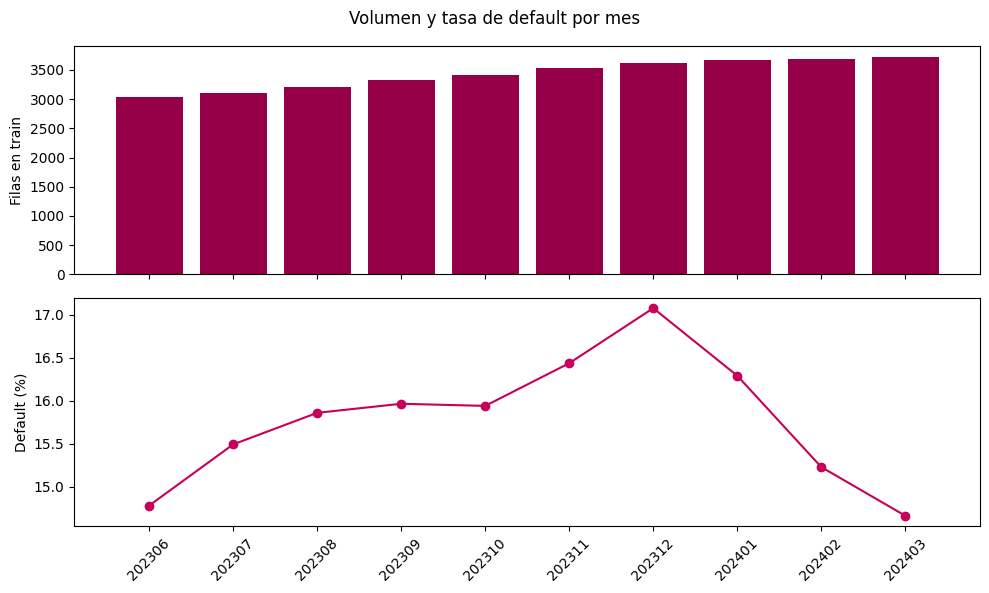

,vacios_pct_sociodemografico_4
CODMES,
202306,79.62
202307,0.26
202308,79.85
202309,80.69
202310,0.15
202311,79.68
202312,0.17
202401,80.28
202402,0.05


In [ ]:
evolucion = train.groupby("CODMES")["TARGET"].agg(filas="size", defaults="sum", tasa="mean")
display(evolucion.assign(tasa_pct=evolucion["tasa"].mul(100).round(2)).drop(columns="tasa"))
print(f"Tasa de default global en train: {train['TARGET'].mean():.2%}")

meses = evolucion.index.astype(str)
fig, ejes = plt.subplots(2, 1, sharex=True, figsize=(10, 6))
ejes[0].bar(meses, evolucion["filas"], color="#960048")
ejes[0].set_ylabel("Filas en train")
ejes[1].plot(meses, evolucion["tasa"].mul(100), color="#c80059", marker="o")
ejes[1].set_ylabel("Default (%)")
ejes[1].tick_params(axis="x", rotation=45)
fig.suptitle("Volumen y tasa de default por mes")
plt.tight_layout()
plt.show()

# Seguimiento de la variable sociodemográfica con vacíos intermitentes.
display(train["SOCIODEMOGRAFICO_4"].isna().groupby(train["CODMES"])
        .mean().mul(100).round(2).to_frame("vacios_pct_sociodemografico_4"))

### 2.4. Qué implica el diagnóstico para el proyecto

**Hallazgo:** el default de train alcanza su mayor nivel en diciembre y desciende en los meses siguientes. El riesgo observado cambia por mes, de modo que un promedio global puede ocultar diferencias temporales.

**Implicancia:** acompañamos la discriminación y el default agregado con seguimiento mensual. Esta revisión permite interpretar las variaciones de la política cuya cobertura se maximiza con el límite global del 8 %.

**Decisión sobre los datos:** conservamos los anticipos y distinguimos los estados sin atrasos y el código especial de apalancamiento. La selección siguiente trabaja con esas representaciones para explicar qué información aporta cada variable.


## Unidad 3. Seleccionar información útil que podamos explicar

**Pregunta:** ¿qué variables permiten representar el comportamiento de pago, el endeudamiento y la trayectoria crediticia con un aporte defendible?

Combinamos interpretación financiera, default por tramos, cobertura, Gini individual, redundancia y aporte adicional al XGBoost dentro de train. Esta revisión construye una **referencia intermedia de 16 variables** a partir de las 45 candidatas.

**Criterio de trabajo:** priorizar información que podamos interpretar y documentar, y contrastar su aporte con los datos. La correlación y la señal individual orientan el análisis; la evaluación conjunta muestra qué añade cada candidata al modelo.

### 3.1. Sentido económico y default por tramo

Para cada candidata revisamos tamaños y default por intervalo o categoría. Separamos anticipos, estados sin atrasos, faltantes y código especial de apalancamiento para interpretar los patrones.

Las sociodemográficas se revisan primero por separado. Más adelante se evalúa la incorporación de SOCIODEMOGRAFICO_1 como categoría sin orden. Sus códigos se mantienen como etiquetas de grupo.


,variable,hipotesis_economica,patron_observado,menor_grupo_con_dato
0,MEDIDA1_MORA_INTERNA_U6M,"Más atraso, mayor default",Cambia de dirección,20
1,MEDIDA1_MORA_INTERNA_U12M,"Más atraso, mayor default",Cambia de dirección,42
2,MEDIDA1_MORA_INTERNA_U1M,"Más atraso, mayor default",Ascendente,596
3,MEDIDA2_MORA_INTERNA_U12M,Revisar definición,Cambia de dirección,399
4,MEDIDA2_MORA_INTERNA_U6M,Revisar definición,Descendente,517
5,MEDIDA3_MORA_INTERNA_U12M,Revisar definición,Cambia de dirección,1876
6,MEDIDA1_APALANCAMIENTO_INTERNO_U6M,Revisar definición,Cambia de dirección,3433
7,MEDIDA2_APALANCAMIENTO_INTERNO_U6M,Revisar definición,Cambia de dirección,1486
8,SOCIODEMOGRAFICO_1,Revisar definición,Comparar categorías,3683
9,MEDIDA2_APALANCAMIENTO_INTERNO_U12M,Revisar definición,Cambia de dirección,1073


,filas,default_pct,distribucion_pct
1.0,10457,18.24,30.46
2.0,2109,12.94,6.14
3.0,236,12.71,0.69
4.0,349,9.17,1.02
5.0,4225,13.02,12.31
6.0,182,8.24,0.53
7.0,367,11.44,1.07
Sin dato,16406,15.67,47.79


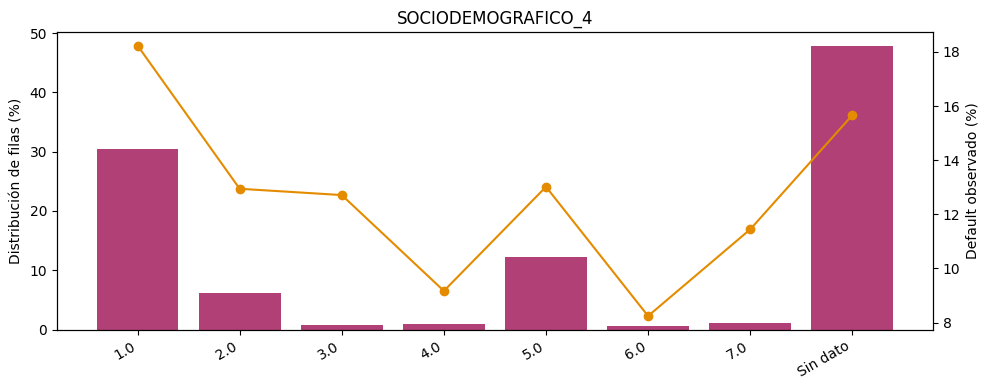

In [ ]:
referencia = {"CODMES", "TARGET", "PROXY_TARGET_6M", "PREDICCION_MODELO_ANTERIOR"}
sociodemograficas = {c for c in train if c.startswith("SOCIODEMOGRAFICO_")}
mora_firmada = {f"MEDIDA1_MORA_INTERNA_U{n}M" for n in (1, 6, 12)}
categoricas = {"SOCIODEMOGRAFICO_1", "SOCIODEMOGRAFICO_2", "SOCIODEMOGRAFICO_4",
               "MEDIDA1_CALIFICACION_SSFF_U60M", "MEDIDA3_TRX_QR_U1M", "MEDIDA6_TRX_APP_U1M"}
candidatas_eda = [c for c in train if c not in referencia and c not in columnas_derivadas_recodificacion]
candidatas_modelo = [c for c in candidatas_eda if c not in sociodemograficas]

def agrupar_variable(datos, variable):
    x = datos[variable]
    if variable in RECOD_MORAS:
        codigo, etiqueta = RECOD_MORAS[variable]
        # Cada mes ordinario conserva su etiqueta; el estado sin atrasos queda aparte.
        return x.map(lambda v: 'Sin dato' if pd.isna(v) else etiqueta if v == codigo else f'Mes {int(v):02d}')
    if variable == RECOD_APAL:
        especial = datos[RECOD_FLAG_APAL].eq(1)
        grupos_apal = pd.qcut(x, 10, duplicates='drop').astype('string')
        return grupos_apal.mask(especial, 'Código especial 333333344').fillna('Sin dato original')
    es_codigo = x.eq(codigos_especiales[variable]) if variable in codigos_especiales else x.isna() & False
    observados = x.mask(es_codigo)
    if variable in mora_firmada:
        grupos = pd.cut(observados, [-np.inf, -1, 0, 7, 15, 30, 60, np.inf],
                         labels=["Anticipado (<0)", "0", "1 a 7", "8 a 15", "16 a 30", "31 a 60", ">60"])
    elif variable in categoricas or observados.nunique() <= 10:
        grupos = pd.Categorical(observados, categories=sorted(observados.dropna().unique()), ordered=True)
    else:
        grupos = pd.qcut(observados, 10, duplicates="drop")
    grupos = pd.Series(grupos, index=x.index).astype("category")
    if len(grupos.cat.categories) == 0 and observados.notna().any():
        grupos = observados.astype("category")
    grupos = grupos.cat.add_categories(["Código especial", "Sin dato"])
    return grupos.mask(es_codigo, "Código especial").fillna("Sin dato")

tablas_sentido = {}
for variable in candidatas_eda:
    grupos = agrupar_variable(train, variable)
    tabla = train["TARGET"].groupby(grupos, observed=True, sort=True).agg(filas="size", default_pct="mean")
    tabla["default_pct"] = tabla["default_pct"].mul(100)
    tabla["distribucion_pct"] = tabla["filas"].div(len(train)).mul(100)
    tablas_sentido[variable] = tabla

resumen_sentido = []
for variable, por_tramo in tablas_sentido.items():
    regulares = por_tramo.drop(index=["Sin dato", "Código especial"], errors="ignore")
    diferencias = regulares["default_pct"].diff().dropna()
    if variable in categoricas or variable in RECOD_MORAS or variable == RECOD_APAL or diferencias.empty:
        patron = "Comparar categorías"
    elif diferencias.eq(0).all():
        patron = "Plano"
    elif diferencias.ge(0).all():
        patron = "Ascendente"
    elif diferencias.le(0).all():
        patron = "Descendente"
    else:
        patron = "Cambia de dirección"
    resumen_sentido.append({
        "variable": variable,
        "hipotesis_economica": "Más atraso, mayor default" if variable in mora_firmada else "Revisar definición",
        "patron_observado": patron,
        "menor_grupo_con_dato": regulares["filas"].min(),
    })
display(pd.DataFrame(resumen_sentido))

# Cambia el nombre para revisar cualquier otra candidata.
variable_sentido = "SOCIODEMOGRAFICO_4"
tabla = tablas_sentido[variable_sentido]
display(tabla.round(2))
fig, ax = plt.subplots(figsize=(10, 4))
pos = np.arange(len(tabla))
ax.bar(pos, tabla["distribucion_pct"], color="#960048", alpha=.75)
ax.set_ylabel("Distribución de filas (%)")
ax.set_xticks(pos, tabla.index.astype(str), rotation=30, ha="right")
ax2 = ax.twinx()
ax2.plot(pos, tabla["default_pct"], color="#e58b00", marker="o")
ax2.set_ylabel("Default observado (%)")
ax.set_title(variable_sentido)
plt.tight_layout()
plt.show()

### 3.2. Redundancia: correlaciones y mapa de Pearson

Revisamos Spearman y Pearson sobre train. El filtro preliminar de Spearman señala pares con correlación absoluta superior a 0,90; el mapa de Pearson muestra los ocho pares de mayor magnitud.

La correlación no mide el aporte adicional al XGBoost ni es una regla automática de descarte. En 3.3 contrastamos las candidatas con validación interna antes de construir la referencia de 16.

In [ ]:
UMBRAL_CORRELACION = 0.90
prioridad_economica = ["MEDIDA1_MORA_INTERNA_U6M"]
exclusiones_justificadas = {
    # "VARIABLE": "motivo documentado",
}

def separar_codigos(datos, columnas):
    x = datos[columnas].copy()
    for col, valor in codigos_especiales.items():
        if col in x:
            x[col] = x[col].mask(x[col].eq(valor))
    return x

def seleccionar_predictores(datos):
    disponibles = [c for c in candidatas_modelo if c not in exclusiones_justificadas]
    x = separar_codigos(datos, disponibles)
    numericas = [c for c in x if c not in categoricas]
    corr = x[numericas].corr(method="spearman", min_periods=300).abs()
    orden = sorted(disponibles, key=lambda c: (
        prioridad_economica.index(c) if c in prioridad_economica else len(prioridad_economica),
        -x[c].notna().sum(), c,
    ))
    elegidas, descartes = [], []
    for col in orden:
        redundante = next((otra for otra in elegidas
                           if col in corr.index and otra in corr.columns
                           and corr.loc[col, otra] > UMBRAL_CORRELACION), None)
        if redundante is None:
            elegidas.append(col)
        else:
            descartes.append({"separada": col, "conservada": redundante,
                               "spearman_absoluto": corr.loc[col, redundante]})
    return elegidas, pd.DataFrame(descartes, columns=["separada", "conservada", "spearman_absoluto"])

seleccionadas, bitacora_correlacion = seleccionar_predictores(train)
display(bitacora_correlacion.round(3))
print(f"Candidatas base: {len(candidatas_modelo)}. Selección inicial: {len(seleccionadas)}.")

,separada,conservada,spearman_absoluto
0,MEDIDA3_MORA_SSFF_U36M,MEDIDA1_MORA_SSFF_U36M,0.937
1,MEDIDA2_APALANCAMIENTO_SSFF_U60M,MEDIDA2_APALANCAMIENTO_SSFF_U36M,0.913
2,MEDIDA1_PRODUCTOS_SSFF_U1M,MEDIDA2_PRODUCTOS_SSFF_U3M,0.953


Candidatas base: 41. Selección inicial: 38.


**Mapa de Pearson de los pares con mayor correlación**

Seleccionamos los ocho pares con mayor valor absoluto de Pearson entre las candidatas numéricas. El mapa cruza todas las variables que aparecen en esos pares. El color y el número conservan el signo de la correlación. Cada par usa las filas de train con dato en ambas variables, con un mínimo de 300 filas. Los códigos especiales se separan antes del cálculo.

La tabla indica qué pares entraron en la selección del mapa. El filtro de variables del bloque anterior sigue utilizando Spearman.

,variable_1,variable_2,pearson,filas_con_dato
0,MEDIDA1_PRODUCTOS_SSFF_U1M,MEDIDA2_PRODUCTOS_SSFF_U3M,0.951,33289
1,MEDIDA2_APALANCAMIENTO_SSFF_U36M,MEDIDA2_APALANCAMIENTO_SSFF_U60M,0.900,33519
2,MEDIDA1_MORA_SSFF_U36M,MEDIDA1_MORA_SSFF_U12M,0.868,34331
3,MEDIDA1_MORA_INTERNA_U6M,MEDIDA1_MORA_INTERNA_U12M,0.810,34331
4,MEDIDA2_APALANCAMIENTO_INTERNO_U6M,MEDIDA2_APALANCAMIENTO_INTERNO_U12M,0.808,34331
5,MEDIDA1_APALANCAMIENTO_SSFF_U36M,MEDIDA1_APALANCAMIENTO_SSFF_U6M,0.775,33289
6,MEDIDA3_APALANCAMIENTO_SSFF_U12M,MEDIDA3_APALANCAMIENTO_SSFF_U6M,0.772,34331
7,MEDIDA1_DESAPALANCAMIENTO_INTERNO_U6M,MEDIDA1_DESAPALANCAMIENTO_INTERNO_U12M,0.757,32295


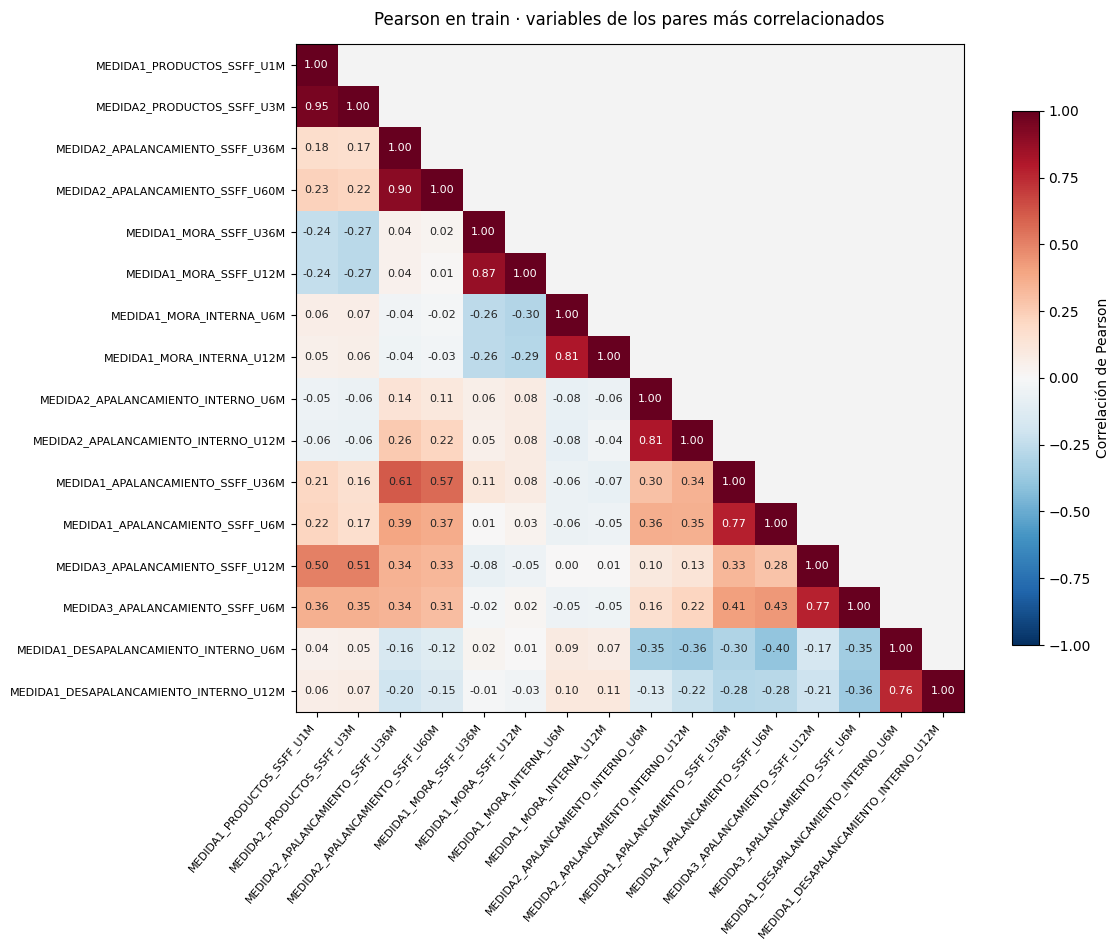

In [ ]:
N_PARES_PEARSON = 8
numericas_pearson = [col for col in candidatas_modelo if col not in categoricas]
datos_pearson = separar_codigos(train, numericas_pearson)
correlacion_pearson = datos_pearson.corr(method="pearson", min_periods=300)

# Tomar cada par una sola vez y ordenar por magnitud, conservando el signo.
disponibles_pearson = datos_pearson.notna().astype("int64")
conteos_pares = disponibles_pearson.T @ disponibles_pearson
filas_pearson = []
for i, a in enumerate(numericas_pearson):
    for b in numericas_pearson[i + 1:]:
        r = correlacion_pearson.loc[a, b]
        if pd.notna(r):
            filas_pearson.append({
                "variable_1": a, "variable_2": b, "pearson": r,
                "magnitud": abs(r), "filas_con_dato": conteos_pares.loc[a, b],
            })

pares_pearson = (
    pd.DataFrame(filas_pearson).sort_values("magnitud", ascending=False)
    .head(N_PARES_PEARSON).reset_index(drop=True)
)
display(pares_pearson.drop(columns="magnitud").round({"pearson": 3}))

variables_mapa = list(dict.fromkeys(
    pares_pearson[["variable_1", "variable_2"]].to_numpy().ravel()
))
mapa_pearson = correlacion_pearson.loc[variables_mapa, variables_mapa]

# Mostrar solo una mitad de la matriz para evitar repetir valores.
valores = mapa_pearson.to_numpy()
mascara = np.triu(np.ones(valores.shape, dtype=bool), k=1)
matriz = np.ma.masked_where(mascara | np.isnan(valores), valores)
n = len(variables_mapa)
fig, ax = plt.subplots(figsize=(max(9, n * .78), max(6, n * .60)))
colores = plt.get_cmap("RdBu_r").copy()
colores.set_bad("#f3f3f3")
imagen = ax.imshow(matriz, vmin=-1, vmax=1, cmap=colores)
ax.set_xticks(range(n), variables_mapa, rotation=50, ha="right", fontsize=8)
ax.set_yticks(range(n), variables_mapa, fontsize=8)
for i in range(n):
    for j in range(i + 1):
        r = valores[i, j]
        if np.isfinite(r):
            ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(r) >= .65 else "#242424")
fig.colorbar(imagen, ax=ax, label="Correlación de Pearson", shrink=.8)
ax.set_title("Pearson en train · variables de los pares más correlacionados", pad=14)
fig.tight_layout()
plt.show()

### 3.3. Aporte de las candidatas dentro de train

Partimos de 12 variables del análisis previo y añadimos, una a la vez, las 19 en revisión al mismo XGBoost. Comparamos tres pliegues estratificados por CODMES × TARGET y seis cortes cronológicos internos, de octubre de 2023 a marzo de 2024.

Las predicciones fuera de pliegue (OOF) se generan sin usar la fila evaluada en el ajuste de ese pliegue. Los cortes cronológicos son retrospectivos: no corrigen por sí solos los 12 meses que tarda en madurar TARGET. El modelo, sus tratamientos y parámetros permanecen comparables durante esta prueba.

In [ ]:
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from xgboost import XGBClassifier

variables_base12 = [
    'MEDIDA1_MORA_INTERNA_U6M',
    'MEDIDA2_MORA_SSFF_U6M',
    'MEDIDA1_ANTIGUEDAD_SSFF',
    'MEDIDA1_APALANCAMIENTO_INTERNO_U6M',
    'MEDIDA1_MORA_SSFF_U36M',
    'MEDIDA1_APALANCAMIENTO_SSFF_U36M',
    'MEDIDA3_APALANCAMIENTO_SSFF_U12M',
    'MEDIDA1_PRODUCTOS_SSFF_U1M',
    'MEDIDA1_CALIFICACION_SSFF_U60M',
    'MEDIDA1_DESAPALANCAMIENTO_INTERNO_U6M',
    'MEDIDA2_CALIFICACION_SSFF_U60M',
    'MEDIDA2_APALANCAMIENTO_SSFF_U60M',
]
variables_revision = [
    'MEDIDA1_MORA_INTERNA_U12M',
    'MEDIDA3_MORA_INTERNA_U12M',
    'MEDIDA2_APALANCAMIENTO_INTERNO_U6M',
    'MEDIDA2_APALANCAMIENTO_INTERNO_U12M',
    'MEDIDA1_DESAPALANCAMIENTO_SSFF_U12M',
    'MEDIDA1_ENTIDADES_SSFF_U12M',
    'MEDIDA1_LINEA_TARJETACREDITO',
    'MEDIDA1_TRX_CASHIN_U3M',
    'MEDIDA2_TRX_TRANSFER_U1M',
    'MEDIDA1_MORA_INTERNA_U1M',
    'MEDIDA2_MORA_INTERNA_U12M',
    'MEDIDA2_MORA_INTERNA_U6M',
    'SOCIODEMOGRAFICO_1',
    'SOCIODEMOGRAFICO_3',
    'MEDIDA3_APALANCAMIENTO_INTERNO_U1M',
    'MEDIDA1_MORA_SSFF_U12M',
    'MEDIDA1_APALANCAMIENTO_SSFF_U6M',
    'MEDIDA3_APALANCAMIENTO_SSFF_U6M',
    'MEDIDA1_DESAPALANCAMIENTO_INTERNO_U12M',
]
descartes_previos = [
    'SOCIODEMOGRAFICO_4',
    'MEDIDA1_AHORRO',
    'MEDIDA2_MORA_SSFF_U36M',
    'MEDIDA2_APALANCAMIENTO_SSFF_U36M',
    'MEDIDA2_APALANCAMIENTO_SSFF_U12M',
    'DEUDA_PROMEDIO_SSFF',
    'MEDIDA4_DEUDA_SSFF_U1M',
    'MEDIDA3_TRX_QR_U1M',
    'MEDIDA3_MORA_SSFF_U36M',
    'MEDIDA4_TRX_DEBITO_U1M',
    'MEDIDA5_TRX_ECOM_U1M',
    'MEDIDA6_TRX_APP_U1M',
    'SOCIODEMOGRAFICO_2',
    'MEDIDA2_PRODUCTOS_SSFF_U3M',
]

variables_candidatas = variables_base12 + variables_revision + descartes_previos
assert len(set(variables_candidatas)) == 45
assert set(variables_candidatas) == set(train.columns) - {
    "CODMES", "TARGET", "PREDICCION_MODELO_ANTERIOR", "PROXY_TARGET_6M",
    RECOD_FLAG_APAL,
}

linea = "MEDIDA1_LINEA_TARJETACREDITO"
mora_mes = "MEDIDA1_MORA_INTERNA_U1M"
apal_mes = "MEDIDA3_APALANCAMIENTO_INTERNO_U1M"
socio = "SOCIODEMOGRAFICO_1"
antiguedad = "MEDIDA1_ANTIGUEDAD_SSFF"
indicador_linea = linea + "__faltante"
indicador_apal = RECOD_FLAG_APAL
marcadores_seleccion = {
    "MEDIDA2_MORA_INTERNA_U6M": 99,
    "MEDIDA2_MORA_INTERNA_U12M": 99,
}
niveles_nominales = {
    "MEDIDA1_CALIFICACION_SSFF_U60M": [0, 1, 2, 3, 4],
    socio: [1, 2, 3, 4],
    "SOCIODEMOGRAFICO_2": [1, 2, 3, 4, 7, 8],
    "SOCIODEMOGRAFICO_4": [1, 2, 3, 4, 5, 6, 7],
}
hipotesis_edad = "SOCIODEMOGRAFICO_3"

def preparar_xgb(datos, columnas, linea_como_indicador=True):
    bloques = []
    for col in columnas:
        if col in (indicador_linea, linea) and (linea_como_indicador or col == indicador_linea):
            bloques.append(datos[linea].isna().astype("int8").rename(indicador_linea))
        elif col == indicador_apal:
            bloques.append(datos[indicador_apal].rename(indicador_apal))
        elif col == apal_mes:
            # La recodificación temprana ya separó la magnitud ordinaria y el flag.
            bloques.extend([datos[apal_mes], datos[indicador_apal].rename(indicador_apal)])
        elif col in niveles_nominales:
            categorias = pd.Categorical(datos[col], categories=niveles_nominales[col])
            codificada = pd.get_dummies(categorias, prefix=col, dummy_na=True, dtype="int8")
            codificada.index = datos.index
            bloques.append(codificada)
        elif col in marcadores_seleccion:
            es_codigo = datos[col].eq(marcadores_seleccion[col])
            bloques.extend([datos[col].mask(es_codigo), es_codigo.astype("int8").rename(col + "__codigo_especial")])
        elif col == hipotesis_edad:
            bloques.append(datos[col].mask(datos[col].eq(1)))
        else:
            bloques.append(datos[col])
    return pd.concat(bloques, axis=1)

def nuevo_xgb():
    return XGBClassifier(
        n_estimators=220, max_depth=3, learning_rate=0.05,
        min_child_weight=15, subsample=0.8, colsample_bytree=0.8,
        objective="binary:logistic", eval_metric="auc", tree_method="hist",
        n_jobs=2, random_state=42,
    )

def gini(real, score):
    return 2 * roc_auc_score(real, score) - 1

y_seleccion = train["TARGET"].astype(int).to_numpy()
mes_seleccion = train["CODMES"].to_numpy()
estrato_seleccion = train["CODMES"].astype(str) + "_" + train["TARGET"].astype(str)
cv_seleccion = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
pliegues_seleccion = list(cv_seleccion.split(train, estrato_seleccion))
meses_seleccion = np.sort(np.unique(mes_seleccion))[4:]
cortes_seleccion = [
    (np.flatnonzero(mes_seleccion < mes), np.flatnonzero(mes_seleccion == mes))
    for mes in meses_seleccion
]

def evaluar_en_train(columnas, linea_como_indicador=True, temporal=True):
    x = preparar_xgb(train, columnas, linea_como_indicador)
    pred_oof = np.full(len(x), np.nan)
    gini_pliegues = []
    for ajuste, evaluacion in pliegues_seleccion:
        modelo = nuevo_xgb()
        modelo.fit(x.iloc[ajuste], y_seleccion[ajuste])
        pred = modelo.predict_proba(x.iloc[evaluacion])[:, 1]
        pred_oof[evaluacion] = pred
        gini_pliegues.append(gini(y_seleccion[evaluacion], pred))
    assert np.isfinite(pred_oof).all()
    gini_temporal = []
    if temporal:
        for ajuste, evaluacion in cortes_seleccion:
            modelo = nuevo_xgb()
            modelo.fit(x.iloc[ajuste], y_seleccion[ajuste])
            pred = modelo.predict_proba(x.iloc[evaluacion])[:, 1]
            gini_temporal.append(gini(y_seleccion[evaluacion], pred))
    return {"pred_oof": pred_oof, "gini_oof": gini(y_seleccion, pred_oof),
            "gini_pliegues": np.array(gini_pliegues), "gini_temporal": np.array(gini_temporal)}

**Señal individual y correlación.** Para numéricas, el Gini firmado indica la dirección de asociación con default. Se calcula con la representación numérica vigente; en las dos moras externas incluye el estado recodificado sin atrasos. En el apalancamiento el código especial está separado de la magnitud. Para categorías se usa la tasa de default de cada grupo estimada fuera de pliegue. Los códigos especiales y los vacíos se reportan por separado. Spearman identifica la variable de la base de 12 que más se parece a cada candidata numérica en el orden de sus valores. El Gini individual y la correlación orientan la revisión.

In [ ]:
datos_ordinarios = train[variables_candidatas].copy()
for col, codigo in marcadores_seleccion.items():
    datos_ordinarios[col] = datos_ordinarios[col].mask(datos_ordinarios[col].eq(codigo))
datos_ordinarios[hipotesis_edad] = datos_ordinarios[hipotesis_edad].mask(
    datos_ordinarios[hipotesis_edad].eq(1)
)
numericas_seleccion = [c for c in variables_candidatas if c not in niveles_nominales]
correlaciones_seleccion = datos_ordinarios[numericas_seleccion].corr(method="spearman", min_periods=300)
perfil_seleccion = []
for col in variables_candidatas:
    bruto = train[col]
    score = datos_ordinarios[col].to_numpy(copy=True)
    if col in niveles_nominales:
        grupos_col = bruto.astype("string").fillna("Sin dato")
        score = np.full(len(train), np.nan)
        for ajuste, evaluacion in pliegues_seleccion:
            tasa = pd.Series(y_seleccion[ajuste]).groupby(grupos_col.iloc[ajuste].to_numpy()).agg(["sum", "size"])
            media = y_seleccion[ajuste].mean()
            tasa_ajustada = (tasa["sum"] + 20 * media) / (tasa["size"] + 20)
            score[evaluacion] = grupos_col.iloc[evaluacion].map(tasa_ajustada).fillna(media)
    observada = pd.notna(score)
    r = pd.Series(dtype=float)
    if col in correlaciones_seleccion:
        referencias = [c for c in variables_base12 if c != col and c in correlaciones_seleccion]
        r = correlaciones_seleccion.loc[col, referencias].dropna()
    cercana = r.abs().idxmax() if len(r) else None
    perfil_seleccion.append({
        "variable": col,
        "gini_individual": gini(y_seleccion[observada], score[observada]),
        "filas_gini": int(observada.sum()),
        "faltantes_pct": 100 * bruto.isna().mean(),
        "codigos_especiales": (int(train[RECOD_FLAG_APAL].sum()) if col == RECOD_APAL else
                              int(bruto.eq(marcadores_seleccion[col]).sum()) if col in marcadores_seleccion else 0),
        "estado_sin_atrasos": int(bruto.eq(RECOD_MORAS[col][0]).sum()) if col in RECOD_MORAS else 0,
        "mas_correlacionada_en_base": cercana,
        "spearman": r[cercana] if cercana else np.nan,
    })
perfil_seleccion = pd.DataFrame(perfil_seleccion).set_index("variable")
display(perfil_seleccion.loc[variables_revision].round(3))

,gini_individual,filas_gini,faltantes_pct,codigos_especiales,estado_sin_atrasos,mas_correlacionada_en_base,spearman
variable,,,,,,,
MEDIDA1_MORA_INTERNA_U12M,0.321,34331,0.000,0,0,MEDIDA1_MORA_INTERNA_U6M,0.895
MEDIDA3_MORA_INTERNA_U12M,0.183,34331,0.000,0,0,MEDIDA1_MORA_INTERNA_U6M,0.841
MEDIDA2_APALANCAMIENTO_INTERNO_U6M,0.129,34331,0.000,0,0,MEDIDA1_APALANCAMIENTO_INTERNO_U6M,0.786
MEDIDA2_APALANCAMIENTO_INTERNO_U12M,0.126,34331,0.000,0,0,MEDIDA1_APALANCAMIENTO_INTERNO_U6M,0.614
MEDIDA1_DESAPALANCAMIENTO_SSFF_U12M,-0.171,34331,0.000,0,0,MEDIDA2_CALIFICACION_SSFF_U60M,0.461
MEDIDA1_ENTIDADES_SSFF_U12M,0.065,34331,0.000,0,0,MEDIDA3_APALANCAMIENTO_SSFF_U12M,0.452
MEDIDA1_LINEA_TARJETACREDITO,-0.063,9790,71.483,0,0,MEDIDA1_PRODUCTOS_SSFF_U1M,0.312
MEDIDA1_TRX_CASHIN_U3M,0.072,29250,14.800,0,0,MEDIDA1_MORA_INTERNA_U6M,0.019
MEDIDA2_TRX_TRANSFER_U1M,0.192,18822,45.175,0,0,MEDIDA2_MORA_SSFF_U6M,0.023


**Aporte al modelo.** La tabla compara cada variable en revisión con el XGBoost de 12 variables. Un cambio de +1 punto equivale a +0,01 en la escala del Gini. Las diferencias temporales se calculan mes por mes y se promedian. Para la línea de tarjeta, esta primera comparación usa el importe. La siguiente prueba compara el importe con un indicador de tener o no crédito.


In [ ]:
resultado_base12 = evaluar_en_train(variables_base12)
resultado_revision = {}
for col in variables_revision:
    resultado_revision[col] = evaluar_en_train(variables_base12 + [col], linea_como_indicador=False)

def resumir_aporte(resultado, referencia):
    diferencias = 100 * (resultado["gini_temporal"] - referencia["gini_temporal"])
    return {"delta_gini_oof_puntos": 100 * (resultado["gini_oof"] - referencia["gini_oof"]),
            "delta_gini_temporal_puntos": diferencias.mean(),
            "pliegues_mejoran": int((resultado["gini_pliegues"] > referencia["gini_pliegues"]).sum()),
            "meses_mejoran": int((diferencias > 0).sum())}

aporte_revision = pd.DataFrame.from_dict(
    {col: resumir_aporte(r, resultado_base12) for col, r in resultado_revision.items()}, orient="index"
)
aporte_revision.index.name = "variable"
display(aporte_revision.sort_values("delta_gini_temporal_puntos", ascending=False).round(3))

### 3.4. Elegir una representación que facilite la explicación

La línea de crédito se compara como importe y como indicador de tener o no crédito. En la codificación utilizada, **1 = sin crédito** y **0 = con crédito**. Esta representación permite explicar qué condición utiliza el modelo, además de medir si el importe aporta información adicional.

También revisamos el aporte de mora U1M frente a U6M, el apalancamiento U1M junto con su código especial, la antigüedad y la incorporación de SOCIODEMOGRAFICO_1 como categoría sin orden.

**Decisión:** conservar tratamientos que distingan situaciones financieras y mantengan el aporte observado. Las tablas siguientes documentan la comparación antes de cerrar la referencia de 16.


In [ ]:
tabla_linea = train.assign(linea_registrada=train[linea].notna()).groupby("linea_registrada")["TARGET"]
tabla_linea = tabla_linea.agg(filas="size", default_pct="mean")
tabla_linea["default_pct"] *= 100
display(tabla_linea.round(2))

tramo_mora = train.loc[train["MEDIDA1_MORA_INTERNA_U6M"].between(1, 7), [mora_mes, "TARGET"]].copy()
tramo_mora["pago_en_U1M"] = np.select(
    [tramo_mora[mora_mes].lt(0), tramo_mora[mora_mes].eq(0), tramo_mora[mora_mes].gt(0)],
    ["Anticipado", "Cero", "Positivo"], default="Sin dato",
)
tabla_mora = tramo_mora.groupby("pago_en_U1M")["TARGET"].agg(filas="size", default_pct="mean")
tabla_mora["default_pct"] *= 100
display(tabla_mora.round(2))

compacto15 = variables_base12 + [mora_mes, linea, apal_mes]
resultado_compacto15 = evaluar_en_train(compacto15)
resultado_final16 = evaluar_en_train(compacto15 + [socio])
comparaciones_puntuales = {
    "Indicador de línea vs base de 12": (evaluar_en_train(variables_base12 + [linea]), resultado_base12),
    "Importe de línea vs indicador en el modelo de 15": (
        evaluar_en_train(compacto15, linea_como_indicador=False), resultado_compacto15),
    "Apalancamiento completo vs solo su código especial": (
        resultado_compacto15, evaluar_en_train(variables_base12 + [mora_mes, linea, indicador_apal])),
    "Antigüedad incluida vs excluida en el modelo de 15": (
        resultado_compacto15, evaluar_en_train([col for col in compacto15 if col != antiguedad])),
    "Sociodemográfico 1 añadido al modelo de 15": (resultado_final16, resultado_compacto15),
    "Abonos añadidos al modelo de 15": (
        evaluar_en_train(compacto15 + ["MEDIDA1_TRX_CASHIN_U3M"]), resultado_compacto15),
}
display(pd.DataFrame.from_dict(
    {nombre: resumir_aporte(r, ref) for nombre, (r, ref) in comparaciones_puntuales.items()}, orient="index"
).round(3))
display(pd.DataFrame({
    "Modelo de 12": 100 * resultado_base12["gini_temporal"],
    "Modelo de 15": 100 * resultado_compacto15["gini_temporal"],
    "Modelo de 16": 100 * resultado_final16["gini_temporal"],
}, index=pd.Index(meses_seleccion, name="CODMES")).round(2))

### 3.5. Referencia de 16 variables y registro de descartes

La primera selección conserva 16 de las 45 candidatas. La tabla deja los motivos y tratamientos tanto de las conservadas como de las excluidas. Es una referencia intermedia: la sensibilidad de la Unidad 4 y la comparación de la Unidad 5 llevan a las 13 finales.

Se conservan anticipos; mora externa U36M utiliza 37 como estado sin atrasos, y U12M utiliza 13. El apalancamiento U1M separa magnitud y código especial. La línea de crédito se representa como **sin crédito = 1 / con crédito = 0**. SOCIODEMOGRAFICO_1 se conserva como categoría sin orden, con un grupo propio para faltantes.


In [ ]:
variables_finales = compacto15 + [socio]
variables_fuera = [
    'SOCIODEMOGRAFICO_4',
    'MEDIDA1_AHORRO',
    'MEDIDA2_MORA_SSFF_U36M',
    'MEDIDA2_APALANCAMIENTO_SSFF_U36M',
    'MEDIDA2_APALANCAMIENTO_SSFF_U12M',
    'DEUDA_PROMEDIO_SSFF',
    'MEDIDA4_DEUDA_SSFF_U1M',
    'MEDIDA3_TRX_QR_U1M',
    'MEDIDA3_MORA_SSFF_U36M',
    'MEDIDA4_TRX_DEBITO_U1M',
    'MEDIDA5_TRX_ECOM_U1M',
    'MEDIDA6_TRX_APP_U1M',
    'SOCIODEMOGRAFICO_2',
    'MEDIDA2_PRODUCTOS_SSFF_U3M',
    'MEDIDA1_MORA_INTERNA_U12M',
    'MEDIDA3_MORA_INTERNA_U12M',
    'MEDIDA2_APALANCAMIENTO_INTERNO_U6M',
    'MEDIDA2_APALANCAMIENTO_INTERNO_U12M',
    'MEDIDA1_DESAPALANCAMIENTO_SSFF_U12M',
    'MEDIDA1_ENTIDADES_SSFF_U12M',
    'MEDIDA1_TRX_CASHIN_U3M',
    'MEDIDA2_TRX_TRANSFER_U1M',
    'MEDIDA2_MORA_INTERNA_U12M',
    'MEDIDA2_MORA_INTERNA_U6M',
    'SOCIODEMOGRAFICO_3',
    'MEDIDA1_MORA_SSFF_U12M',
    'MEDIDA1_APALANCAMIENTO_SSFF_U6M',
    'MEDIDA3_APALANCAMIENTO_SSFF_U6M',
    'MEDIDA1_DESAPALANCAMIENTO_INTERNO_U12M',
]
motivos_seleccion = {
    'MEDIDA1_MORA_INTERNA_U6M': 'Mora interna de seis meses con señal fuerte. Conserva los anticipos.',
    'MEDIDA2_MORA_SSFF_U6M': 'Medida de mora reciente en el sistema financiero.',
    'MEDIDA1_ANTIGUEDAD_SSFF': 'Antigüedad crediticia con cobertura alta y aporte temporal modesto.',
    'MEDIDA1_APALANCAMIENTO_INTERNO_U6M': 'Medida de endeudamiento interno de seis meses.',
    'MEDIDA1_MORA_SSFF_U36M': 'Se prioriza la ventana de 36 meses frente a la de 12.',
    'MEDIDA1_APALANCAMIENTO_SSFF_U36M': 'Ventana de 36 meses con mayor señal que su variante U6M.',
    'MEDIDA3_APALANCAMIENTO_SSFF_U12M': 'Medida de 12 meses con cobertura completa y mayor señal que U6M.',
    'MEDIDA1_PRODUCTOS_SSFF_U1M': 'Se prioriza frente a la medida de productos de tres meses.',
    'MEDIDA1_CALIFICACION_SSFF_U60M': 'Calificación categórica con diferencias en default por nivel.',
    'MEDIDA1_DESAPALANCAMIENTO_INTERNO_U6M': 'Se prioriza una ventana interna de reducción de deuda.',
    'MEDIDA2_CALIFICACION_SSFF_U60M': 'Medida de calificación con asociación inversa con el default.',
    'MEDIDA2_APALANCAMIENTO_SSFF_U60M': 'Se prioriza sobre su variante U36M por mayor señal.',
    'MEDIDA1_MORA_INTERNA_U12M': 'Solapamiento con mora U6M. Añade poca señal y sustituirla reduce el Gini.',
    'MEDIDA3_MORA_INTERNA_U12M': 'Solapamiento con otras medidas de mora interna y aporte temporal pequeño.',
    'MEDIDA2_APALANCAMIENTO_INTERNO_U6M': 'Comparte ventana con una medida de endeudamiento interno ya incluida.',
    'MEDIDA2_APALANCAMIENTO_INTERNO_U12M': 'Aporte temporal pequeño frente a las medidas internas incluidas.',
    'MEDIDA1_DESAPALANCAMIENTO_SSFF_U12M': 'Dirección compatible con reducción de deuda y aporte marginal bajo.',
    'MEDIDA1_ENTIDADES_SSFF_U12M': 'La señal adicional es pequeña frente a productos y endeudamiento.',
    'MEDIDA1_LINEA_TARJETACREDITO': 'Se conserva tener o no crédito (1 = sin crédito; 0 = con crédito). El importe agrega poco.',
    'MEDIDA1_TRX_CASHIN_U3M': 'Abonos con aporte limitado sobre el compacto. Primera reserva por parsimonia.',
    'MEDIDA2_TRX_TRANSFER_U1M': 'El aporte al mezclar los meses se revierte en los cortes cronológicos.',
    'MEDIDA1_MORA_INTERNA_U1M': 'Complementa U6M al distinguir comportamiento de pago reciente.',
    'MEDIDA2_MORA_INTERNA_U12M': 'El código 99 predomina y el aporte temporal sobre la base es negativo.',
    'MEDIDA2_MORA_INTERNA_U6M': 'Aporte limitado y definición de la recencia ambigua entre ventanas.',
    'SOCIODEMOGRAFICO_1': 'Se conserva por su aporte predictivo. Los códigos se tratan como categorías.',
    'SOCIODEMOGRAFICO_3': 'Valores compatibles con edad como hipótesis. Su aporte temporal es pequeño.',
    'MEDIDA3_APALANCAMIENTO_INTERNO_U1M': 'Los valores ordinarios aportan junto al indicador de código especial.',
    'MEDIDA1_MORA_SSFF_U12M': 'Coincide con U36M en valores ordinarios compartidos y aporta poco al añadirla.',
    'MEDIDA1_APALANCAMIENTO_SSFF_U6M': 'Solapamiento con U36M y caída ligera de Gini temporal.',
    'MEDIDA3_APALANCAMIENTO_SSFF_U6M': 'La medida de 12 meses cubre el concepto. U6M no mejora la prueba temporal.',
    'MEDIDA1_DESAPALANCAMIENTO_INTERNO_U12M': 'Aporte temporal pequeño y solapamiento con desapalancamiento interno U6M.',
    'SOCIODEMOGRAFICO_4': 'Disponibilidad muy variable por mes y códigos sin interpretación económica.',
    'MEDIDA1_AHORRO': 'Cobertura muy baja, con 416 observaciones disponibles en train.',
    'MEDIDA2_MORA_SSFF_U36M': 'Solapamiento fuerte con otra medida de mora externa de 36 meses.',
    'MEDIDA2_APALANCAMIENTO_SSFF_U36M': 'Alta redundancia con la variante de 60 meses.',
    'MEDIDA2_APALANCAMIENTO_SSFF_U12M': 'Se priorizan las medidas de apalancamiento con mayor señal.',
    'DEUDA_PROMEDIO_SSFF': 'Patrón inverso estable de interpretación difícil con la definición disponible.',
    'MEDIDA4_DEUDA_SSFF_U1M': 'Construcción de la medida desconocida y asociación no monótona.',
    'MEDIDA3_TRX_QR_U1M': 'Cobertura muy baja, con 697 observaciones disponibles en train.',
    'MEDIDA3_MORA_SSFF_U36M': 'Solapamiento fuerte con otra medida de mora externa de 36 meses.',
    'MEDIDA4_TRX_DEBITO_U1M': 'Señal univariada baja.',
    'MEDIDA5_TRX_ECOM_U1M': 'Señal univariada prácticamente nula.',
    'MEDIDA6_TRX_APP_U1M': 'Tasa de default casi igual en los dos valores observados.',
    'SOCIODEMOGRAFICO_2': 'Señal categórica baja y códigos difíciles de interpretar.',
    'MEDIDA2_PRODUCTOS_SSFF_U3M': 'Alta redundancia con la medida de productos U1M.',
}

assert len(variables_finales) == 16 and len(variables_fuera) == 29
assert set(variables_finales).isdisjoint(variables_fuera)
assert set(variables_finales + variables_fuera) == set(variables_candidatas)
assert set(variables_finales) == set(compacto15 + [socio])

registro_decision = pd.DataFrame([
    {"variable": col, "decision": estado, "motivo": motivos_seleccion[col]}
    for estado, columnas in [("Se queda", variables_finales), ("Sale", variables_fuera)]
    for col in columnas
]).set_index("variable")
registro_decision = registro_decision.join(perfil_seleccion).join(aporte_revision)
columnas_decision = ["decision", "gini_individual", "delta_gini_temporal_puntos", "motivo"]
display(registro_decision.loc[variables_finales, columnas_decision].round(3).fillna("—"))
display(registro_decision.loc[variables_fuera, columnas_decision].round(3).fillna("—"))


### 3.6. Primera comprobación: 45 candidatas frente a 16

Comparamos las predicciones OOF de train de las 45 candidatas con la referencia de 16. Se muestran Gini, precisión promedio y Brier. Esta referencia exploratoria de 45 usa el importe de línea de tarjeta; la comparación homogénea posterior de la Unidad 5 usa el indicador para todas las variantes.

**Conclusión:** la referencia de 16 reúne información de pago, endeudamiento, antigüedad y perfil. La siguiente unidad comprueba cuánto cuesta retirar tres entradas para facilitar la explicación del modelo final.


In [ ]:
resultado_todas = evaluar_en_train(variables_candidatas, linea_como_indicador=False, temporal=False)
pred_oof = pd.DataFrame({
    "Todas las candidatas": resultado_todas["pred_oof"],
    "Seleccionado (16 variables)": resultado_final16["pred_oof"],
}, index=train.index)

comparacion_xgb = pd.DataFrame([
    {"variante": nombre, "Gini": gini(y_seleccion, pred_oof[nombre]),
     "Precision_promedio": average_precision_score(y_seleccion, pred_oof[nombre]),
     "Brier": brier_score_loss(y_seleccion, pred_oof[nombre])}
    for nombre in pred_oof
])
display(comparacion_xgb.round(4))

**Paso a la sensibilidad.** Tener una variable con sentido financiero no implica que debamos conservar todas sus ventanas o medidas. Ahora evaluamos cuáles aportan información adicional cuando las demás ya están presentes.


## Unidad 4. Medir el costo de simplificar para explicar mejor

**Pregunta:** ¿cuánta capacidad predictiva se pierde al retirar tres variables de la referencia?

La propuesta de 13 busca facilitar la explicación y documentación del modelo. Retiramos una variable de origen por vez de la referencia de 16 y después evaluamos directamente la exclusión conjunta de tres candidatas. Se mantienen train, tratamientos y parámetros.

**Cómo usamos la evidencia:** la sensibilidad cuantifica el costo de la propuesta y sus diferencias entre meses. Las pérdidas individuales no se suman y cada variable se retira junto con sus columnas derivadas.

La ruta es retirada individual → retirada conjunta → propuesta de 13 → contraste de desempeño en la Unidad 5. Las guardas conservadoras se conservan para que la elección por explicabilidad incluya sus costos y limitaciones.


### 4.1. Referencia y criterios para interpretar la sensibilidad

El Gini se calcula como `2 × AUC − 1`. Recalculamos la referencia de 16 variables y todas las variantes en la misma ejecución:

**Cambio en puntos de Gini = 100 × (Gini sin la variable − Gini de referencia).**

Negativo significa pérdida al retirarla; positivo significa mejora. La revisión conservadora utiliza las siguientes guardas como diagnóstico:

| Guarda | Condición |
|---|---|
| Resultado OOF y promedio temporal | Ninguno pierde más de 0,2 puntos de Gini. |
| Consistencia entre particiones | Al menos 2 de 3 pliegues y 4 de 6 meses no pierden más de 0,2 puntos. |
| Mes más desfavorable | No pierde más de 0,5 puntos. |
| Interpretación | Revisar el sentido económico y el tratamiento de cada variable. |

Los márgenes son criterios prácticos, no pruebas de equivalencia ni de significancia. Las guardas se conservan y sus incumplimientos se muestran completos. Una pérdida pequeña en promedio puede coexistir con un incumplimiento mensual; ese intercambio debe explicarse antes de decidir.

La Unidad 5 contrasta la propuesta de 13 con las alternativas de 16 y 15. La explicabilidad es la prioridad de la elección; el Gini y la estabilidad permiten valorar el desempeño que se conserva y las diferencias que se aceptan. El modelo de 45 permanece como referencia exploratoria.


In [ ]:
import platform as sens_platform
import sklearn as sens_sklearn
import xgboost as sens_xgboost

sens_requeridos = ['train', 'train_raw', 'variables_finales', 'preparar_xgb',
                   'nuevo_xgb', 'evaluar_en_train', 'pliegues_seleccion',
                   'cortes_seleccion', 'meses_seleccion', 'motivos_seleccion']
sens_faltantes = [sens_nombre for sens_nombre in sens_requeridos if sens_nombre not in globals()]
if sens_faltantes:
    raise RuntimeError('Ejecuta primero las unidades anteriores. Faltan: ' + ', '.join(sens_faltantes))

sens_variables_base = list(variables_finales)
sens_margen_puntos = 0.2
sens_guarda_mes_puntos = 0.5
assert len(sens_variables_base) == len(set(sens_variables_base)) == 16
assert len(pliegues_seleccion) == 3 and len(cortes_seleccion) == 6
assert np.array_equal(meses_seleccion, [202310, 202311, 202312, 202401, 202402, 202403])
pd.testing.assert_frame_equal(train, train_raw)
sens_indice_inicial = train.index.copy()
sens_huella_inicial = pd.util.hash_pandas_object(train, index=True).copy()

# Identificar las columnas que genera cada variable original.
sens_bloques = {sens_variable: list(preparar_xgb(train, [sens_variable]).columns)
               for sens_variable in sens_variables_base}
sens_columnas_completas = list(preparar_xgb(train, sens_variables_base).columns)
sens_columnas_bloques = [sens_columna for sens_bloque in sens_bloques.values()
                       for sens_columna in sens_bloque]
assert sens_columnas_bloques == sens_columnas_completas
assert len(set(sens_columnas_bloques)) == len(sens_columnas_bloques)
for sens_variable in sens_variables_base:
    sens_restantes = [sens_columna for sens_columna in sens_variables_base if sens_columna != sens_variable]
    assert list(preparar_xgb(train, sens_restantes).columns) == [
        sens_columna for sens_columna in sens_columnas_completas
        if sens_columna not in sens_bloques[sens_variable]]

sens_auditoria_bloques = pd.DataFrame([
    {'variable_original': sens_variable, 'columnas_retiradas': len(sens_bloques[sens_variable]),
     'bloque_completo': ', '.join(sens_bloques[sens_variable])}
    for sens_variable in sens_variables_base])
display(sens_auditoria_bloques)
display(pd.DataFrame([{'Python': sens_platform.python_version(), 'pandas': pd.__version__,
                       'numpy': np.__version__, 'scikit-learn': sens_sklearn.__version__,
                       'XGBoost': sens_xgboost.__version__}]))
print(f'Train: {len(train):,} filas | {len(sens_variables_base)} variables de origen | '
      f'{len(sens_columnas_completas)} columnas después de la codificación.')
print('Cada variante se vuelve a entrenar. Las diferencias describen el modelo con sus parámetros actuales.')


### 4.2. Retirar una variable por vez

Primero ajustamos la referencia y después las 16 variantes. Cada evaluación hace nueve ajustes: tres para las predicciones fuera de pliegue y seis para los cortes cronológicos. Esta celda realiza **153 ajustes**; puede tardar varios minutos.

En los pliegues, cada fila se predice con un modelo que no la usó para ajustarse. En cada corte temporal se entrena con los meses anteriores al mes evaluado. Se retira una variable de origen por vez, incluidos todos sus indicadores y categorías, sin eliminar filas ni cambiar el tratamiento de las variables restantes.

In [ ]:
sens_resultados = {'Referencia (16)': evaluar_en_train(sens_variables_base)}
print('Referencia de 16 variables terminada.', flush=True)
for sens_numero, sens_variable in enumerate(sens_variables_base, start=1):
    sens_lista_sin_variable = [sens_columna for sens_columna in sens_variables_base
                              if sens_columna != sens_variable]
    sens_resultados[sens_variable] = evaluar_en_train(sens_lista_sin_variable)
    print(f'{sens_numero:02d}/16 · Sin {sens_variable}', flush=True)

sens_referencia = sens_resultados['Referencia (16)']
sens_tabla_referencia = pd.DataFrame([{
    'variables_origen': len(sens_variables_base),
    'Gini_OOF': sens_referencia['gini_oof'],
    'Gini_temporal_promedio': sens_referencia['gini_temporal'].mean(),
    'Gini_peor_mes': sens_referencia['gini_temporal'].min(),
    'Gini_mejor_mes': sens_referencia['gini_temporal'].max(),
}])
display(sens_tabla_referencia.round(4))
print('OOF resume las predicciones fuera de pliegue de todo train. '
      'El promedio temporal da el mismo peso a cada uno de los seis meses.')


### 4.3. Magnitud del cambio y estabilidad

La tabla principal muestra el Gini global fuera de pliegue y el promedio temporal. Los conteos de mejora consideran cambios estrictamente positivos. Los conteos dentro del margen permiten una pérdida máxima de 0,2 puntos en cada partición. También mostramos el cambio del mes más desfavorable.

Una pérdida pequeña en promedio puede ocultar un mes con una caída mayor. Por eso el resultado global se acompaña de diferencias emparejadas por pliegue y por mes, utilizando las mismas filas de evaluación de la referencia.

In [ ]:
sens_filas_resumen = []
sens_filas_pliegues = []
sens_filas_meses = []
for sens_variable in sens_variables_base:
    sens_resultado = sens_resultados[sens_variable]
    sens_delta_pliegues = 100 * (sens_resultado['gini_pliegues'] - sens_referencia['gini_pliegues'])
    sens_delta_meses = 100 * (sens_resultado['gini_temporal'] - sens_referencia['gini_temporal'])
    sens_delta_oof = 100 * (sens_resultado['gini_oof'] - sens_referencia['gini_oof'])
    sens_delta_temporal = sens_delta_meses.mean()
    sens_candidata = (sens_delta_oof >= -sens_margen_puntos
                      and sens_delta_temporal >= -sens_margen_puntos
                      and (sens_delta_pliegues >= -sens_margen_puntos).sum() >= 2
                      and (sens_delta_meses >= -sens_margen_puntos).sum() >= 4
                      and sens_delta_meses.min() >= -sens_guarda_mes_puntos)
    sens_filas_resumen.append({
        'variable_retirada': sens_variable,
        'Gini_ref_OOF': sens_referencia['gini_oof'],
        'Gini_sin_OOF': sens_resultado['gini_oof'],
        'delta_OOF_puntos': sens_delta_oof,
        'Gini_ref_temporal': sens_referencia['gini_temporal'].mean(),
        'Gini_sin_temporal': sens_resultado['gini_temporal'].mean(),
        'delta_temporal_puntos': sens_delta_temporal,
        'pliegues_mejoran': int((sens_delta_pliegues > 0).sum()),
        'pliegues_dentro_margen': int((sens_delta_pliegues >= -sens_margen_puntos).sum()),
        'meses_mejoran': int((sens_delta_meses > 0).sum()),
        'meses_dentro_margen': int((sens_delta_meses >= -sens_margen_puntos).sum()),
        'peor_delta_mes_puntos': sens_delta_meses.min(),
        'candidata_exclusion': bool(sens_candidata),
    })
    for sens_k, sens_delta in enumerate(sens_delta_pliegues):
        sens_filas_pliegues.append({'variable_retirada': sens_variable, 'pliegue': sens_k + 1,
            'Gini_referencia': sens_referencia['gini_pliegues'][sens_k],
            'Gini_sin_variable': sens_resultado['gini_pliegues'][sens_k],
            'delta_puntos': sens_delta})
    for sens_k, sens_mes in enumerate(meses_seleccion):
        sens_filas_meses.append({'variable_retirada': sens_variable, 'CODMES': int(sens_mes),
            'Gini_referencia': sens_referencia['gini_temporal'][sens_k],
            'Gini_sin_variable': sens_resultado['gini_temporal'][sens_k],
            'delta_puntos': sens_delta_meses[sens_k]})

sens_tabla_individual = pd.DataFrame(sens_filas_resumen).set_index('variable_retirada')
sens_detalle_pliegues = pd.DataFrame(sens_filas_pliegues)
sens_detalle_meses = pd.DataFrame(sens_filas_meses)
sens_tabla_individual = sens_tabla_individual.sort_values('delta_temporal_puntos', ascending=False)
with pd.option_context('display.max_columns', None, 'display.max_rows', 30):
    display(sens_tabla_individual.round(3))

print('Cambio en puntos de Gini por pliegue:')
display(sens_detalle_pliegues.pivot(index='variable_retirada', columns='pliegue', values='delta_puntos')
        .reindex(sens_tabla_individual.index).round(3))
print('Cambio en puntos de Gini por mes:')
display(sens_detalle_meses.pivot(index='variable_retirada', columns='CODMES', values='delta_puntos')
        .reindex(sens_tabla_individual.index).round(3))


In [ ]:
sens_orden_grafico = sens_tabla_individual.sort_values('delta_temporal_puntos')
sens_fig, sens_ejes = plt.subplots(1, 2, figsize=(15, 8), sharey=True)
for sens_eje, sens_campo, sens_titulo in zip(sens_ejes,
        ['delta_OOF_puntos', 'delta_temporal_puntos'],
        ['Predicciones fuera de pliegue', 'Promedio de los seis cortes temporales']):
    sens_colores = ['#960048' if sens_valor < -sens_margen_puntos else '#457b73'
                    for sens_valor in sens_orden_grafico[sens_campo]]
    sens_eje.barh(sens_orden_grafico.index, sens_orden_grafico[sens_campo], color=sens_colores)
    sens_eje.axvspan(-sens_margen_puntos, sens_margen_puntos, color='#dedede', alpha=0.5)
    sens_eje.axvline(0, color='#444444', linewidth=1)
    sens_eje.set_title(sens_titulo)
    sens_eje.set_xlabel('Cambio en puntos de Gini al retirar la variable')
    sens_eje.grid(axis='x', alpha=0.2)
sens_fig.suptitle('Sensibilidad del XGBoost de 16 variables · banda gris: ±0,2 puntos')
sens_fig.tight_layout()
display(sens_fig)
plt.close(sens_fig)


### 4.4. Prueba conjunta de las tres candidatas

Las pérdidas individuales no se suman: dos variables pueden cubrirse mutuamente y aportar cuando se retiran juntas. Por eso entrenamos y evaluamos directamente la combinación de **13 variables**.

| Candidata a retirar | Motivo para estudiar su exclusión |
|---|---|
| `MEDIDA1_APALANCAMIENTO_SSFF_U36M` | Otras medidas conservan información de endeudamiento; su retirada individual muestra poco costo marginal. |
| `MEDIDA1_APALANCAMIENTO_INTERNO_U6M` | El endeudamiento interno también está representado por otras medidas; se compara su aporte adicional. |
| `MEDIDA2_MORA_SSFF_U6M` | Parte de su señal puede estar cubierta por las demás medidas de mora y calificación; se revisa especialmente su variación mensual. |

Sus conceptos tienen sentido económico. Estudiamos si las variables que permanecen permiten representar estos conceptos con menos entradas y medimos su costo predictivo conjunto. La tabla compara la referencia, las tres retiradas individuales y la retirada conjunta. La lista conjunta es explícita para evaluar la misma propuesta en cada ejecución; el filtro conservador individual se conserva como diagnóstico separado.

En esta etapa todavía no se escoge el modelo final. Se obtiene una propuesta de 13 y se registran sus costos y limitaciones para la comparación de la Unidad 5. No se probaron todas las combinaciones por parejas.


In [ ]:
# Diagnóstico conservador y propuesta fija de simplificación para comparar en la Unidad 5.
sens_candidatas_estrictas = [sens_variable for sens_variable in sens_variables_base
    if bool(sens_tabla_individual.loc[sens_variable, 'candidata_exclusion'])]
sens_evaluar_reduccion = True
sens_candidatas_retiro = [
    'MEDIDA1_APALANCAMIENTO_SSFF_U36M',
    'MEDIDA1_APALANCAMIENTO_INTERNO_U6M',
    'MEDIDA2_MORA_SSFF_U6M',
]
assert len(set(sens_candidatas_retiro)) == 3
assert set(sens_candidatas_retiro).issubset(sens_variables_base)
sens_variables_reducidas = [sens_variable for sens_variable in sens_variables_base
                           if sens_variable not in sens_candidatas_retiro]
assert len(sens_variables_reducidas) == 13
print('Variables que pasan el filtro conservador individual:', sens_candidatas_estrictas)
print('Tres retiradas evaluadas por parsimonia:', sens_candidatas_retiro)
sens_resultado_conjunto = evaluar_en_train(sens_variables_reducidas)

sens_delta_conjunto_oof = 100 * (sens_resultado_conjunto['gini_oof'] - sens_referencia['gini_oof'])
sens_delta_conjunto_pliegues = 100 * (sens_resultado_conjunto['gini_pliegues'] - sens_referencia['gini_pliegues'])
sens_delta_conjunto_meses = 100 * (sens_resultado_conjunto['gini_temporal'] - sens_referencia['gini_temporal'])
sens_conjunto_cumple = bool(
    sens_delta_conjunto_oof >= -sens_margen_puntos
    and sens_delta_conjunto_meses.mean() >= -sens_margen_puntos
    and (sens_delta_conjunto_pliegues >= -sens_margen_puntos).sum() >= 2
    and (sens_delta_conjunto_meses >= -sens_margen_puntos).sum() >= 4
    and sens_delta_conjunto_meses.min() >= -sens_guarda_mes_puntos)

sens_filas_alternativas = [{
    'variante': 'Referencia (16)', 'variables_origen': 16, 'reduccion_variables_pct': 0,
    'Gini_OOF': sens_referencia['gini_oof'], 'delta_OOF_puntos': 0,
    'Gini_temporal_promedio': sens_referencia['gini_temporal'].mean(),
    'delta_temporal_puntos': 0, 'peor_delta_mes_puntos': 0,
}]
for sens_variable in sens_candidatas_retiro:
    sens_individual = sens_resultados[sens_variable]
    sens_filas_alternativas.append({
        'variante': 'Sin ' + sens_variable, 'variables_origen': 15, 'reduccion_variables_pct': 6.25,
        'Gini_OOF': sens_individual['gini_oof'],
        'delta_OOF_puntos': 100 * (sens_individual['gini_oof'] - sens_referencia['gini_oof']),
        'Gini_temporal_promedio': sens_individual['gini_temporal'].mean(),
        'delta_temporal_puntos': 100 * (sens_individual['gini_temporal'] - sens_referencia['gini_temporal']).mean(),
        'peor_delta_mes_puntos': 100 * (sens_individual['gini_temporal'] - sens_referencia['gini_temporal']).min(),
    })
sens_filas_alternativas.append({
    'variante': 'Sin las tres: propuesta de 13', 'variables_origen': 13,
    'reduccion_variables_pct': 18.75,
    'Gini_OOF': sens_resultado_conjunto['gini_oof'], 'delta_OOF_puntos': sens_delta_conjunto_oof,
    'Gini_temporal_promedio': sens_resultado_conjunto['gini_temporal'].mean(),
    'delta_temporal_puntos': sens_delta_conjunto_meses.mean(),
    'peor_delta_mes_puntos': sens_delta_conjunto_meses.min(),
})
sens_tabla_conjunto = pd.DataFrame(sens_filas_alternativas)
with pd.option_context('display.max_columns', None, 'display.max_colwidth', 80):
    display(sens_tabla_conjunto.round(4))

sens_estabilidad_conjunto = pd.DataFrame({
    'CODMES': meses_seleccion,
    'Gini_referencia': sens_referencia['gini_temporal'],
    'Gini_13_variables': sens_resultado_conjunto['gini_temporal'],
    'delta_puntos': sens_delta_conjunto_meses,
    'dentro_margen_conservador': sens_delta_conjunto_meses >= -sens_margen_puntos,
})
display(sens_estabilidad_conjunto.round(4))
sens_guardas_conjunto = pd.DataFrame([
    {'guarda': 'Cambio OOF (puntos)', 'observado': sens_delta_conjunto_oof,
     'requisito': '>= -0.2', 'cumple': sens_delta_conjunto_oof >= -sens_margen_puntos},
    {'guarda': 'Cambio temporal promedio (puntos)', 'observado': sens_delta_conjunto_meses.mean(),
     'requisito': '>= -0.2', 'cumple': sens_delta_conjunto_meses.mean() >= -sens_margen_puntos},
    {'guarda': 'Pliegues dentro del margen', 'observado': int((sens_delta_conjunto_pliegues >= -sens_margen_puntos).sum()),
     'requisito': '>= 2 de 3', 'cumple': (sens_delta_conjunto_pliegues >= -sens_margen_puntos).sum() >= 2},
    {'guarda': 'Meses dentro del margen', 'observado': int((sens_delta_conjunto_meses >= -sens_margen_puntos).sum()),
     'requisito': '>= 4 de 6', 'cumple': (sens_delta_conjunto_meses >= -sens_margen_puntos).sum() >= 4},
    {'guarda': 'Peor cambio mensual (puntos)', 'observado': sens_delta_conjunto_meses.min(),
     'requisito': '>= -0.5', 'cumple': sens_delta_conjunto_meses.min() >= -sens_guarda_mes_puntos},
])
display(sens_guardas_conjunto.round(4))
print('Cumple todas las guardas conservadoras:', sens_conjunto_cumple)
print('Propuesta: llevar el modelo de 13 a la comparación de la Unidad 5; se mantienen visibles las guardas incumplidas.')


### 4.5. Propuesta de 13 y registro de las variables

La reducción conjunta deja **13 variables de origen**, un **18,75 % menos** que la referencia. La tabla registra las tres retiradas propuestas y las trece que permanecen, junto con el cambio individual de Gini y el sentido económico de cada una. Los resultados colectivos de 4.4 son los que permiten evaluar la propuesta completa.

`sens_variables_propuestas` contiene las 13 entradas candidatas y `sens_modelo_13` es su ajuste sobre todo train. Son objetos de comparación; la decisión final se documenta en 5.6. Las métricas de sensibilidad proceden de predicciones fuera de pliegue y cortes temporales, no del ajuste aparente sobre todo train.

Se conservan anticipos, faltantes y códigos especiales con los tratamientos ya evaluados. `SOCIODEMOGRAFICO_1` sigue como categoría sin orden con etiquetas neutrales para sus códigos. `variables_finales` conserva las 16 históricas de las unidades anteriores; la lista seleccionada al terminar la comparación se llamará `variables_modelo_final`.

In [ ]:
assert sens_evaluar_reduccion, 'Se está evaluando la propuesta de reducción de 16 a 13.'
sens_variables_propuestas = list(sens_variables_reducidas)
sens_resultado_propuesto = sens_resultado_conjunto
assert len(sens_variables_propuestas) == 13
sens_filas_decision = []
for sens_variable in sens_variables_base:
    sens_fila = sens_tabla_individual.loc[sens_variable]
    sens_sale = sens_variable not in sens_variables_propuestas
    if sens_sale:
        sens_lectura = ('Se propone retirar en la combinación de 13 que se comparará en la Unidad 5. '
                        'Se documentan sus cambios agregados y sus limitaciones mensuales.')
    else:
        sens_lectura = 'Permanece en la propuesta de 13; no forma parte de las tres exclusiones estudiadas.'
    sens_filas_decision.append({
        'variable': sens_variable,
        'decision_propuesta': 'Retirada propuesta' if sens_sale else 'Conservar en la propuesta',
        'pasa_filtro_individual_conservador': bool(sens_fila['candidata_exclusion']),
        'delta_individual_OOF_puntos': sens_fila['delta_OOF_puntos'],
        'delta_individual_temporal_puntos': sens_fila['delta_temporal_puntos'],
        'lectura_sensibilidad': sens_lectura,
        'sentido_economico': motivos_seleccion.get(sens_variable, 'Revisar su definición.'),
        'observacion': ('Categorías anonimizadas sin orden; conservar sus códigos como etiquetas neutrales.'
                       if sens_variable == 'SOCIODEMOGRAFICO_1' else ''),
    })
sens_tabla_decisiones = pd.DataFrame(sens_filas_decision).set_index('variable')
with pd.option_context('display.max_columns', None, 'display.max_colwidth', 160, 'display.max_rows', 30):
    display(sens_tabla_decisiones.round(3))

sens_resumen_propuesta = pd.DataFrame([{
    'variables_originales': 16, 'variables_propuestas': len(sens_variables_propuestas),
    'reduccion_variables_pct': 100 * (16 - len(sens_variables_propuestas)) / 16,
    'Gini_OOF_propuesto': sens_resultado_propuesto['gini_oof'],
    'delta_OOF_puntos_vs_16': 100 * (sens_resultado_propuesto['gini_oof'] - sens_referencia['gini_oof']),
    'Gini_temporal_propuesto': sens_resultado_propuesto['gini_temporal'].mean(),
    'delta_temporal_puntos_vs_16': 100 * (sens_resultado_propuesto['gini_temporal'] - sens_referencia['gini_temporal']).mean(),
    'cumple_todas_guardas_conservadoras': sens_conjunto_cumple,
    'estado': 'Propuesta que se compara en la Unidad 5',
}])
with pd.option_context('display.max_columns', None):
    display(sens_resumen_propuesta.round(4))
print('Lista propuesta para comparar:')
for sens_numero, sens_variable in enumerate(sens_variables_propuestas, start=1):
    print(f'{sens_numero}. {sens_variable}')

# Ajuste de la propuesta con todo train; test y OOT se evalúan en la Unidad 5.
sens_X_train_13 = preparar_xgb(train, sens_variables_propuestas)
sens_modelo_13 = nuevo_xgb()
sens_modelo_13.fit(sens_X_train_13, train['TARGET'])
print(f'Propuesta ajustada: {len(sens_variables_propuestas)} variables de origen, '
      f'{sens_X_train_13.shape[1]} columnas codificadas.')

assert list(variables_finales) == sens_variables_base
assert len(sens_variables_propuestas) == 13
assert set(sens_variables_base) - set(sens_variables_propuestas) == set(sens_candidatas_retiro)
assert not set(sens_X_train_13.columns).intersection(
    sens_columna for sens_variable in sens_candidatas_retiro for sens_columna in sens_bloques[sens_variable])
assert train.index.equals(sens_indice_inicial)
pd.testing.assert_series_equal(pd.util.hash_pandas_object(train, index=True), sens_huella_inicial)
assert len(sens_tabla_individual) == 16
assert len(sens_detalle_pliegues) == 16 * 3
assert len(sens_detalle_meses) == 16 * 6
assert all(np.isfinite(sens_resultados[sens_clave]['pred_oof']).all() for sens_clave in sens_resultados)
print('Verificación: train y variables_finales conservan su contenido; la lista propuesta tiene 13 variables.')

### 4.6. Qué conservamos y qué costo llevamos a la decisión

El resumen cuantifica el paso de 16 a 13 usando solo train. La reducción facilita la explicación del conjunto de variables; las diferencias de Gini y las guardas muestran su costo agregado y mensual.

**Paso siguiente:** contrastar el desempeño de la propuesta con las alternativas. La elección se cierra en 5.6 con la explicabilidad como prioridad y las diferencias predictivas documentadas.


In [ ]:
from IPython.display import Markdown as sens_Markdown

sens_meses_dentro = int((sens_delta_conjunto_meses >= -sens_margen_puntos).sum())
sens_pliegues_dentro = int((sens_delta_conjunto_pliegues >= -sens_margen_puntos).sum())
sens_guardas_fallidas = sens_guardas_conjunto.loc[~sens_guardas_conjunto['cumple'], 'guarda'].tolist()
sens_texto = (
    '**Resultado de la sensibilidad: propuesta de 13 variables para comparar.**\n\n'
    'Se estudia retirar ' + ', '.join(f'`{sens_variable}`' for sens_variable in sens_candidatas_retiro)
    + '. La reducción es de **18,75 %** frente a las 16 de origen. '
    + f"El cambio conjunto es {sens_delta_conjunto_oof:+.3f} puntos de Gini OOF y "
    + f"{sens_delta_conjunto_meses.mean():+.3f} puntos en el promedio temporal.\n\n"
    + f'**Limitación observada.** Quedan dentro del margen de pérdida de 0,2 puntos '
    + f'{sens_meses_dentro}/6 meses y {sens_pliegues_dentro}/3 pliegues. '
    + f'El peor cambio mensual es {sens_delta_conjunto_meses.min():+.3f} puntos. '
)
if sens_guardas_fallidas:
    sens_texto += ('Las guardas que no se cumplen son: ' + ', '.join(sens_guardas_fallidas) + '. '
                   'La pérdida agregada pequeña no borra ese incumplimiento.\n\n')
else:
    sens_texto += 'En esta ejecución se cumplen las guardas conservadoras.\n\n'
sens_texto += (
    '**Paso siguiente.** La Unidad 5 compara esta propuesta con 16 y con 15 variables, '
    'y mantiene las 45 como benchmark exploratorio. El propósito es cuantificar el desempeño que conserva la propuesta elegida por explicabilidad y documentar el costo de las tres exclusiones. '
    'La elección final se presenta en 5.6. El corte de renovación y el límite de default de 8 % '
    'se analizan después de esta comparación.'
)
display(sens_Markdown(sens_texto))


## Unidad 5. Comprobar el desempeño y adoptar el modelo de 13 variables

**Pregunta:** ¿qué desempeño conservamos al priorizar un modelo que podamos explicar y documentar con claridad?

Comparamos 45, 16, 15 y 13 variables con los mismos datos y parámetros de esta prueba. **Se adopta 13 por explicabilidad.** El Gini, la estabilidad y el error probabilístico permiten cuantificar el costo de esa elección. Después contrastamos su discriminación con el score del modelo anterior sobre las mismas filas.

**Decisión que sustentamos:** explicar el riesgo con un conjunto de 13 entradas, mostrando el rendimiento que conserva y las diferencias frente a las alternativas. La parsimonia acompaña esta elección; la estabilidad es una comprobación complementaria.

Todos los ajustes se hacen con train. Test y OOT ya informaron comparaciones del desarrollo, por lo que una confirmación independiente posterior requiere nuevos datos.


### 5.1. Qué mide el Gini

Aquí el Gini mide **qué tan bien ordena el modelo a los clientes según su riesgo de default**. No es el porcentaje de clientes clasificados correctamente ni la probabilidad de incumplimiento de una persona.

Se relaciona con el área bajo la curva ROC mediante:

**Gini = 2 × AUC − 1**, y por tanto **AUC = (Gini + 1) / 2**.

| Gini | AUC equivalente | Interpretación del ordenamiento |
|---|---|---|
| 0 % | 0,50 | El ordenamiento no mejora al azar. |
| 40 % | 0,70 | El score del cliente con default supera al del cliente sin default en aproximadamente 70 % de los pares aleatorios. |
| 60 % | 0,80 | Esa comparación por pares es favorable en aproximadamente 80 % de los casos. |
| 100 % | 1,00 | Separación perfecta de los dos grupos en la muestra evaluada. |

**Ejemplo:** tomamos al azar un cliente que terminó en default y otro que no. Si el modelo suele asignar un score mayor al primero, ordena bien el riesgo. AUC cuenta estas comparaciones, dando medio acierto a los empates. Un Gini de 60 % equivale a AUC de 80 %, no a una exactitud de 60 % ni a una tasa de default de 40 %.

El rango teórico del Gini de discriminación es de −100 % a 100 %. Un valor negativo indica que el score ordena en dirección contraria a la esperada. En este cuaderno, un score mayor significa mayor riesgo de `TARGET = 1`. No se establece un umbral de aprobación para calcular el Gini.

Un modelo puede ordenar bien y sobreestimar o subestimar las probabilidades. Por eso el Gini no basta para elegir el corte de renovación ni garantiza el límite de default de 8 %. Además de discriminación, después se revisan la calidad de las probabilidades y el default observado entre los clientes habilitados.

### 5.2. Cómo se evalúan los modelos

| Conjunto o validación | Qué se hace | Qué nos permite revisar |
|---|---|---|
| Train: ajuste aparente | Se ajusta con las 34 331 filas de train y se predicen esas mismas filas. | Cuánto se adapta a los datos que ya vio. Es un resultado optimista. |
| Train: fuera de pliegue (OOF) | Se reutilizan los tres pliegues por mes y TARGET; cada fila se predice con un ajuste que no la usó. | Discriminación interna con menor optimismo que el ajuste aparente. |
| Cortes cronológicos dentro de train | Se ajusta con los meses anteriores a cada corte de octubre de 2023 a marzo de 2024. | Variación del desempeño al avanzar por meses durante el desarrollo. |
| Test interno | Se evalúa el modelo ajustado solo con train sobre las 14 714 filas separadas de junio de 2023 a marzo de 2024. | Generalización a otras filas del mismo período de desarrollo. |
| OOT | Se evalúa ese mismo modelo sobre las 10 955 filas de abril y mayo de 2024. | Generalización a meses posteriores; también se muestra cada mes por separado. |

La tabla principal conserva el formato **MODELO / TRAIN / TEST / OOT** de la referencia visual. Su columna TRAIN es el ajuste aparente; la tabla de diagnóstico muestra OOF por separado para evitar confundir ambos resultados. Todos los Ginis se muestran en escala de 0 a 100; las diferencias son puntos de Gini.

Los cuatro modelos reciben los mismos tratamientos del preparador: categorías, códigos especiales, anticipos y línea de tarjeta como indicador de dato disponible. Para homogeneizar esta comparación, también la variante de 45 usa la línea como indicador; por eso no es idéntica a la variante exploratoria con importe evaluada antes en la Unidad 3. Se excluyen siempre CODMES, TARGET, PREDICCION_MODELO_ANTERIOR y PROXY_TARGET_6M de los predictores.

La falta de identificador de cliente impide comprobar separación por persona. Los cortes son retrospectivos y el TARGET requiere 12 meses de maduración. OOT contiene solamente dos meses: su estabilidad observada es evidencia limitada, no garantía de funcionamiento futuro.

### 5.3. Elegir por explicabilidad y documentar el costo predictivo

**Prioridad de la elección:** facilitar la explicación y documentación de las predicciones mediante 13 variables de origen. La ruta anterior identifica qué información aporta cada entrada, su tratamiento y la información que permanece tras las tres exclusiones.

La decisión se apoya en tres preguntas:

1. ¿Podemos explicar qué representa cada entrada, sus estados y su contribución al riesgo estimado?
2. ¿Qué discriminación se conserva al pasar de 16 a 13 y qué pérdida se acepta?
3. ¿Qué diferencias temporales y de probabilidades deben acompañar la recomendación?

Menos entradas reduce la cantidad de variables que debemos documentar. La interpretación por valores y estados de la Unidad 6 completa la explicación del XGBoost. El número de variables, por sí solo, no demuestra explicabilidad.

La estabilidad se revisa con la brecha train–OOF, la caída test–OOT, el peor mes, el rango OOT y la dispersión de los cortes de train. Esas medidas pueden favorecer a alternativas distintas. Sus resultados documentan el intercambio asumido al adoptar 13.

Las guardas conservadoras de la Unidad 4 permanecen visibles. La elección es una decisión práctica que prioriza explicabilidad y acepta el costo medido; no establece equivalencia estadística ni superioridad en todas las métricas. OOT abarca dos meses.

El modelo de 45 se mantiene como referencia exploratoria. La comparación numérica se lee junto con los motivos de selección y tratamiento de variables.


In [ ]:
from html import escape as eval_escape
from IPython.display import HTML as eval_HTML, Markdown as eval_Markdown

eval_requeridos = ['train', 'test', 'oot', 'variables_finales', 'sens_variables_propuestas',
                  'variables_candidatas', 'preparar_xgb', 'nuevo_xgb', 'evaluar_en_train',
                  'pliegues_seleccion', 'meses_seleccion']
eval_faltantes = [eval_nombre for eval_nombre in eval_requeridos if eval_nombre not in globals()]
if eval_faltantes:
    raise RuntimeError('Ejecuta primero las unidades anteriores. Faltan: ' + ', '.join(eval_faltantes))
eval_variables16 = list(variables_finales)
eval_variables15 = [eval_variable for eval_variable in eval_variables16
                    if eval_variable != 'MEDIDA1_APALANCAMIENTO_SSFF_U36M']
eval_variables13 = list(sens_variables_propuestas)
eval_variantes = {
    'XGBoost · 45 candidatas': list(variables_candidatas),
    'XGBoost · 16 variables': eval_variables16,
    'XGBoost · 15 variables': eval_variables15,
    'XGBoost · 13 variables': eval_variables13,
}
assert [len(eval_lista) for eval_lista in eval_variantes.values()] == [45, 16, 15, 13]
assert set(eval_variables16) - set(eval_variables13) == {
    'MEDIDA1_APALANCAMIENTO_SSFF_U36M', 'MEDIDA1_APALANCAMIENTO_INTERNO_U6M', 'MEDIDA2_MORA_SSFF_U6M'}
eval_excluidas = {'CODMES', 'TARGET', 'PREDICCION_MODELO_ANTERIOR', 'PROXY_TARGET_6M'}
assert all(not set(eval_lista).intersection(eval_excluidas) for eval_lista in eval_variantes.values())
assert [len(train), len(test), len(oot)] == [34331, 14714, 10955]
assert train.index.intersection(test.index).empty
assert train.index.intersection(oot.index).empty
assert test.index.intersection(oot.index).empty
assert train['CODMES'].max() < oot['CODMES'].min()
assert all(eval_datos['TARGET'].isin([0, 1]).all() for eval_datos in [train, test, oot])
eval_huellas_antes = {eval_nombre: pd.util.hash_pandas_object(eval_datos, index=True).copy()
                     for eval_nombre, eval_datos in [('train', train), ('test', test), ('oot', oot)]}
eval_variables_originales = list(variables_finales)
eval_lista13_original = list(sens_variables_propuestas)
eval_modelos = {}
eval_predicciones = {}
eval_validaciones = {}
eval_filas_metricas = []
eval_filas_mensuales = []
for eval_nombre, eval_columnas in eval_variantes.items():
    eval_xtrain = preparar_xgb(train, eval_columnas, linea_como_indicador=True)
    eval_xtest = preparar_xgb(test, eval_columnas, linea_como_indicador=True)
    eval_xoot = preparar_xgb(oot, eval_columnas, linea_como_indicador=True)
    assert list(eval_xtrain.columns) == list(eval_xtest.columns) == list(eval_xoot.columns)
    eval_modelo = nuevo_xgb()
    eval_modelo.fit(eval_xtrain, train['TARGET'])
    eval_modelos[eval_nombre] = eval_modelo
    eval_predicciones[eval_nombre] = {
        'TRAIN': eval_modelo.predict_proba(eval_xtrain)[:, 1],
        'TEST': eval_modelo.predict_proba(eval_xtest)[:, 1],
        'OOT': eval_modelo.predict_proba(eval_xoot)[:, 1],
    }
    # No se usan los resultados de test ni OOT para ajustar los modelos o los pliegues.
    eval_validacion = evaluar_en_train(eval_columnas, linea_como_indicador=True, temporal=True)
    eval_validaciones[eval_nombre] = eval_validacion
    eval_ginis = {eval_conjunto: gini(eval_datos['TARGET'], eval_predicciones[eval_nombre][eval_conjunto])
                  for eval_conjunto, eval_datos in [('TRAIN', train), ('TEST', test), ('OOT', oot)]}
    eval_ginis_oot_mes = []
    for eval_mes in sorted(oot['CODMES'].unique()):
        eval_mascara = oot['CODMES'].eq(eval_mes).to_numpy()
        eval_gini_mes = gini(oot.loc[eval_mascara, 'TARGET'], eval_predicciones[eval_nombre]['OOT'][eval_mascara])
        eval_ginis_oot_mes.append(eval_gini_mes)
        eval_filas_mensuales.append({'modelo': eval_nombre, 'CODMES': int(eval_mes),
                                     'filas': int(eval_mascara.sum()), 'Gini': eval_gini_mes})
    eval_filas_metricas.append({
        'modelo': eval_nombre, 'variables': len(eval_columnas), 'columnas_codificadas': eval_xtrain.shape[1],
        **eval_ginis, 'TRAIN_OOF': eval_validacion['gini_oof'],
        'brecha_TRAIN_OOF_puntos': 100 * (eval_ginis['TRAIN'] - eval_validacion['gini_oof']),
        'caida_TRAIN_TEST_puntos': 100 * (eval_ginis['TRAIN'] - eval_ginis['TEST']),
        'caida_TEST_OOT_puntos': 100 * (eval_ginis['TEST'] - eval_ginis['OOT']),
        'peor_mes_OOT': min(eval_ginis_oot_mes),
        'rango_OOT_puntos': 100 * (max(eval_ginis_oot_mes) - min(eval_ginis_oot_mes)),
        'temporal_train_promedio': eval_validacion['gini_temporal'].mean(),
        'temporal_train_minimo': eval_validacion['gini_temporal'].min(),
        'temporal_train_desv_puntos': 100 * eval_validacion['gini_temporal'].std(ddof=0),
        'Brier_TEST': brier_score_loss(test['TARGET'], eval_predicciones[eval_nombre]['TEST']),
        'Brier_OOT': brier_score_loss(oot['TARGET'], eval_predicciones[eval_nombre]['OOT']),
        'AP_TEST': average_precision_score(test['TARGET'], eval_predicciones[eval_nombre]['TEST']),
        'AP_OOT': average_precision_score(oot['TARGET'], eval_predicciones[eval_nombre]['OOT']),
    })
    print(f'Terminada evaluación de {eval_nombre}.', flush=True)

eval_metricas = pd.DataFrame(eval_filas_metricas).set_index('modelo')
eval_mensual_oot = pd.DataFrame(eval_filas_mensuales)
# Decisión práctica documentada en 5.6; las métricas de las alternativas se mantienen completas.
# No se fuerza un ranking por diferencias minúsculas en un único indicador mensual.
eval_nombre_recomendado = 'XGBoost · 13 variables'
eval_variables_recomendadas = list(eval_variantes[eval_nombre_recomendado])
eval_modelo_recomendado = eval_modelos[eval_nombre_recomendado]
assert len(eval_variables_recomendadas) == 13
print('Modelos evaluados con los mismos datos y parámetros; el balance final se documenta en 5.6.')

for eval_nombre, eval_datos in [('train', train), ('test', test), ('oot', oot)]:
    pd.testing.assert_series_equal(pd.util.hash_pandas_object(eval_datos, index=True), eval_huellas_antes[eval_nombre])
assert list(variables_finales) == eval_variables_originales
assert list(sens_variables_propuestas) == eval_lista13_original
assert all(np.isfinite(eval_pred).all() for eval_preds in eval_predicciones.values() for eval_pred in eval_preds.values())


In [ ]:
def eval_porcentaje(eval_valor):
    return f'{100 * float(eval_valor):.2f} %'.replace('.', ',')

eval_html_filas = []
for eval_nombre, eval_fila in eval_metricas.iterrows():
    eval_recomendado = eval_nombre == eval_nombre_recomendado
    eval_estilo = 'background:#dceee5;font-weight:600;' if eval_recomendado else 'background:#f3f8f5;'
    eval_etiqueta = eval_escape(eval_nombre) + (' · modelo elegido por balance global' if eval_recomendado else '')
    eval_html_filas.append(
        f'<tr style="{eval_estilo}"><td style="padding:16px;text-align:left;">{eval_etiqueta}</td>'
        + ''.join(f'<td style="padding:16px;text-align:center;">{eval_porcentaje(eval_fila[eval_conjunto])}</td>'
                  for eval_conjunto in ['TRAIN', 'TEST', 'OOT']) + '</tr>')
eval_tabla_html = (
    '<div style="font-family:Arial,sans-serif;max-width:1100px;">'
    '<h3 style="color:#29473b;">Gini · discriminación y generalización</h3>'
    '<table style="border-collapse:collapse;width:100%;font-size:17px;">'
    '<thead><tr style="background:#960048;color:white;">'
    + ''.join(f'<th style="padding:16px;text-align:center;">{eval_columna}</th>'
              for eval_columna in ['MODELO', 'TRAIN', 'TEST', 'OOT'])
    + '</tr></thead><tbody>' + ''.join(eval_html_filas) + '</tbody></table>'
    '<p style="font-size:13px;color:#444;">TRAIN = ajuste aparente sobre las mismas filas usadas para entrenar. '
    'Los porcentajes son Gini, no exactitud. La fila destacada es el modelo elegido de 13; las otras variantes se conservan para comparar. '
    '45 es una referencia exploratoria.</p></div>')
display(eval_HTML(eval_tabla_html))

eval_tabla_principal = eval_metricas[['variables', 'TRAIN', 'TEST', 'OOT']].copy()
eval_tabla_principal[['TRAIN', 'TEST', 'OOT']] *= 100
print('Misma tabla en formato numérico (Gini en escala de 0 a 100):')
display(eval_tabla_principal.round(3))


### 5.4. Cómo leer las caídas y la estabilidad mensual

- **TRAIN frente a OOF:** si el ajuste aparente es mucho mayor, parte del rendimiento de train no se mantiene al predecir filas fuera del ajuste.
- **TEST frente a OOT:** una caída positiva significa que el Gini baja en los meses posteriores. Un valor negativo indica que OOT fue mejor; eso no prueba por sí solo estabilidad futura.
- **Peor mes y dispersión:** conviene conservar capacidad de ordenar el riesgo también en los meses menos favorables. La variación entre los dos meses OOT tiene poca historia detrás y puede contener ruido muestral.

Un modelo puede tener una caída pequeña porque es estable o porque aprende poco. Por eso se compara el nivel de Gini junto con la caída. Las diferencias pequeñas que se muestran son descriptivas; no se calcularon intervalos para afirmar que un modelo sea estadísticamente superior.

In [ ]:
eval_diagnostico = pd.DataFrame({
    'TRAIN_OOF_Gini_pct': 100 * eval_metricas['TRAIN_OOF'],
    'brecha_TRAIN_OOF_puntos': eval_metricas['brecha_TRAIN_OOF_puntos'],
    'caida_TRAIN_TEST_puntos': eval_metricas['caida_TRAIN_TEST_puntos'],
    'caida_TEST_OOT_puntos': eval_metricas['caida_TEST_OOT_puntos'],
    'peor_mes_OOT_Gini_pct': 100 * eval_metricas['peor_mes_OOT'],
    'rango_entre_meses_OOT_puntos': eval_metricas['rango_OOT_puntos'],
    'desv_cortes_train_puntos': eval_metricas['temporal_train_desv_puntos'],
})
with pd.option_context('display.max_columns', None):
    display(eval_diagnostico.round(3))
print('Gini OOT por mes (escala de 0 a 100):')
display((100 * eval_mensual_oot.pivot(index='modelo', columns='CODMES', values='Gini'))
        .reindex(eval_metricas.index).round(3))
print('Detalle de los seis cortes cronológicos dentro de train (escala de 0 a 100):')
eval_cortes_tabla = pd.DataFrame({eval_nombre: 100 * eval_resultado['gini_temporal']
                                 for eval_nombre, eval_resultado in eval_validaciones.items()}, index=meses_seleccion)
eval_cortes_tabla.index.name = 'CODMES'
display(eval_cortes_tabla.round(3))

eval_fig, eval_eje = plt.subplots(figsize=(9, 4.5))
for eval_nombre, eval_fila in eval_metricas.iterrows():
    eval_eje.plot(['Train aparente', 'Train OOF', 'Test interno', 'OOT'],
                  100 * eval_fila[['TRAIN', 'TRAIN_OOF', 'TEST', 'OOT']].to_numpy(dtype=float),
                  marker='o', label=eval_nombre, linewidth=2 if eval_nombre == eval_nombre_recomendado else 1.3)
eval_eje.set_ylabel('Gini (escala de 0 a 100)')
eval_eje.set_title('Nivel de discriminación según la forma de evaluación')
eval_eje.grid(alpha=0.2)
eval_eje.legend(fontsize=8)
eval_fig.tight_layout()
display(eval_fig)
plt.close(eval_fig)


### 5.5. El Gini no evalúa todo: cómo interpretar el Brier

El **Gini** mide si ordenamos bien a los registros de menor a mayor riesgo. El **Brier** resume el error de las probabilidades frente a lo que ocurrió: es un error cuadrático medio aplicado a un resultado 0/1.

\[
\mathrm{Brier}=\frac{1}{n}\sum_{i=1}^{n}(p_i-y_i)^2,
\qquad y_i=1\text{ si ocurre default y }0\text{ si no ocurre.}
\]

Ejemplos ilustrativos, no resultados de nuestra base:

| Probabilidad predicha | Resultado | Error cuadrático |
|---|---|---|
| 80 % | Ocurre default (1) | (0,80 − 1)² = 0,04 |
| 20 % | Ocurre default (1) | (0,20 − 1)² = 0,64 |
| 80 % | No ocurre default (0) | (0,80 − 0)² = 0,64 |

El Brier promedia errores como estos sobre toda la muestra. **Menor es mejor**, al comparar sobre las mismas filas. Para un resultado binario va de 0 a 1: 0 sería una predicción perfecta de todos los resultados. Un Brier de 0,10 **no significa un riesgo de 10 %**. Un solo resultado individual tampoco basta para juzgar una probabilidad.

No existe un umbral universal de Brier que vuelva bueno a un modelo. Por eso incluimos una referencia sencilla: predecir a todos la tasa de default de train. Si el Brier del modelo es menor, mejora ese pronóstico constante en la muestra evaluada. El Brier depende también de la discriminación y de la frecuencia del default; no sustituye la curva de calibración.

| Medida | Papel en el proyecto |
|---|---|
| Gini | Revisar el ordenamiento del riesgo. |
| Brier | Indicador complementario del error probabilístico global. |
| Curva de calibración | Contrastar probabilidades medias y default observado por grupos. |
| Cobertura y default acumulado | Elegir y evaluar la política de renovación frente al 8 %. |

La **precisión promedio (AP)** resume la curva precisión-recall y se compara dentro de la misma muestra. En la Unidad 7 revisaremos probabilidades y corte como una sola ruta; no se elegirá la política únicamente por el Brier.

Referencia: [Brier en scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.brier_score_loss.html).

In [ ]:
eval_calidad_probabilidades = eval_metricas[['Brier_TEST', 'Brier_OOT', 'AP_TEST', 'AP_OOT']].copy()
eval_tasa_train = float(train['TARGET'].mean())
eval_calidad_probabilidades.loc['Referencia: riesgo constante de train'] = [
    brier_score_loss(test['TARGET'], np.full(len(test), eval_tasa_train)),
    brier_score_loss(oot['TARGET'], np.full(len(oot), eval_tasa_train)),
    average_precision_score(test['TARGET'], np.full(len(test), eval_tasa_train)),
    average_precision_score(oot['TARGET'], np.full(len(oot), eval_tasa_train)),
]
display(eval_calidad_probabilidades.round(4))
print(f'Tasa de default: train {train["TARGET"].mean():.2%}, '
      f'test {test["TARGET"].mean():.2%}, OOT {oot["TARGET"].mean():.2%}.')


### 5.6. Decisión: adoptar 13 variables priorizando la explicabilidad

**Se adopta el modelo de 13 variables para facilitar la explicación y documentación de sus predicciones, conservando las principales dimensiones de riesgo identificadas.** La sensibilidad y la comparación de desempeño permiten medir el costo de retirar las tres entradas y conservar visibles sus diferencias temporales.

La tabla siguiente compara 13 con 15. Las tablas anteriores permiten contrastarlo con 16 y con las 45 candidatas. Todas utilizan las recodificaciones aplicadas desde el inicio.

Los objetos `variables_modelo_final`, `modelo_final` y `predicciones_modelo_final` identifican la única solución activa. `variables_finales` mantiene la referencia intermedia de 16 para reproducir los análisis previos. El indicador de apalancamiento pertenece a su variable de origen.

**La selección termina aquí.** Primero contrastamos la mejora frente al score anterior. La Unidad 6 explica el modelo elegido y la Unidad 7 convierte sus predicciones en una política de máxima cobertura.


In [ ]:
eval_fila13 = eval_metricas.loc['XGBoost · 13 variables']
eval_fila15 = eval_metricas.loc['XGBoost · 15 variables']
eval_fila16 = eval_metricas.loc['XGBoost · 16 variables']

eval_balance_13_15 = pd.DataFrame([
    {'indicador': 'Variables de origen', 'modelo_13': 13, 'modelo_15': 15, 'lectura': '13 utiliza dos entradas menos.'},
    {'indicador': 'Gini TEST (escala de 0 a 100)', 'modelo_13': 100 * eval_fila13['TEST'],
     'modelo_15': 100 * eval_fila15['TEST'], 'lectura': 'Mayor es mejor; comparar los valores recalculados.'},
    {'indicador': 'Gini OOT (escala de 0 a 100)', 'modelo_13': 100 * eval_fila13['OOT'],
     'modelo_15': 100 * eval_fila15['OOT'], 'lectura': 'Mayor es mejor; revisar la pequeña diferencia agregada.'},
    {'indicador': 'Gini del peor mes OOT (escala de 0 a 100)', 'modelo_13': 100 * eval_fila13['peor_mes_OOT'],
     'modelo_15': 100 * eval_fila15['peor_mes_OOT'], 'lectura': 'Mayor es mejor; comparar el peor mes de cada modelo.'},
    {'indicador': 'Caída TEST a OOT (puntos)', 'modelo_13': eval_fila13['caida_TEST_OOT_puntos'],
     'modelo_15': eval_fila15['caida_TEST_OOT_puntos'], 'lectura': 'Menor caída es favorable, junto con el nivel de Gini.'},
    {'indicador': 'Brecha TRAIN aparente a OOF (puntos)', 'modelo_13': eval_fila13['brecha_TRAIN_OOF_puntos'],
     'modelo_15': eval_fila15['brecha_TRAIN_OOF_puntos'], 'lectura': 'Menor brecha indica menos optimismo aparente, sin demostrar una causa.'},
    {'indicador': 'Rango entre los dos meses OOT (puntos)', 'modelo_13': eval_fila13['rango_OOT_puntos'],
     'modelo_15': eval_fila15['rango_OOT_puntos'], 'lectura': 'Menor rango es favorable; solo hay dos meses.'},
    {'indicador': 'Desviación de los cortes cronológicos de train (puntos)', 'modelo_13': eval_fila13['temporal_train_desv_puntos'],
     'modelo_15': eval_fila15['temporal_train_desv_puntos'], 'lectura': 'Menor dispersión es favorable, junto con el nivel de Gini.'},
    {'indicador': 'Brier OOT', 'modelo_13': eval_fila13['Brier_OOT'], 'modelo_15': eval_fila15['Brier_OOT'],
     'lectura': 'Menor es mejor; se conserva la comparación de probabilidades.'},
]).set_index('indicador')
with pd.option_context('display.max_colwidth', 110):
    display(eval_balance_13_15.round(4))

# Una sola lista y un solo modelo activos para las siguientes etapas.
variables_modelo_final = list(eval_variables_recomendadas)
modelo_final = eval_modelo_recomendado
predicciones_modelo_final = {eval_conjunto: eval_score.copy()
                            for eval_conjunto, eval_score in eval_predicciones[eval_nombre_recomendado].items()}
assert eval_nombre_recomendado == 'XGBoost · 13 variables'
assert len(variables_modelo_final) == 13
assert variables_modelo_final == list(sens_variables_propuestas) == list(eval_variantes[eval_nombre_recomendado])
assert len(variables_finales) == 16  # Referencia histórica, sin modificar las unidades anteriores.

eval_texto = (
    '**Modelo activo: XGBoost de 13 variables de origen, con las tres recodificaciones.**\n\n'
    'Se adopta 13 para facilitar la explicación y documentación del modelo; las comparaciones cuantifican el costo predictivo de la elección. Frente a 16 son tres entradas menos '
    '(18,75 %); frente a 15 son dos menos (13,33 %).\n\n'
    f'**Diferencias actuales de 13 frente a 15:** Gini TEST '
    f'{100 * (eval_fila13["TEST"] - eval_fila15["TEST"]):+.3f} puntos; Gini OOT '
    f'{100 * (eval_fila13["OOT"] - eval_fila15["OOT"]):+.3f} puntos; peor mes OOT '
    f'{100 * (eval_fila13["peor_mes_OOT"] - eval_fila15["peor_mes_OOT"]):+.3f} puntos. '
    'Un cambio positivo favorece a 13 en estas tres medidas.\n\n'
    f'**Guardas de la sensibilidad:** el conjunto de 13 '
    f'{"cumple" if sens_conjunto_cumple else "no cumple"} todas las guardas conservadoras. '
    'Las tablas muestran cada condición. Solo hay dos meses OOT y no se demuestra estabilidad futura.\n\n'
    '**Siguiente paso:** cerrar la comparación con el modelo anterior en 5.7 e interpretar las predicciones con SHAP en la Unidad 6. '
    'Después se definirá el corte de renovación y se evaluarán el porcentaje habilitado '
    'y su default observado frente al objetivo de 8 %.'
)

display(eval_Markdown(eval_texto))
print('Variables del modelo final:')
for eval_numero, eval_variable in enumerate(variables_modelo_final, start=1):
    print(f'{eval_numero}. {eval_variable}')


### 5.7. Comparación con el modelo anterior sobre las mismas filas

Comparamos PREDICCION_MODELO_ANTERIOR y el XGBoost final en test y OOT. El modelo anterior se usa tal como fue entregado; no conocemos su proceso de entrenamiento. No entra como predictor del XGBoost y no se invierte su dirección para mejorar el Gini.

Se emplean únicamente filas con TARGET válido y ambas probabilidades entre 0 y 1. No se imputan scores ausentes. La cobertura muestra cuántas observaciones son comparables. El resultado mide discriminación, no rentabilidad ni cumplimiento del 8 %.

In [ ]:
from sklearn.metrics import roc_auc_score as anterior_roc_auc_score
import hashlib as anterior_hashlib

anterior_requeridos=['modelo_final','variables_modelo_final','predicciones_modelo_final','preparar_xgb','test','oot']
anterior_faltantes=[v for v in anterior_requeridos if v not in globals()]
if anterior_faltantes:
    raise RuntimeError('Ejecuta las unidades anteriores. Faltan: '+', '.join(anterior_faltantes))
assert len(variables_modelo_final)==13
assert 'PREDICCION_MODELO_ANTERIOR' not in variables_modelo_final
anterior_lista_inicial=list(variables_modelo_final)
anterior_modelo_inicial=anterior_hashlib.sha256(modelo_final.get_booster().save_raw()).hexdigest()
anterior_datos={'TEST':test,'OOT':oot}
anterior_huellas={k:pd.util.hash_pandas_object(v,index=True).copy() for k,v in anterior_datos.items()}
anterior_bases_comunes={}
anterior_filas_cobertura=[]

def anterior_gini(real,score):
    if len(real)==0 or pd.Series(real).nunique()<2:
        return float('nan')
    return 2*anterior_roc_auc_score(real,score)-1

for anterior_conjunto,anterior_datos_conjunto in anterior_datos.items():
    assert anterior_datos_conjunto.index.is_unique
    anterior_score_final=np.asarray(predicciones_modelo_final[anterior_conjunto],dtype=float)
    if anterior_score_final.ndim!=1 or len(anterior_score_final)!=len(anterior_datos_conjunto):
        raise ValueError('Predicciones finales no alineadas en '+anterior_conjunto)
    anterior_score_verificado=modelo_final.predict_proba(preparar_xgb(anterior_datos_conjunto,variables_modelo_final))[:,1]
    if not np.allclose(anterior_score_final,anterior_score_verificado,atol=1e-7,rtol=0):
        raise ValueError('Las predicciones guardadas no corresponden al modelo final actual. Reejecuta la Unidad 5.')
    anterior_tabla=pd.DataFrame({
        'CODMES':anterior_datos_conjunto['CODMES'],
        'TARGET':anterior_datos_conjunto['TARGET'],
        'score_anterior':pd.to_numeric(anterior_datos_conjunto['PREDICCION_MODELO_ANTERIOR'],errors='coerce'),
        'score_final':anterior_score_final,
    },index=anterior_datos_conjunto.index)
    anterior_valido_previo=np.isfinite(anterior_tabla['score_anterior']) & anterior_tabla['score_anterior'].between(0,1)
    anterior_valido_final=np.isfinite(anterior_tabla['score_final']) & anterior_tabla['score_final'].between(0,1)
    anterior_valido_target=anterior_tabla['TARGET'].isin([0,1])
    anterior_comun=anterior_valido_previo & anterior_valido_final & anterior_valido_target
    anterior_bases_comunes[anterior_conjunto]=anterior_tabla.loc[anterior_comun].copy()
    anterior_filas_cobertura.append({
        'conjunto':anterior_conjunto,'filas_originales':len(anterior_tabla),
        'filas_comunes':int(anterior_comun.sum()),'filas_excluidas':int((~anterior_comun).sum()),
        'cobertura_pct':100*anterior_comun.mean(),
        'score_anterior_ausente_o_invalido':int((~anterior_valido_previo).sum()),
        'score_final_ausente_o_invalido':int((~anterior_valido_final).sum()),
        'TARGET_invalido':int((~anterior_valido_target).sum()),
    })
anterior_cobertura=pd.DataFrame(anterior_filas_cobertura).set_index('conjunto')
display(anterior_cobertura.round(3))

anterior_resultados=[]
for anterior_conjunto,anterior_comun in anterior_bases_comunes.items():
    anterior_gini_previo=anterior_gini(anterior_comun['TARGET'],anterior_comun['score_anterior'])
    anterior_gini_final=anterior_gini(anterior_comun['TARGET'],anterior_comun['score_final'])
    anterior_resultados.append({
        'conjunto':anterior_conjunto,'filas_comunes':len(anterior_comun),
        'defaults':int(anterior_comun['TARGET'].sum()),
        'AUC_anterior':(anterior_gini_previo+1)/2,
        'AUC_final_13':(anterior_gini_final+1)/2,
        'Gini_anterior_pct':100*anterior_gini_previo,
        'Gini_final_13_pct':100*anterior_gini_final,
        'cambio_puntos':100*(anterior_gini_final-anterior_gini_previo),
    })
anterior_comparacion=pd.DataFrame(anterior_resultados).set_index('conjunto')
anterior_tabla_principal=pd.DataFrame({
    'TEST':{'Modelo anterior':anterior_comparacion.loc['TEST','Gini_anterior_pct'],
            'Modelo final (13 variables)':anterior_comparacion.loc['TEST','Gini_final_13_pct']},
    'OOT':{'Modelo anterior':anterior_comparacion.loc['OOT','Gini_anterior_pct'],
           'Modelo final (13 variables)':anterior_comparacion.loc['OOT','Gini_final_13_pct']},
}).rename_axis('Modelo')
print('Gini en escala de 0 a 100; cada columna compara las mismas filas.')
display(anterior_tabla_principal.round(3))
print('Cambio del modelo final frente al anterior: positivo = mejora de discriminación.')
display(anterior_comparacion[['filas_comunes','defaults','Gini_anterior_pct','Gini_final_13_pct','cambio_puntos']].round(3))

### 5.8. ¿La diferencia frente al anterior se mantiene por mes?

Recalculamos ambos Ginis sobre las mismas filas de cada mes. El agregado puede ocultar cambios de signo. Solo hay dos meses OOT y una diferencia numérica no demuestra significancia ni estabilidad futura.

In [ ]:
anterior_filas_mensuales=[]
for anterior_conjunto,anterior_comun in anterior_bases_comunes.items():
    for anterior_mes in sorted(anterior_datos[anterior_conjunto]['CODMES'].unique()):
        anterior_grupo=anterior_comun.loc[anterior_comun['CODMES'].eq(anterior_mes)]
        anterior_total_mes=int(anterior_datos[anterior_conjunto]['CODMES'].eq(anterior_mes).sum())
        anterior_gini_previo=anterior_gini(anterior_grupo['TARGET'],anterior_grupo['score_anterior'])
        anterior_gini_final=anterior_gini(anterior_grupo['TARGET'],anterior_grupo['score_final'])
        anterior_filas_mensuales.append({
            'conjunto':anterior_conjunto,'CODMES':int(anterior_mes),
            'filas_originales':anterior_total_mes,'filas_comunes':len(anterior_grupo),
            'cobertura_pct':100*len(anterior_grupo)/anterior_total_mes,
            'defaults':int(anterior_grupo['TARGET'].sum()),
            'Gini_anterior_pct':100*anterior_gini_previo,
            'Gini_final_13_pct':100*anterior_gini_final,
            'cambio_puntos':100*(anterior_gini_final-anterior_gini_previo),
        })
anterior_comparacion_mensual=pd.DataFrame(anterior_filas_mensuales)
display(anterior_comparacion_mensual.round(3))
anterior_resumen_mensual=pd.DataFrame([
    {'conjunto':nombre,'meses_evaluables':int(grupo['cambio_puntos'].notna().sum()),
     'meses_mejora_final':int(grupo['cambio_puntos'].gt(0).sum()),
     'meses_perdida_final':int(grupo['cambio_puntos'].lt(0).sum()),
     'menor_cambio_mensual_puntos':grupo['cambio_puntos'].min(),
     'mayor_cambio_mensual_puntos':grupo['cambio_puntos'].max()}
    for nombre,grupo in anterior_comparacion_mensual.groupby('conjunto',sort=False)
]).set_index('conjunto')
display(anterior_resumen_mensual.round(3))

### 5.9. Del desempeño predictivo a la explicación del riesgo

La comparación con el score anterior muestra cuánto cambia el ordenamiento del riesgo sobre las mismas observaciones. Es el vínculo entre la elección del modelo y su utilidad predictiva.

**Decisión consolidada:** mantener el modelo de 13 elegido por explicabilidad. La siguiente unidad interpreta los patrones que sostienen sus predicciones; después se mide cuántos registros permite habilitar bajo el límite global del 8 %.


In [ ]:
anterior_parrafos=[]
for anterior_conjunto in ['TEST','OOT']:
    anterior_fila=anterior_comparacion.loc[anterior_conjunto]
    anterior_delta=float(anterior_fila['cambio_puntos'])
    if np.isfinite(anterior_delta):
        anterior_lectura='mejora' if anterior_delta>0 else 'pierde' if anterior_delta<0 else 'iguala'
        anterior_parrafos.append(
            f'**{anterior_conjunto}:** el modelo anterior obtiene {anterior_fila["Gini_anterior_pct"]:.3f} '
            f'y el final de 13 obtiene {anterior_fila["Gini_final_13_pct"]:.3f} en escala de 0 a 100. '
            f'El final {anterior_lectura} la discriminación: cambio de **{anterior_delta:+.3f} puntos**, '
            f'sobre {int(anterior_fila["filas_comunes"]):,} observaciones comunes.')
    else:
        anterior_parrafos.append(f'**{anterior_conjunto}:** sin observaciones suficientes de ambas clases para comparar el Gini.')
anterior_oot_mensual=anterior_resumen_mensual.loc['OOT']
anterior_parrafos.append(
    f'**Lectura temporal:** el modelo final mejora en {int(anterior_oot_mensual["meses_mejora_final"])} '
    f'de {int(anterior_oot_mensual["meses_evaluables"])} meses OOT evaluables. '
    'La tabla conserva también los meses de pérdida. La comparación es descriptiva y no demuestra estabilidad futura.')
anterior_parrafos.append('**Continuidad del proyecto:** se mantiene el modelo final de 13 variables. A continuación explicamos sus predicciones con SHAP en la Unidad 6 y revisamos probabilidades y corte en la Unidad 7.')
display(eval_Markdown('\n\n'.join(anterior_parrafos)))
assert variables_modelo_final==anterior_lista_inicial
assert anterior_hashlib.sha256(modelo_final.get_booster().save_raw()).hexdigest()==anterior_modelo_inicial
for anterior_nombre,anterior_datos_conjunto in anterior_datos.items():
    pd.testing.assert_series_equal(pd.util.hash_pandas_object(anterior_datos_conjunto,index=True),anterior_huellas[anterior_nombre])
print('Verificación: modelo, listas, datos y predicciones conservados. Gini comparado sobre filas comunes.')

## Unidad 6. Explicar qué sostiene las predicciones

**Pregunta:** ¿qué variables pesan más y cómo se relacionan sus valores con el riesgo estimado?

Usamos SHAP del modelo final de 13, sin volver a seleccionar variables ni cambiar parámetros. El ranking mide contribuciones al modelo; las dependencias ayudan a leer su dirección. No son relaciones causales.

**Idea central:** el comportamiento de pago, la calificación y el endeudamiento ayudan a diferenciar perfiles de riesgo. El ranking identifica qué pesa más; la lectura por valores y estados permite explicar cómo interviene esa información.

### 6.1. Qué estamos explicando

Calculamos contribuciones TreeSHAP nativas de XGBoost para todo train. El beeswarm muestra una muestra aleatoria fija de hasta 6 000 filas. La importancia utiliza las 34 331 filas, sin seleccionar por TARGET.

Para regresar de las columnas codificadas a las 13 variables de origen, primero sumamos las contribuciones con signo y luego calculamos la media absoluta. Es una agrupación aditiva de atribuciones, no un nuevo cálculo de Shapley con 13 coaliciones.

Las comprobaciones reconstruyen el margen y la probabilidad del modelo. La escala SHAP es log-odds, no puntos porcentuales de probabilidad.


In [ ]:
from xgboost import DMatrix
import hashlib as shap13_hashlib

shap13_requeridos = ['modelo_final', 'variables_modelo_final', 'preparar_xgb', 'train', 'RECOD_FLAG_APAL', 'RECOD_APAL', 'RECOD_MORAS']
shap13_faltantes = [v for v in shap13_requeridos if v not in globals()]
if shap13_faltantes:
    raise RuntimeError('Ejecuta las unidades anteriores. Faltan: ' + ', '.join(shap13_faltantes))
assert len(variables_modelo_final) == 13
shap13_lista_inicial = list(variables_modelo_final)
shap13_huella_datos = pd.util.hash_pandas_object(train, index=True).copy()
shap13_booster = modelo_final.get_booster()
shap13_huella_modelo = shap13_hashlib.sha256(shap13_booster.save_raw()).hexdigest()
shap13_X = preparar_xgb(train, variables_modelo_final)
assert list(shap13_X.columns) == shap13_booster.feature_names
shap13_bloques = {v:list(preparar_xgb(train,[v]).columns) for v in variables_modelo_final}
assert [c for v in variables_modelo_final for c in shap13_bloques[v]] == list(shap13_X.columns)
assert len(set(shap13_X.columns)) == len(shap13_X.columns)

shap13_dm = DMatrix(shap13_X)
shap13_contribuciones = shap13_booster.predict(shap13_dm, pred_contribs=True, approx_contribs=False)
assert shap13_contribuciones.shape == (len(train), shap13_X.shape[1]+1)
shap13_columnas = pd.DataFrame(shap13_contribuciones[:,:-1],index=train.index,columns=shap13_X.columns)
shap13_base = shap13_contribuciones[:,-1].astype(float)
shap13_agrupado = pd.DataFrame({v:shap13_columnas[shap13_bloques[v]].sum(axis=1) for v in variables_modelo_final},index=train.index)
shap13_margen = shap13_booster.predict(shap13_dm, output_margin=True)
shap13_reconstruido = shap13_base + shap13_agrupado.sum(axis=1).to_numpy()
shap13_prob = modelo_final.predict_proba(shap13_X)[:,1]
shap13_error_margen = float(np.max(np.abs(shap13_reconstruido-shap13_margen)))
shap13_error_prob = float(np.max(np.abs(1/(1+np.exp(-shap13_reconstruido))-shap13_prob)))
assert shap13_error_margen < 1e-4 and shap13_error_prob < 1e-5
shap13_importancia = shap13_agrupado.abs().mean().sort_values(ascending=False)
shap13_orden = list(shap13_importancia.index)
shap13_etiquetas = {
    'MEDIDA1_MORA_INTERNA_U6M':'Mora interna · M1 · U6M',
    'MEDIDA1_ANTIGUEDAD_SSFF':'Antigüedad en el sistema financiero',
    'MEDIDA1_MORA_SSFF_U36M':'Meses desde atraso SSFF · U36M',
    'MEDIDA3_APALANCAMIENTO_SSFF_U12M':'Apalancamiento SSFF · M3 · U12M',
    'MEDIDA1_PRODUCTOS_SSFF_U1M':'Número de productos SSFF · U1M',
    'MEDIDA1_CALIFICACION_SSFF_U60M':'Calificación SSFF · M1 · categorías',
    'MEDIDA1_DESAPALANCAMIENTO_INTERNO_U6M':'Desapalancamiento interno · M1 · U6M',
    'MEDIDA2_CALIFICACION_SSFF_U60M':'Calificación SSFF · M2 · U60M',
    'MEDIDA2_APALANCAMIENTO_SSFF_U60M':'Apalancamiento SSFF · M2 · U60M',
    'MEDIDA1_MORA_INTERNA_U1M':'Mora interna · M1 · U1M',
    'MEDIDA1_LINEA_TARJETACREDITO':'Línea de tarjeta · dato faltante (1)',
    'MEDIDA3_APALANCAMIENTO_INTERNO_U1M':'Apalancamiento interno · M3 · U1M',
    'SOCIODEMOGRAFICO_1':'Sociodemográfico 1 · categorías',
}
shap13_resumen = pd.DataFrame({
    'variable_original':shap13_orden,
    'etiqueta':[shap13_etiquetas[v] for v in shap13_orden],
    'SHAP_absoluto_medio':shap13_importancia.to_numpy(),
    'participacion_importancia_pct':100*shap13_importancia.to_numpy()/shap13_importancia.sum(),
    'observaciones_con_aporte_positivo_pct':[100*shap13_agrupado[v].gt(0).mean() for v in shap13_orden],
})
shap13_resumen.index = pd.RangeIndex(1,14,name='puesto')
display(shap13_resumen.round(4))
print(f'Modelo final: 13 variables de origen; {shap13_X.shape[1]} columnas codificadas; {len(train):,} filas explicadas.')
print(f'Error máximo de reconstrucción: margen={shap13_error_margen:.2e}; probabilidad={shap13_error_prob:.2e}.')

### 6.2. Gráfico resumen: cómo leer el beeswarm

- **Cada punto** es una observación de train; una misma observación aparece una vez por variable.
- **Derecha de cero:** esa variable aporta a elevar el riesgo estimado respecto a la contribución base. **Izquierda:** aporta a reducirlo. Esto no equivale al efecto causal de cambiarla.
- **Orden vertical:** las variables superiores tienen mayor media de contribución absoluta en todo train. El grosor de cada nube muestra dónde se concentran las observaciones.
- **Azul → rosa:** valor numérico bajo → alto dentro de esa variable. La escala de color se recorta a P5–P95 únicamente para visualizar; los valores y contribuciones no se recortan.
- **Gris:** categorías sin orden, faltantes o estados especiales. En la mora U36M el 37 se identifica como sin atrasos y no se colorea como si fueran 37 meses ordinarios. En el apalancamiento se distingue el código especial mediante su flag. En la línea de crédito, rosa representa **sin crédito = 1** y azul **con crédito = 0**. La etiqueta técnica «dato faltante» del gráfico corresponde al estado sin crédito.

La participación de importancia de la tabla resume magnitudes SHAP; no representa porcentaje de default, de Gini ni porcentaje causal explicado. Para las categorías, el siguiente apartado muestra sus códigos por separado.


In [ ]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D

shap13_muestra_indice = shap13_X.sample(n=min(6000,len(shap13_X)),random_state=42).index
shap13_colores_datos = train[variables_modelo_final].copy()
shap13_nominales = {'SOCIODEMOGRAFICO_1','MEDIDA1_CALIFICACION_SSFF_U60M'}
for shap13_var in shap13_nominales:
    shap13_colores_datos[shap13_var] = np.nan
for shap13_var,(shap13_codigo,_) in RECOD_MORAS.items():
    if shap13_var in shap13_colores_datos:
        shap13_colores_datos[shap13_var] = shap13_colores_datos[shap13_var].mask(train[shap13_var].eq(shap13_codigo))
shap13_colores_datos[RECOD_APAL] = shap13_colores_datos[RECOD_APAL].mask(train[RECOD_FLAG_APAL].eq(1))
shap13_colores_datos['MEDIDA1_LINEA_TARJETACREDITO'] = train['MEDIDA1_LINEA_TARJETACREDITO'].isna().astype(float)
shap13_cmap = LinearSegmentedColormap.from_list('shap13_azul_rosa',['#008BFB','#9841BA','#FF0051'])
shap13_rng = np.random.default_rng(42)

def shap13_apilar(valores, rng, ancho=0.33):
    # Solo separa los puntos verticalmente: su coordenada SHAP horizontal no cambia.
    minimo,maximo = float(np.min(valores)),float(np.max(valores))
    bins = np.zeros(len(valores),dtype=int) if maximo==minimo else np.floor(100*(valores-minimo)/(maximo-minimo)).astype(int)
    offsets = np.zeros(len(valores))
    for grupo in np.unique(bins):
        indices = np.flatnonzero(bins==grupo)
        indices = rng.permutation(indices)
        secuencia = np.arange(len(indices))
        offsets[indices] = np.ceil(secuencia/2)*np.where(secuencia%2,1,-1)
    return offsets*(ancho/max(1,float(np.max(np.abs(offsets)))))

shap13_fig,shap13_ax = plt.subplots(figsize=(12.8,9.2))
for shap13_pos,shap13_var in enumerate(shap13_orden):
    shap13_s = shap13_agrupado.loc[shap13_muestra_indice,shap13_var].to_numpy()
    shap13_x = shap13_colores_datos.loc[shap13_muestra_indice,shap13_var].to_numpy(dtype=float)
    shap13_y = shap13_pos+shap13_apilar(shap13_s,shap13_rng)
    shap13_obs = np.isfinite(shap13_x)
    shap13_ax.axhline(shap13_pos,color='#e5e5e5',lw=0.6,zorder=0)
    shap13_ax.scatter(shap13_s[~shap13_obs],shap13_y[~shap13_obs],c='#929292',s=6,alpha=.5,lw=0,rasterized=True)
    if shap13_obs.any():
        shap13_ordinarios = shap13_colores_datos[shap13_var].dropna()
        shap13_lo,shap13_hi = np.percentile(shap13_ordinarios,[5,95])
        if shap13_lo==shap13_hi:
            shap13_lo,shap13_hi = float(shap13_ordinarios.min()),float(shap13_ordinarios.max())
        shap13_color = np.full(shap13_obs.sum(),.5) if shap13_lo==shap13_hi else np.clip((shap13_x[shap13_obs]-shap13_lo)/(shap13_hi-shap13_lo),0,1)
        shap13_ax.scatter(shap13_s[shap13_obs],shap13_y[shap13_obs],c=shap13_color,cmap=shap13_cmap,vmin=0,vmax=1,s=6,alpha=.65,lw=0,rasterized=True)
shap13_ax.axvline(0,color='#666666',lw=.9,zorder=1)
shap13_ax.set_yticks(range(13),[shap13_etiquetas[v] for v in shap13_orden],fontsize=10)
shap13_ax.invert_yaxis()
shap13_ax.set_xlabel('Contribución SHAP agrupada (log-odds)\n← Reduce el riesgo estimado                 Eleva el riesgo estimado →',fontsize=11)
shap13_ax.set_title('SHAP del modelo final de 13 variables\nDistribución de las contribuciones por observación',fontsize=15,pad=16)
for shap13_spine in ['top','right','left']:
    shap13_ax.spines[shap13_spine].set_visible(False)
shap13_ax.tick_params(axis='y',length=0)
shap13_cb=shap13_fig.colorbar(ScalarMappable(norm=Normalize(0,1),cmap=shap13_cmap),ax=shap13_ax,pad=.02,aspect=35,fraction=.035)
shap13_cb.set_ticks([0,1],labels=['Bajo','Alto'])
shap13_cb.set_label('Valor numérico dentro de cada variable',fontsize=10)
shap13_ax.legend(handles=[Line2D([0],[0],marker='o',linestyle='',color='#929292',label='Categoría, estado especial o sin dato',markersize=5)],loc='lower right',fontsize=8,frameon=True)
shap13_fig.tight_layout()
plt.show()

### 6.3. Del resumen a una interpretación por valores

El beeswarm reúne toda la información, pero sus colores no bastan para describir categorías ni garantizan una relación monótona. Por eso revisamos dos apoyos:

1. **Dependencias de las cuatro variables numéricas más importantes:** valor observado frente a su contribución SHAP agrupada. La dispersión vertical puede reflejar interacciones y correlaciones; no es una curva causal. Los estados especiales se muestran en la tabla aparte.
2. **Categorías y estados especiales:** número de observaciones y contribución SHAP media por código o estado. Se distinguen sin dato, sin atrasos en U36M, código especial de apalancamiento y tener o no crédito. En la tabla, «Sin dato de línea» corresponde a sin crédito y «Dato de línea registrado» a con crédito. Una media positiva eleva el margen del modelo en ese grupo; una negativa lo reduce. Las medias pueden ocultar variación entre observaciones.

Los nombres de los códigos anónimos permanecen neutrales. La calificación M2 0–60 conserva la descripción genérica de su medida; no se interpreta como la misma escala de categorías 0–4 de M1.

Cuando la cola numérica es muy extensa, la dependencia usa una escala simétrica logarítmica en el eje de valores para poder ver tanto la zona habitual como los extremos. Se indica en su etiqueta y no se recorta ni transforma la entrada del modelo; solo cambia la distancia visual en ese eje.


In [ ]:
shap13_excluir_dependencias = shap13_nominales | {'MEDIDA1_LINEA_TARJETACREDITO'}
shap13_dependencias = [v for v in shap13_orden if v not in shap13_excluir_dependencias][:4]
shap13_fig_dep,shap13_axes_dep = plt.subplots(2,2,figsize=(12,8))
for shap13_ax_dep,shap13_var in zip(shap13_axes_dep.flat,shap13_dependencias):
    shap13_x = shap13_colores_datos.loc[shap13_muestra_indice,shap13_var]
    shap13_ok = shap13_x.notna()
    shap13_ax_dep.scatter(shap13_x.loc[shap13_ok],shap13_agrupado.loc[shap13_x.index[shap13_ok],shap13_var],s=7,alpha=.22,color='#95004C',lw=0,rasterized=True)
    shap13_ax_dep.axhline(0,color='#666666',lw=.8)
    shap13_ax_dep.set_title(shap13_etiquetas[shap13_var],fontsize=11)
    shap13_ax_dep.set_xlabel('Valor ordinario de la variable')
    shap13_ordinarios = shap13_colores_datos[shap13_var].dropna().abs()
    if len(shap13_ordinarios) and shap13_ordinarios.max() > 20*max(1,float(shap13_ordinarios.quantile(.9))):
        shap13_ax_dep.set_xscale('symlog',linthresh=1)
        shap13_ax_dep.set_xlabel('Valor ordinario (escala simétrica logarítmica)')
    shap13_ax_dep.set_ylabel('SHAP agrupado (log-odds)')
    shap13_ax_dep.grid(alpha=.15)
shap13_fig_dep.suptitle('Cómo cambia la contribución con el valor observado',fontsize=14)
shap13_fig_dep.tight_layout()
plt.show()

shap13_tablas_grupos = []
for shap13_var in ['MEDIDA1_CALIFICACION_SSFF_U60M','SOCIODEMOGRAFICO_1','MEDIDA1_LINEA_TARJETACREDITO',RECOD_APAL,'MEDIDA1_MORA_SSFF_U36M']:
    if shap13_var in shap13_nominales:
        shap13_grupo = train[shap13_var].map(lambda x:'Sin dato' if pd.isna(x) else f'Categoría {int(x)}')
    elif shap13_var=='MEDIDA1_LINEA_TARJETACREDITO':
        shap13_grupo = pd.Series(np.where(train[shap13_var].isna(),'Sin dato de línea','Dato de línea registrado'),index=train.index)
    elif shap13_var==RECOD_APAL:
        shap13_grupo = pd.Series(np.where(train[RECOD_FLAG_APAL].eq(1),'Código especial 333333344',np.where(train[shap13_var].isna(),'Sin dato original','Valor ordinario')),index=train.index)
    else:
        shap13_grupo = pd.Series(np.where(train[shap13_var].eq(37),'Sin atrasos en 36 meses',np.where(train[shap13_var].isna(),'Sin dato','Mes ordinario 0–35')),index=train.index)
    shap13_tabla_grupo = pd.DataFrame({'grupo':shap13_grupo,'SHAP':shap13_agrupado[shap13_var]}).groupby('grupo',sort=True)['SHAP'].agg(filas='size',SHAP_medio='mean',SHAP_absoluto_medio=lambda s:s.abs().mean()).reset_index()
    shap13_tabla_grupo.insert(0,'variable',shap13_var)
    shap13_tablas_grupos.append(shap13_tabla_grupo)
shap13_grupos = pd.concat(shap13_tablas_grupos,ignore_index=True)
display(shap13_grupos.round(4))

### 6.4. Qué patrones explican el riesgo estimado

| Hallazgo del modelo final | Lectura financiera |
|---|---|
| Los valores altos de mora interna U6M aportan a elevar el riesgo estimado. | El comportamiento reciente de pago dentro del banco es una señal central para distinguir perfiles. |
| El estado sin atrasos en los últimos 36 meses aporta a reducir el riesgo. | Un historial externo sin atrasos diferencia a los registros de menor riesgo estimado. |
| Los valores altos de apalancamiento SSFF M2 U60M aportan a elevar el riesgo. | El endeudamiento complementa la información del comportamiento de pago. |
| El estado sin crédito tiene una contribución media positiva; con crédito, negativa. | Tener o no crédito permite diferenciar perfiles y se conserva como indicador, en lugar de utilizar el importe. |
| Los valores altos de calificación M2 U60M aportan a reducir el riesgo en la representación utilizada. | Se explica la dirección observada de esta medida con su propia escala. |

Estas lecturas corresponden al mismo modelo de 13. SHAP describe sus predicciones y sus asociaciones; las atribuciones pueden repartirse entre variables relacionadas. El ranking no establece por sí solo qué variable retirar.

**Decisión que habilita esta unidad:** presentar el modelo con una explicación de sus principales patrones, además de sus métricas. Falta convertir sus probabilidades en una regla que determine cobertura y default de los habilitados.

El siguiente bloque muestra el peso de las variables y los contrastes numéricos que respaldan la lectura. Referencias de método: [beeswarm de SHAP](https://shap.readthedocs.io/en/stable/example_notebooks/api_examples/plots/beeswarm.html) y [contribuciones nativas de XGBoost](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.Booster.predict).


In [ ]:
shap13_top3 = shap13_resumen.head(3)
shap13_texto_top = '; '.join(f'{r.etiqueta}: {r.participacion_importancia_pct:.1f} %' for r in shap13_top3.itertuples())
display(eval_Markdown('**Principales variables en esta ejecución:** ' + shap13_texto_top + '.\n\n'
    'Estos porcentajes son participación en la importancia SHAP agrupada. Para interpretar la dirección, '
    'se leen el lado del cero, el color y las dependencias; no se deduce del ranking por sí solo.\n\n'
    '**Modelo conservado:** 13 variables de origen, las tres recodificaciones y las mismas predicciones de la Unidad 5.'))
shap13_lecturas = []
for shap13_var in shap13_orden[:3]:
    if shap13_var in shap13_nominales:
        continue
    shap13_valores = shap13_colores_datos[shap13_var].dropna()
    shap13_q25,shap13_q75 = shap13_valores.quantile([.25,.75])
    shap13_bajo = shap13_agrupado.loc[shap13_valores.index[shap13_valores.le(shap13_q25)],shap13_var].mean()
    shap13_alto = shap13_agrupado.loc[shap13_valores.index[shap13_valores.ge(shap13_q75)],shap13_var].mean()
    shap13_lecturas.append(f'- **{shap13_etiquetas[shap13_var]}:** valores ≤ {shap13_q25:.3g}, contribución media {shap13_bajo:+.3f}; valores ≥ {shap13_q75:.3g}, contribución media {shap13_alto:+.3f} log-odds.')
display(eval_Markdown('**Lectura de grupos observados en train:**\n\n' + '\n'.join(shap13_lecturas) +
    '\n\nSon contrastes descriptivos de grupos, no efectos causales ni pruebas de monotonía en todo el rango. En la calificación M2, un número mayor no se traduce automáticamente en una peor calificación crediticia.'))
assert variables_modelo_final == shap13_lista_inicial
pd.testing.assert_series_equal(pd.util.hash_pandas_object(train,index=True),shap13_huella_datos)
assert shap13_hashlib.sha256(modelo_final.get_booster().save_raw()).hexdigest()==shap13_huella_modelo
assert np.array_equal(modelo_final.predict_proba(shap13_X)[:,1],shap13_prob)
print('Verificación: modelo, datos de train y predicciones conservados; reconstrucción SHAP correcta.')

## Unidad 7. Maximizar la cobertura de renovación con un límite global de riesgo

**Pregunta:** ¿qué porcentaje de registros habilitamos al fijar un default global observado no mayor al 8 %?

El modelo de 13 ya está elegido y explicado. Ahora revisamos sus probabilidades, fijamos un único corte con train OOF y medimos el resultado de aplicarlo sin cambios a test y OOT.

**Objetivo operativo:** maximizar la cantidad de registros habilitados entre los cortes cuyo default acumulado en train OOF no supere el 8 %. La restricción se aplica al conjunto habilitado. El seguimiento mensual muestra su variación y se utiliza como diagnóstico.

### 7.1. Revisar las probabilidades antes de fijar el corte

La curva contrasta la probabilidad media con el default observado en grupos definidos con train OOF. Brier y ECE complementan esa lectura. La política se evalúa finalmente por su cobertura y el default de los habilitados.

Se estudia una corrección si en train OOF la diferencia media absoluta alcanza 1 punto porcentual o el ECE 1,5 puntos. Son reglas prácticas del proyecto. Si se activa, la sigmoide utiliza validación anidada dentro de train; solo se adopta si reduce Brier al menos 0,001, no empeora log-loss, mejora Brier en al menos dos pliegues, reduce ECE y conserva pendiente positiva.

Test y OOT se reservan para evaluar las probabilidades y el corte fijados. La selección del modelo ya había consultado esos conjuntos, como se documenta en la Unidad 5.


In [ ]:
from sklearn.metrics import brier_score_loss as politica8_brier, log_loss as politica8_logloss
from statistics import NormalDist
import hashlib as politica8_hashlib

politica8_requeridos=['train','test','oot','modelo_final','variables_modelo_final','predicciones_modelo_final','eval_validaciones','eval_nombre_recomendado','preparar_xgb','pliegues_seleccion','nuevo_xgb']
politica8_faltantes=[v for v in politica8_requeridos if v not in globals()]
if politica8_faltantes:
    raise RuntimeError('Ejecuta las unidades anteriores. Faltan: '+', '.join(politica8_faltantes))
assert len(variables_modelo_final)==13
politica8_objetivo=.08
# Márgenes prácticos fijados para esta revisión; no son pruebas de significancia.
politica8_margen_sesgo=.01
politica8_margen_ECE=.015
politica8_mejora_minima_Brier=.001
politica8_lista_inicial=list(variables_modelo_final)
politica8_modelo_inicial=politica8_hashlib.sha256(modelo_final.get_booster().save_raw()).hexdigest()
politica8_datos={'Train OOF':train,'TEST':test,'OOT':oot}
politica8_huellas={k:pd.util.hash_pandas_object(v,index=True).copy() for k,v in politica8_datos.items()}
politica8_oof_original=np.asarray(eval_validaciones[eval_nombre_recomendado]['pred_oof'],dtype=float).copy()
politica8_y=train['TARGET'].astype(int).to_numpy()
politica8_scores_originales={'Train OOF':politica8_oof_original,
    'TEST':np.asarray(predicciones_modelo_final['TEST'],dtype=float).copy(),
    'OOT':np.asarray(predicciones_modelo_final['OOT'],dtype=float).copy()}
for politica8_nombre,politica8_d in politica8_datos.items():
    politica8_p=politica8_scores_originales[politica8_nombre]
    assert politica8_d.index.is_unique
    assert len(politica8_p)==len(politica8_d) and np.isfinite(politica8_p).all()
    assert ((politica8_p>=0)&(politica8_p<=1)).all()
    assert politica8_d['TARGET'].isin([0,1]).all()
    if politica8_nombre!='Train OOF':
        np.testing.assert_allclose(politica8_p,modelo_final.predict_proba(preparar_xgb(politica8_d,variables_modelo_final))[:,1],atol=1e-7,rtol=0)

def politica8_wilson(eventos,total):
    if total==0:return (np.nan,np.nan)
    z=NormalDist().inv_cdf(.975);p=eventos/total;den=1+z*z/total
    centro=(p+z*z/(2*total))/den
    margen=z*np.sqrt(p*(1-p)/total+z*z/(4*total*total))/den
    return max(0.,centro-margen),min(1.,centro+margen)

def politica8_bordes(p):
    bordes=np.unique(np.quantile(p,np.linspace(0,1,11)))
    if len(bordes)<2:return np.array([-np.inf,np.inf])
    bordes[0]=-np.inf;bordes[-1]=np.inf
    return bordes

def politica8_tabla_calibracion(y,p,bordes):
    t=pd.DataFrame({'y':np.asarray(y,dtype=int),'p':np.asarray(p,dtype=float)})
    t['grupo']=pd.cut(t['p'],bordes,include_lowest=True)
    t=t.groupby('grupo',observed=True).agg(registros=('y','size'),defaults=('y','sum'),PD_media=('p','mean')).reset_index()
    t['default_observado']=t['defaults']/t['registros']
    t['diferencia_pp']=100*(t['PD_media']-t['default_observado'])
    intervalos=[politica8_wilson(k,n) for k,n in zip(t['defaults'],t['registros'])]
    t['IC95_inferior']=[x[0] for x in intervalos];t['IC95_superior']=[x[1] for x in intervalos]
    return t

def politica8_ECE(y,p,bordes):
    t=politica8_tabla_calibracion(y,p,bordes)
    return float(np.average(np.abs(t['PD_media']-t['default_observado']),weights=t['registros']))

politica8_bordes_originales=politica8_bordes(politica8_oof_original)
politica8_sesgo_original=float(politica8_oof_original.mean()-politica8_y.mean())
politica8_ECE_original=politica8_ECE(politica8_y,politica8_oof_original,politica8_bordes_originales)
politica8_revisar_correccion=abs(politica8_sesgo_original)>=politica8_margen_sesgo or politica8_ECE_original>=politica8_margen_ECE
print(f'Train OOF: PD media {politica8_oof_original.mean():.3%}; default observado {politica8_y.mean():.3%}.')
print(f'Diferencia media {100*politica8_sesgo_original:+.3f} puntos; separación media por grupos (ECE) {100*politica8_ECE_original:.3f} puntos.')


In [ ]:
politica8_calibrador=None
politica8_adoptar_correccion=False
politica8_tabla_correccion=pd.DataFrame()
politica8_motivo_calibracion='Las discrepancias de train OOF no activan los márgenes prácticos: se conserva la probabilidad original.'
if politica8_revisar_correccion:
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import StratifiedKFold
    def politica8_logit(p):
        p=np.clip(np.asarray(p,dtype=float),1e-6,1-1e-6)
        return np.log(p/(1-p)).reshape(-1,1)
    politica8_X=preparar_xgb(train,variables_modelo_final)
    politica8_cal_oof=np.full(len(train),np.nan)
    politica8_brier_por_fold=[]
    politica8_pendientes=[]
    for politica8_ajuste,politica8_validacion in pliegues_seleccion:
        # El calibrador de este pliegue no recibe filas ni etiquetas del pliegue externo de evaluación.
        politica8_inner=np.full(len(politica8_ajuste),np.nan)
        politica8_estratos=train.iloc[politica8_ajuste]['CODMES'].astype(str)+'_'+train.iloc[politica8_ajuste]['TARGET'].astype(str)
        politica8_inner_cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=42)
        for politica8_i_fit,politica8_i_val in politica8_inner_cv.split(politica8_ajuste,politica8_estratos):
            politica8_inner_model=nuevo_xgb()
            politica8_inner_model.fit(politica8_X.iloc[politica8_ajuste[politica8_i_fit]],politica8_y[politica8_ajuste[politica8_i_fit]])
            politica8_inner[politica8_i_val]=politica8_inner_model.predict_proba(politica8_X.iloc[politica8_ajuste[politica8_i_val]])[:,1]
        assert np.isfinite(politica8_inner).all()
        politica8_cal=LogisticRegression(C=1e6,solver='lbfgs',max_iter=2000,random_state=42)
        politica8_cal.fit(politica8_logit(politica8_inner),politica8_y[politica8_ajuste])
        politica8_cal_oof[politica8_validacion]=politica8_cal.predict_proba(politica8_logit(politica8_oof_original[politica8_validacion]))[:,1]
        politica8_pendientes.append(float(politica8_cal.coef_[0,0]))
        politica8_brier_por_fold.append(politica8_brier(politica8_y[politica8_validacion],politica8_cal_oof[politica8_validacion])-politica8_brier(politica8_y[politica8_validacion],politica8_oof_original[politica8_validacion]))
    assert np.isfinite(politica8_cal_oof).all()
    politica8_delta_brier=politica8_brier(politica8_y,politica8_cal_oof)-politica8_brier(politica8_y,politica8_oof_original)
    politica8_delta_logloss=politica8_logloss(politica8_y,politica8_cal_oof)-politica8_logloss(politica8_y,politica8_oof_original)
    politica8_ECE_cal=politica8_ECE(politica8_y,politica8_cal_oof,politica8_bordes(politica8_cal_oof))
    politica8_adoptar_correccion=bool(politica8_delta_brier<=-politica8_mejora_minima_Brier and politica8_delta_logloss<=0 and sum(d<0 for d in politica8_brier_por_fold)>=2 and politica8_ECE_cal<politica8_ECE_original and min(politica8_pendientes)>0)
    politica8_tabla_correccion=pd.DataFrame([{'cambio_Brier':politica8_delta_brier,'cambio_logloss':politica8_delta_logloss,'ECE_original_pp':100*politica8_ECE_original,'ECE_sigmoide_pp':100*politica8_ECE_cal,'pliegues_con_mejora_Brier':sum(d<0 for d in politica8_brier_por_fold),'adoptar':politica8_adoptar_correccion}])
    display(politica8_tabla_correccion.round(6))
    if politica8_adoptar_correccion:
        politica8_calibrador=LogisticRegression(C=1e6,solver='lbfgs',max_iter=2000,random_state=42)
        politica8_calibrador.fit(politica8_logit(politica8_oof_original),politica8_y)
        assert politica8_calibrador.coef_[0,0]>0
        politica8_motivo_calibracion='Se adopta la corrección sigmoide tras mejorar los criterios predefinidos de validación anidada en train.'
    else:
        politica8_motivo_calibracion='Se estudió una sigmoide con validación anidada, pero no mejoró todos los criterios prácticos. Se conserva el score original.'

politica8_version='Sigmoide validada en train' if politica8_adoptar_correccion else 'Probabilidad original del XGBoost de 13'
politica8_predicciones={k:v.copy() for k,v in politica8_scores_originales.items()}
if politica8_adoptar_correccion:
    politica8_predicciones['Train OOF']=politica8_cal_oof.copy()
    for politica8_nombre in ['TEST','OOT']:
        politica8_predicciones[politica8_nombre]=politica8_calibrador.predict_proba(politica8_logit(politica8_scores_originales[politica8_nombre]))[:,1]
politica8_oof=politica8_predicciones['Train OOF']
politica8_bordes_uso=politica8_bordes(politica8_oof)
politica8_tablas_calibracion=[]
politica8_resumen_calibracion=[]
politica8_constante_oof=np.full(len(train),np.nan)
for politica8_ajuste,politica8_validacion in pliegues_seleccion:
    politica8_constante_oof[politica8_validacion]=politica8_y[politica8_ajuste].mean()
for politica8_nombre,politica8_d in [('Train OOF',train)]:
    politica8_p=politica8_predicciones[politica8_nombre];politica8_real=politica8_d['TARGET'].to_numpy()
    politica8_t=politica8_tabla_calibracion(politica8_real,politica8_p,politica8_bordes_uso)
    politica8_t.insert(0,'conjunto',politica8_nombre);politica8_tablas_calibracion.append(politica8_t)
    politica8_base=politica8_constante_oof if politica8_nombre=='Train OOF' else np.full(len(politica8_real),politica8_y.mean())
    politica8_resumen_calibracion.append({'conjunto':politica8_nombre,'registros':len(politica8_real),'PD_media_pct':100*politica8_p.mean(),'default_observado_pct':100*politica8_real.mean(),'diferencia_pp':100*(politica8_p.mean()-politica8_real.mean()),'ECE_pp':100*politica8_ECE(politica8_real,politica8_p,politica8_bordes_uso),'Brier':politica8_brier(politica8_real,politica8_p),'Brier_referencia_constante':politica8_brier(politica8_real,politica8_base)})
politica8_calibracion=pd.concat(politica8_tablas_calibracion,ignore_index=True)
politica8_resumen_calibracion=pd.DataFrame(politica8_resumen_calibracion).set_index('conjunto')
display(eval_Markdown('**Decisión sobre las probabilidades:** '+politica8_motivo_calibracion))
display(politica8_resumen_calibracion.round(5))
politica8_calibracion_visible=politica8_calibracion.copy()
for politica8_col in ['PD_media','default_observado','IC95_inferior','IC95_superior']:
    politica8_calibracion_visible[politica8_col]*=100
display(politica8_calibracion_visible.round(3))

from matplotlib.ticker import PercentFormatter
politica8_fig_cal,politica8_ax_cal=plt.subplots(figsize=(8,6))
for politica8_nombre,politica8_color in [('Train OOF','#95004C')]:
    politica8_t=politica8_calibracion.loc[politica8_calibracion['conjunto'].eq(politica8_nombre)]
    politica8_ax_cal.errorbar(politica8_t['PD_media'],politica8_t['default_observado'],yerr=np.vstack([politica8_t['default_observado']-politica8_t['IC95_inferior'],politica8_t['IC95_superior']-politica8_t['default_observado']]),marker='o',markersize=4,capsize=2,lw=1,color=politica8_color,label=politica8_nombre)
politica8_tope=min(1.,float(politica8_calibracion[['PD_media','IC95_superior']].max().max())+.04)
politica8_ax_cal.plot([0,politica8_tope],[0,politica8_tope],'--',color='#555555',label='Coincidencia ideal')
politica8_ax_cal.set(xlim=(0,politica8_tope),ylim=(0,politica8_tope),xlabel='Probabilidad media predicha',ylabel='Default observado',title='Calibración por grupos de riesgo en train OOF\nBordes fijados sin usar test ni OOT')
politica8_ax_cal.xaxis.set_major_formatter(PercentFormatter(1));politica8_ax_cal.yaxis.set_major_formatter(PercentFormatter(1))
politica8_ax_cal.legend();politica8_ax_cal.grid(alpha=.18);politica8_fig_cal.tight_layout();plt.show()

### 7.2. Elegir la mayor cobertura compatible con el 8 % global en train OOF

Ordenamos la PD OOF de menor a mayor. Para cada score distinto calculamos la cobertura y el **default acumulado = defaults de habilitados / total de habilitados**. Elegimos el corte con más registros entre los que cumplen el límite global.

La regla es `PD ≤ corte` y conserva juntos todos los empates. El valor completo del corte se mantiene para aplicar la misma decisión a test y OOT. Si no existe un corte no vacío factible, se informa.

**Lectura de negocio:** avanzamos desde los registros de menor riesgo hasta la máxima cobertura factible. La PD individual del último habilitado puede superar el 8 % porque el límite se refiere al default medio de toda la selección.

La tabla resume tramos cercanos al 10 %; el corte exacto puede caer dentro de uno. La curva muestra el intercambio entre cobertura y default acumulado. El desglose mensual se consulta después como seguimiento, sin añadir una restricción a cada mes.


In [ ]:
def politica8_curva_acumulada(y, p):
    # Un corte habilita todos los registros con PD <= umbral: no se dividen empates.
    y = np.asarray(y, dtype=int)
    p = np.asarray(p, dtype=float)
    assert len(y) == len(p) and len(y) > 0
    assert np.isin(y, [0, 1]).all()
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    tabla = pd.DataFrame({'score': p, 'y': y})
    curva = tabla.groupby('score', sort=True).agg(
        registros=('y', 'size'), defaults=('y', 'sum'))
    curva['habilitados'] = curva['registros'].cumsum()
    curva['defaults_acumulados'] = curva['defaults'].cumsum()
    curva['cobertura'] = curva['habilitados'] / len(tabla)
    curva['default_acumulado'] = curva['defaults_acumulados'] / curva['habilitados']
    curva['cumple_global'] = curva['default_acumulado'] <= politica8_objetivo
    return curva.rename_axis('score_corte').reset_index()

politica8_criterio_elegido = 'Máxima cobertura con default global ≤ 8 %'
politica8_curva = politica8_curva_acumulada(politica8_y, politica8_oof)
# Se examinan TODOS los cortes distintos. La curva puede tener descensos locales.
# El último factible habilita el máximo número de registros, sin exigir un 8 % por mes.
politica8_factibles = politica8_curva.loc[politica8_curva['cumple_global']]
politica8_corte = (float(politica8_factibles.iloc[-1]['score_corte'])
                   if len(politica8_factibles) else None)
politica8_corte_fijado = politica8_corte

if politica8_corte is None:
    display(eval_Markdown('**No existe un corte no vacío con default global ≤ 8 % en train OOF.** '
                          'Se informa sin seleccionar otro usando test u OOT.'))
else:
    politica8_fila = politica8_factibles.iloc[-1]
    assert int(politica8_fila['habilitados']) == int(politica8_factibles['habilitados'].max())
    assert not politica8_curva.loc[
        politica8_curva['habilitados'].gt(politica8_fila['habilitados']), 'cumple_global'].any()
    politica8_seleccion = pd.DataFrame([{
        'conjunto': 'Train OOF', 'corte_PD': politica8_corte,
        'registros_base': len(train), 'habilitados': int(politica8_fila['habilitados']),
        'no_habilitados': len(train) - int(politica8_fila['habilitados']),
        'cobertura_pct': 100 * politica8_fila['cobertura'],
        'default_global_habilitados_pct': 100 * politica8_fila['default_acumulado'],
    }]).set_index('conjunto')
    display(politica8_seleccion.round(6))
    display(eval_Markdown(
        f'**Única política:** habilitar PD ≤ **{politica8_corte:.17g}** '
        f'({politica8_corte:.4%}). Es la máxima cobertura factible con default global ≤ 8 % '
        'en train OOF, conservando los empates. Este corte se aplica sin cambios a test y OOT. '
        'No se exige que cada mes cumpla el 8 % ni que el corte individual de PD sea 8 %.'))

# Tabla de ordenamiento por tramos cercanos al 10 %, sin dividir empates.
politica8_indices=np.searchsorted(politica8_curva['habilitados'].to_numpy(),np.linspace(.1,1,10)*len(train),side='left')
politica8_indices=np.unique(np.minimum(politica8_indices,len(politica8_curva)-1))
politica8_tramos=[];politica8_nprev=0;politica8_dprev=0
for politica8_j,politica8_i in enumerate(politica8_indices,1):
    politica8_r=politica8_curva.iloc[politica8_i]
    politica8_n=int(politica8_r['habilitados']);politica8_d=int(politica8_r['defaults_acumulados'])
    politica8_tramos.append({'tramo_ordenado':politica8_j,'PD_maxima_tramo':politica8_r['score_corte'],'registros_tramo':politica8_n-politica8_nprev,'defaults_tramo':politica8_d-politica8_dprev,'default_tramo_pct':100*(politica8_d-politica8_dprev)/(politica8_n-politica8_nprev),'habilitados_acumulados':politica8_n,'cobertura_acumulada_pct':100*politica8_r['cobertura'],'default_acumulado_pct':100*politica8_r['default_acumulado']})
    politica8_nprev=politica8_n;politica8_dprev=politica8_d
politica8_tabla_ordenamiento=pd.DataFrame(politica8_tramos)
display(politica8_tabla_ordenamiento.round(4))


politica8_fig_corte, politica8_ax_corte = plt.subplots(figsize=(10, 5.5))
politica8_ax_corte.plot(
    100 * politica8_curva['cobertura'], 100 * politica8_curva['default_acumulado'],
    color='#960048', label='Default global acumulado en train OOF')
politica8_ax_corte.axhline(100 * politica8_objetivo, ls='--', color='#555555', label='Límite global: 8 %')
if politica8_corte is not None:
    politica8_ax_corte.scatter(
        100 * politica8_fila['cobertura'], 100 * politica8_fila['default_acumulado'],
        color='#D50057', s=65, zorder=5, label='Máxima cobertura factible')
    politica8_ax_corte.axvline(100 * politica8_fila['cobertura'], color='#D50057', ls=':', alpha=.7)
politica8_ax_corte.set(
    xlabel='Porcentaje de registros habilitados', ylabel='Default observado (%)',
    title='Máxima cobertura con default global ≤ 8 %: corte elegido en train OOF', xlim=(0, 100))
politica8_ax_corte.grid(alpha=.18)
politica8_ax_corte.legend(fontsize=9)
politica8_fig_corte.tight_layout()
plt.show()


### 7.3. Comprobar cobertura y riesgo con el corte fijo en test y OOT

Aplicamos la misma versión de probabilidades y el mismo corte de 7.2. Reportamos habilitados, no habilitados, cobertura y default global observado. La tabla mensual permite identificar variación dentro de cada conjunto; también contrastamos la calibración usando los bordes definidos con train.

**Cómo juzgamos el resultado:** «cumple puntual 8 %» indica que el default observado de los habilitados no supera el límite en esa muestra. Los intervalos de Wilson del 95 % muestran su incertidumbre. En train, donde se eligió el corte, son descriptivos. Su cálculo supone observaciones independientes; la base no contiene un ID para corregir una posible repetición de personas.

La evaluación es retrospectiva y los porcentajes cuentan registros. OOT contiene dos meses y ya se consultó durante el desarrollo. La cobertura representa alcance de la propuesta; estimar rentabilidad requeriría montos, ingresos, costos y pérdidas.

Las funciones `predecir_pd_politica8` y `habilitar_politica8` permiten reproducir la regla con las recodificaciones y el preparador del modelo final.

Referencias: [calibración](https://scikit-learn.org/stable/modules/calibration.html), [umbrales](https://scikit-learn.org/stable/modules/classification_threshold.html) e [intervalos de proporciones](https://www.statsmodels.org/stable/generated/statsmodels.stats.proportion.proportion_confint.html).


In [ ]:
assert politica8_corte==politica8_corte_fijado
# Solo después de fijar el corte se muestran los diagnósticos de test y OOT.
for politica8_nombre in ['TEST','OOT']:
    politica8_d=politica8_datos[politica8_nombre]
    politica8_p=politica8_predicciones[politica8_nombre];politica8_real=politica8_d['TARGET'].to_numpy()
    politica8_t=politica8_tabla_calibracion(politica8_real,politica8_p,politica8_bordes_uso)
    politica8_t.insert(0,'conjunto',politica8_nombre)
    politica8_calibracion=pd.concat([politica8_calibracion,politica8_t],ignore_index=True)
    politica8_base=np.full(len(politica8_real),politica8_y.mean())
    politica8_resumen_calibracion.loc[politica8_nombre]=[len(politica8_real),100*politica8_p.mean(),100*politica8_real.mean(),100*(politica8_p.mean()-politica8_real.mean()),100*politica8_ECE(politica8_real,politica8_p,politica8_bordes_uso),politica8_brier(politica8_real,politica8_p),politica8_brier(politica8_real,politica8_base)]
print('Diagnóstico de probabilidades con versión y bordes fijados en train:')
display(politica8_resumen_calibracion.round(5))
politica8_validacion_calibracion=politica8_calibracion.loc[politica8_calibracion['conjunto'].isin(['TEST','OOT'])].copy()
for politica8_col in ['PD_media','default_observado','IC95_inferior','IC95_superior']:
    politica8_validacion_calibracion[politica8_col]*=100
display(politica8_validacion_calibracion.round(3))

def politica8_resumir(y,p,corte):
    y=np.asarray(y,dtype=int);p=np.asarray(p,dtype=float)
    habilitar=np.zeros(len(y),dtype=bool) if corte is None else p<=corte
    n=int(habilitar.sum());eventos=int(y[habilitar].sum())
    tasa=eventos/n if n else np.nan;lo,hi=politica8_wilson(eventos,n)
    return {'registros_base':len(y),'habilitados':n,'no_habilitados':len(y)-n,'cobertura_pct':100*n/len(y),
        'defaults_habilitados':eventos,'default_habilitados_pct':100*tasa,'PD_media_habilitados_pct':100*float(p[habilitar].mean()) if n else np.nan,
        'IC95_inferior_pct':100*lo,'IC95_superior_pct':100*hi,'cumple_puntual_8pct':bool(n and tasa<=politica8_objetivo),
        'limite_superior_IC95_dentro_8pct':bool(n and hi<=politica8_objetivo)}

politica8_filas_resumen=[];politica8_filas_meses=[];politica8_decisiones={}
for politica8_nombre,politica8_d in politica8_datos.items():
    politica8_p=politica8_predicciones[politica8_nombre]
    politica8_r=politica8_resumir(politica8_d['TARGET'],politica8_p,politica8_corte)
    politica8_r={'conjunto':politica8_nombre,'uso':'Ajuste del corte' if politica8_nombre=='Train OOF' else 'Evaluación con corte fijo',**politica8_r}
    politica8_filas_resumen.append(politica8_r)
    politica8_decisiones[politica8_nombre]=pd.Series(False if politica8_corte is None else politica8_p<=politica8_corte,index=politica8_d.index,name='habilitado')
    for politica8_mes in sorted(politica8_d['CODMES'].unique()):
        politica8_mask=politica8_d['CODMES'].eq(politica8_mes).to_numpy()
        politica8_m=politica8_resumir(politica8_d.loc[politica8_mask,'TARGET'],politica8_p[politica8_mask],politica8_corte)
        politica8_filas_meses.append({'conjunto':politica8_nombre,'CODMES':int(politica8_mes),**politica8_m})
politica8_resumen=pd.DataFrame(politica8_filas_resumen).set_index('conjunto')
politica8_mensual=pd.DataFrame(politica8_filas_meses)
display(politica8_resumen.round(4))
display(politica8_mensual[['conjunto','CODMES','registros_base','habilitados','cobertura_pct','default_habilitados_pct','PD_media_habilitados_pct','IC95_inferior_pct','IC95_superior_pct','cumple_puntual_8pct']].round(4))
politica8_sensibilidad_mensual=pd.DataFrame([
    {'conjunto':nombre,'meses_con_habilitados':int(grupo['habilitados'].gt(0).sum()),
     'meses_cumplen_8pct':int(grupo['cumple_puntual_8pct'].sum()),
     'peor_default_mensual_pct':grupo['default_habilitados_pct'].max(),
     'menor_cobertura_mensual_pct':grupo['cobertura_pct'].min(),
     'mayor_cobertura_mensual_pct':grupo['cobertura_pct'].max()}
    for nombre,grupo in politica8_mensual.groupby('conjunto',sort=False)]).set_index('conjunto')
display(politica8_sensibilidad_mensual.round(4))

politica8_validacion=politica8_resumen.loc[['TEST','OOT']]
if politica8_validacion['habilitados'].gt(0).all():
    politica8_fig_eval,politica8_axes_eval=plt.subplots(1,2,figsize=(11,4.7))
    politica8_riesgos=politica8_validacion['default_habilitados_pct'].to_numpy()
    politica8_error=np.vstack([politica8_riesgos-politica8_validacion['IC95_inferior_pct'].to_numpy(),politica8_validacion['IC95_superior_pct'].to_numpy()-politica8_riesgos])
    politica8_axes_eval[0].bar(['TEST','OOT'],politica8_riesgos,color=['#287DB4','#95004C'],alpha=.85)
    politica8_axes_eval[0].errorbar(['TEST','OOT'],politica8_riesgos,yerr=politica8_error,fmt='none',color='#333333',capsize=5)
    politica8_axes_eval[0].axhline(100*politica8_objetivo,ls='--',color='#555555',label='Objetivo 8 %')
    politica8_axes_eval[0].set(title='Default con el corte fijo e IC 95 %',ylabel='Default observado (%)')
    politica8_axes_eval[0].legend(fontsize=9)
    politica8_axes_eval[1].bar(['TEST','OOT'],politica8_validacion['cobertura_pct'],color=['#287DB4','#95004C'],alpha=.85)
    politica8_axes_eval[1].set(title='Cobertura de la política fijada',ylabel='Registros habilitados (%)',ylim=(0,100))
    for ax in politica8_axes_eval:ax.grid(axis='y',alpha=.15)
    politica8_fig_eval.tight_layout();plt.show()

# Las tablas de evaluación no recalculan ni sustituyen el umbral.
assert politica8_corte_fijado==politica8_corte
def predecir_pd_politica8(datos):
    p=modelo_final.predict_proba(preparar_xgb(datos,variables_modelo_final))[:,1]
    return politica8_calibrador.predict_proba(politica8_logit(p))[:,1] if politica8_adoptar_correccion else p

def habilitar_politica8(datos):
    p=predecir_pd_politica8(datos)
    return np.zeros(len(datos),dtype=bool) if politica8_corte_fijado is None else p<=politica8_corte_fijado

for politica8_nombre in ['TEST','OOT']:
    np.testing.assert_array_equal(habilitar_politica8(politica8_datos[politica8_nombre]),politica8_decisiones[politica8_nombre].to_numpy())

### 7.4. Leer hasta dónde habilitar en la tabla de riesgo

La tabla ordena los grupos de menor a mayor riesgo con los límites definidos en train OOF y aplicados también a test y OOT. Compara probabilidad media, default del grupo, cobertura acumulada y default acumulado.

**La fila «Corte fijado» es la decisión exacta:** muestra cuántos registros habilita la regla y su default global, incluso cuando el corte atraviesa un grupo. Rosa identifica grupos completos habilitados; mango, el grupo atravesado por el corte; gris, los posteriores.

Los tramos sirven para explicar el ordenamiento. La fila final conserva la política elegida con train, sin volver a optimizarla con las respuestas de test u OOT.


In [ ]:
from html import escape as politica8_escape
from IPython.display import HTML as politica8_HTML

politica8_tabla_requeridos = [
    'politica8_datos', 'politica8_predicciones', 'politica8_tabla_ordenamiento',
    'politica8_corte_fijado', 'politica8_objetivo', 'politica8_resumen',
]
politica8_tabla_faltan = [n for n in politica8_tabla_requeridos if n not in globals()]
if politica8_tabla_faltan:
    raise RuntimeError('Ejecuta primero la Unidad 7. Faltan: ' + ', '.join(politica8_tabla_faltan))

# Los límites proceden del ordenamiento de train OOF y conservan los empates.
politica8_limites_grupos = np.r_[
    -np.inf,
    politica8_tabla_ordenamiento['PD_maxima_tramo'].to_numpy(dtype=float)[:-1],
    np.inf,
]
assert np.all(np.diff(politica8_limites_grupos) > 0)

def politica8_tabla_por_grupos(datos, probabilidades, bordes, corte):
    p = np.asarray(probabilidades, dtype=float)
    y = datos['TARGET'].to_numpy(dtype=int)
    assert len(p) == len(y) and len(y) > 0
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    assert np.isin(y, [0, 1]).all()
    t = pd.DataFrame({'PD': p, 'TARGET': y})
    t['grupo'] = pd.cut(t['PD'], bordes, labels=False, include_lowest=True)
    assert t['grupo'].notna().all()
    g = t.groupby('grupo').agg(
        registros=('TARGET', 'size'), defaults=('TARGET', 'sum'),
        PD_media=('PD', 'mean'), PD_minima=('PD', 'min'), PD_maxima=('PD', 'max'),
    ).reindex(range(len(bordes) - 1))
    g[['registros', 'defaults']] = g[['registros', 'defaults']].fillna(0).astype(int)
    g.index = pd.Index(np.arange(1, len(g) + 1), name='grupo')
    g['default_grupo'] = g['defaults'].div(g['registros'].replace(0, np.nan))
    g['registros_acumulados'] = g['registros'].cumsum()
    g['defaults_acumulados'] = g['defaults'].cumsum()
    g['cobertura_acumulada'] = g['registros_acumulados'] / len(t)
    g['default_acumulado'] = g['defaults_acumulados'].div(
        g['registros_acumulados'].replace(0, np.nan))
    if corte is None:
        g['estado_corte'] = 'Sin corte elegido'
        aprobados = np.zeros(len(t), dtype=bool)
    else:
        aprobados = p <= corte
        g['estado_corte'] = np.select(
            [g['registros'].eq(0), g['PD_maxima'].le(corte), g['PD_minima'].gt(corte)],
            ['Sin registros', 'Grupo completo habilitado', 'Fuera del corte'],
            default='El corte pasa dentro del grupo',
        )
    n = int(aprobados.sum())
    d = int(y[aprobados].sum())
    politica = {
        'registros': n, 'defaults': d,
        'PD_media': float(p[aprobados].mean()) if n else np.nan,
        'default_grupo': d / n if n else np.nan,
        'cobertura_acumulada': n / len(t),
        'default_acumulado': d / n if n else np.nan,
    }
    assert g['registros'].sum() == len(t)
    assert g['defaults'].sum() == y.sum()
    assert np.isclose(g['cobertura_acumulada'].iloc[-1], 1)
    assert np.isclose(g['default_acumulado'].iloc[-1], y.mean())
    np.testing.assert_allclose(
        np.average(g.loc[g['registros'].gt(0), 'PD_media'],
                   weights=g.loc[g['registros'].gt(0), 'registros']), p.mean())
    return g, politica

def politica8_porcentaje_tabla(valor):
    return '—' if pd.isna(valor) else f'{100 * valor:.2f} %'.replace('.', ',')

def politica8_html_grupos(nombre, tabla, politica):
    filas = []
    for grupo, fila in tabla.iterrows():
        estado = fila['estado_corte']
        clase = ('habilitado' if estado == 'Grupo completo habilitado'
                 else 'parcial' if estado == 'El corte pasa dentro del grupo' else 'posterior')
        aviso = '<br><small>Corte dentro del grupo</small>' if clase == 'parcial' else ''
        acumulado = politica8_porcentaje_tabla(fila['default_acumulado'])
        color = '#960048' if fila['default_acumulado'] <= politica8_objetivo else '#A05A00'
        filas.append(
            f'<tr class="{clase}"><td>{grupo}<small>n = {int(fila["registros"]):,}</small>{aviso}</td>'
            f'<td>{politica8_porcentaje_tabla(fila["PD_media"])}</td>'
            f'<td>{politica8_porcentaje_tabla(fila["default_grupo"])}</td>'
            f'<td>{politica8_porcentaje_tabla(fila["cobertura_acumulada"])}</td>'
            f'<td style="font-weight:700;color:{color}">{acumulado}</td></tr>'
        )
    c = politica8_corte_fijado
    corte_texto = 'Sin corte elegido' if c is None else f'PD ≤ {c:.17g} ({politica8_porcentaje_tabla(c)})'
    if c is not None:
        filas.append(
            '<tr class="politica"><td>Corte fijado'
            f'<small>n = {politica["registros"]:,}</small></td>'
            f'<td>{politica8_porcentaje_tabla(politica["PD_media"])}</td>'
            f'<td>{politica8_porcentaje_tabla(politica["default_grupo"])}</td>'
            f'<td>{politica8_porcentaje_tabla(politica["cobertura_acumulada"])}</td>'
            f'<td><strong>{politica8_porcentaje_tabla(politica["default_acumulado"])}</strong></td></tr>'
        )
    return (
        f'<section><h3>{politica8_escape(nombre)}</h3><p>{politica8_escape(corte_texto)}</p>'
        '<div class="tabla-scroll"><table><thead><tr>'
        '<th>Grupo</th><th>Riesgo estimado<br>medio del grupo</th>'
        '<th>Default observado<br>del grupo</th>'
        '<th>Si habilito hasta aquí<br>% de registros</th>'
        '<th>Default<br>acumulado</th></tr></thead>'
        f'<tbody>{"".join(filas)}</tbody></table></div>'
        '<p class="leyenda">Rosa = grupo completo habilitado. Mango = corte dentro del grupo. '
        'Gris = grupo fuera del corte. La última fila muestra la política exacta.</p></section>'
    )

politica8_tablas_grupos = {}
politica8_politicas_grupos = {}
politica8_html_por_conjunto = {}
for politica8_nombre_tabla in ['Train OOF', 'TEST', 'OOT']:
    politica8_tabla, politica8_fila = politica8_tabla_por_grupos(
        politica8_datos[politica8_nombre_tabla], politica8_predicciones[politica8_nombre_tabla],
        politica8_limites_grupos, politica8_corte_fijado,
    )
    politica8_tablas_grupos[politica8_nombre_tabla] = politica8_tabla
    politica8_politicas_grupos[politica8_nombre_tabla] = politica8_fila
    # El formato de presentación debe coincidir con la política evaluada en 7.3.
    politica8_ref = politica8_resumen.loc[politica8_nombre_tabla]
    assert politica8_fila['registros'] == int(politica8_ref['habilitados'])
    assert politica8_fila['defaults'] == int(politica8_ref['defaults_habilitados'])
    np.testing.assert_allclose(
        100 * politica8_fila['cobertura_acumulada'], politica8_ref['cobertura_pct'])
    if politica8_fila['registros']:
        np.testing.assert_allclose(
            100 * politica8_fila['default_acumulado'], politica8_ref['default_habilitados_pct'])
    politica8_html_por_conjunto[politica8_nombre_tabla] = politica8_html_grupos(
        politica8_nombre_tabla, politica8_tabla, politica8_fila)

politica8_estilo_tabla = '''<style>
.politica8-presentacion{font-family:Arial,sans-serif;max-width:1150px;color:#353037}
.politica8-presentacion h3{color:#960048;margin:24px 0 8px}
.politica8-presentacion p{line-height:1.5}
.politica8-presentacion .tabla-scroll{overflow-x:auto}
.politica8-presentacion table{border-collapse:collapse;width:100%;min-width:740px;text-align:center;font-size:17px}
.politica8-presentacion th{background:#C80054;color:#fff;padding:17px 14px;font-weight:700}
.politica8-presentacion td{padding:11px 14px;border-bottom:1px solid #fff}
.politica8-presentacion small{display:block;font-size:12px;margin-top:3px;font-weight:400}
.politica8-presentacion .habilitado{background:#FAE9F0}
.politica8-presentacion .parcial{background:#FFF0D2}
.politica8-presentacion .posterior{background:#F4F4F4;color:#858089}
.politica8-presentacion .politica{background:#F6DDE8;border-top:4px dashed #D50057;font-weight:700}
.politica8-presentacion .leyenda{font-size:13px;color:#655D63}
.politica8-presentacion details{margin-top:22px}
.politica8-presentacion summary{cursor:pointer;color:#960048;font-weight:700;font-size:17px}
</style>'''
politica8_presentacion_html = (
    politica8_estilo_tabla + '<div class="politica8-presentacion">'
    + politica8_html_por_conjunto['OOT']
    + '<details><summary>Ver la misma tabla en TEST</summary>'
    + politica8_html_por_conjunto['TEST'] + '</details>'
    + '<details><summary>Ver el ordenamiento en Train OOF</summary>'
    + politica8_html_por_conjunto['Train OOF'] + '</details></div>'
)
display(politica8_HTML(politica8_presentacion_html))


### 7.5. Qué alcance tiene la política y qué riesgo observamos

El resumen siguiente responde la pregunta de negocio con el mismo corte de las tablas anteriores: **cuántos registros se habilitan, qué porcentaje representan y qué default global presentan**.

La variación mensual acompaña el resultado agregado como diagnóstico. Cumplir el objetivo global puede coexistir con meses por encima del 8 %; esa variación se mantiene visible para el seguimiento.

**Paso al cierre:** reunir la decisión por explicabilidad, el desempeño del modelo y el alcance observado de la política en una recomendación única.


In [ ]:
politica8_conclusiones=[f'**Probabilidades usadas:** {politica8_version}. '+politica8_motivo_calibracion]
politica8_cal_oot=politica8_resumen_calibracion.loc['OOT']
politica8_direccion_cal='sobreestimación' if politica8_cal_oot['diferencia_pp']>0 else 'subestimación'
politica8_conclusiones.append(f'**Lectura de las probabilidades en OOT:** la PD media es {politica8_cal_oot["PD_media_pct"]:.2f} % y el default observado {politica8_cal_oot["default_observado_pct"]:.2f} %; hay {politica8_direccion_cal} global de {abs(politica8_cal_oot["diferencia_pp"]):.2f} puntos porcentuales en esta muestra. Este diagnóstico no se utiliza para volver a ajustar probabilidades ni corte con OOT.')
if politica8_corte is None:
    politica8_conclusiones.append('**No hay un corte recomendado con el criterio fijado en train.** Las evaluaciones posteriores no se utilizan para rescatar otro corte.')
else:
    politica8_conclusiones.append(f'**Política global de máxima cobertura:** habilitar PD ≤ {politica8_corte:.17g}. El corte maximiza la cobertura con default global ≤ 8 % en train OOF. El 8 % no es el umbral individual de PD ni una restricción para cada mes.')
    for politica8_nombre in ['Train OOF','TEST','OOT']:
        r=politica8_resumen.loc[politica8_nombre]
        politica8_conclusiones.append(f'**{politica8_nombre}:** {int(r["habilitados"]):,} de {int(r["registros_base"]):,} registros habilitados ({r["cobertura_pct"]:.2f} %); {int(r["no_habilitados"]):,} no habilitados; default global observado {r["default_habilitados_pct"]:.2f} %. '+('Cumple el objetivo puntual del 8 %.' if r['cumple_puntual_8pct'] else '**Supera el objetivo puntual del 8 %.**'))
    if all(politica8_resumen.loc[n,'cumple_puntual_8pct'] for n in ['TEST','OOT']):
        politica8_conclusiones.append('**Resultado agregado:** el corte fijado cumple el 8 % observado en test y OOT en esta evaluación retrospectiva. Esto no garantiza el riesgo de una cartera futura.')
    else:
        politica8_conclusiones.append('**Resultado agregado:** el corte no cumple el 8 % en todos los conjuntos de evaluación. Se mantiene visible el incumplimiento y no se ajusta con sus resultados.')
    politica8_meses_fuera=politica8_mensual.loc[politica8_mensual['conjunto'].isin(['TEST','OOT']) & ~politica8_mensual['cumple_puntual_8pct']]
    if len(politica8_meses_fuera):
        politica8_detalle='; '.join(f'{r.conjunto} {r.CODMES}: {r.default_habilitados_pct:.2f} %' for r in politica8_meses_fuera.itertuples())
        politica8_conclusiones.append('**Variación mensual que debe tenerse en cuenta:** '+politica8_detalle+'. El límite se fijó sobre el agregado de train OOF; estos resultados mensuales son diagnóstico y no modifican el corte.')
    if not politica8_resumen.loc[['TEST','OOT'],'limite_superior_IC95_dentro_8pct'].all():
        politica8_conclusiones.append('**Incertidumbre:** en al menos un conjunto el límite superior del IC 95 % excede el 8 %. Cumplir el porcentaje puntual no equivale a demostrar que el riesgo poblacional sea inferior al 8 %.')

display(eval_Markdown('\n\n'.join(politica8_conclusiones)))
assert variables_modelo_final==politica8_lista_inicial
assert politica8_hashlib.sha256(modelo_final.get_booster().save_raw()).hexdigest()==politica8_modelo_inicial
for politica8_nombre,politica8_d in politica8_datos.items():
    pd.testing.assert_series_equal(pd.util.hash_pandas_object(politica8_d,index=True),politica8_huellas[politica8_nombre])
assert politica8_corte==politica8_corte_fijado
for politica8_nombre in ['TEST','OOT']:
    np.testing.assert_array_equal(predicciones_modelo_final[politica8_nombre],politica8_scores_originales[politica8_nombre])
print('Verificación: 13 variables, modelo base y datos conservados. Corte elegido solo con train OOF y aplicado sin cambios a test y OOT.')


## Unidad 8. Recomendación y resultados que la respaldan

**Pregunta:** ¿qué proponemos para la renovación y qué evidencia sostiene esa decisión?

La recomendación combina **el modelo de 13 variables elegido por explicabilidad** con **el corte que maximiza la cobertura bajo el límite global del 8 % en train OOF**. Test y OOT muestran qué ocurre al aplicar esa regla fija.

### 8.1. Decisión, resultado de renovación y respaldo del modelo

La tabla resume cobertura, default y discriminación. El texto comienza por el resultado de la política y después presenta su regla, la elección del modelo, la mejora frente al score anterior y los patrones explicativos. Todo se construye con los resultados de las unidades anteriores y se actualiza al ejecutar el notebook.


In [ ]:
story_requeridos = ['variables_modelo_final', 'train', 'test', 'oot', 'eval_metricas',
                    'anterior_comparacion', 'politica8_resumen', 'politica8_corte_fijado',
                    'politica8_sensibilidad_mensual', 'shap13_resumen']
story_faltantes = [n for n in story_requeridos if n not in globals()]
if story_faltantes:
    raise RuntimeError('Ejecuta las unidades 1 a 7. Faltan: ' + ', '.join(story_faltantes))

story_modelo = eval_metricas.loc['XGBoost · 13 variables']
story_tabla = politica8_resumen.loc[['Train OOF', 'TEST', 'OOT'],
    ['registros_base', 'habilitados', 'no_habilitados', 'cobertura_pct', 'default_habilitados_pct']].copy()
story_tabla['Gini_escala_100'] = [100 * story_modelo['TRAIN_OOF'],
                                100 * story_modelo['TEST'], 100 * story_modelo['OOT']]
story_tabla = story_tabla.rename(columns={'registros_base':'Registros evaluados',
    'habilitados':'Habilitados', 'no_habilitados':'No habilitados', 'cobertura_pct':'Cobertura (%)',
    'default_habilitados_pct':'Default de habilitados (%)'})
print('Única política: máxima cobertura con default global ≤ 8 % en train OOF.')
display(story_tabla.round(3))

story_frases = [
    f'**Partición:** {len(train):,} registros de train, {len(test):,} de test y {len(oot):,} de OOT. '
    'Se reservaron abril y mayo de 2024 y se sorteó el resto 70/30 por mes y TARGET.',
    f'**Modelo:** se pasó de 45 candidatas a una referencia de 16 y se optó por '
    f'{len(variables_modelo_final)} variables priorizando la explicabilidad y la documentación de sus predicciones. La evaluación cuantifica el costo predictivo de esa elección. '
    'No se demuestra superioridad en todas las métricas ni equivalencia estadística.',
    f'**Discriminación:** Gini de {100 * story_modelo["TEST"]:.2f} en test y '
    f'{100 * story_modelo["OOT"]:.2f} en OOT, en escala de 0 a 100.',
    f'**Frente al score anterior:** cambio de {anterior_comparacion.loc["OOT", "cambio_puntos"]:+.2f} '
    'puntos de Gini en OOT sobre las mismas filas comparables.',
    '**Explicación:** las tres mayores contribuciones SHAP agrupadas corresponden a ' +
    ', '.join(shap13_resumen['etiqueta'].head(3).astype(str)) + '. Son atribuciones al modelo, no causas de default.',
]
if politica8_corte_fijado is None:
    story_frases.append('**Política:** no se encontró un corte factible con el criterio definido en train. '
                        'No se rescata otro corte usando test u OOT.')
else:
    story_r = politica8_resumen.loc['OOT']
    story_frases.extend([
        f'**Regla global fijada en train OOF:** habilitar PD ≤ {politica8_corte_fijado:.2%}. '
        'Se maximiza la cobertura con default global ≤ 8 % en train OOF; el corte queda fijo en test y OOT. No se impone un límite por mes ni una PD individual de 8 %.',
        f'**Decisión y resultado observado:** en OOT, la política habría habilitado '
        f'{int(story_r["habilitados"]):,} de {int(story_r["registros_base"]):,} registros '
        f'({story_r["cobertura_pct"]:.2f} %); deja fuera {int(story_r["no_habilitados"]):,}. El default global de habilitados es {story_r["default_habilitados_pct"]:.2f} %. '
        + ('El porcentaje observado queda bajo el objetivo del 8 %.' if story_r['cumple_puntual_8pct']
           else 'El porcentaje observado supera el objetivo del 8 %; el incumplimiento se mantiene visible.'),
        '**Seguimiento mensual (diagnóstico, no restricción):** ' + '; '.join(
            f'{nombre}: {int(politica8_sensibilidad_mensual.loc[nombre, "meses_cumplen_8pct"])} de '
            f'{int(politica8_sensibilidad_mensual.loc[nombre, "meses_con_habilitados"])} meses bajo el 8 %'
            for nombre in ['TEST','OOT']) + '. No es garantía futura.',
    ])
story_frases.append('**Alcance:** evaluación retrospectiva, solo dos meses OOT y sin ID de cliente. '
    'Test y OOT ya informaron comparaciones del desarrollo; no son una confirmación independiente nunca consultada. '
    'No se ha estimado rentabilidad ni se garantiza el riesgo de una cartera futura.')
# Presentación: primero la decisión y su resultado, después el respaldo.
story_orden_mensajes = ['**Decisión y resultado observado:**', '**Regla global fijada en train OOF:**', '**Política:**', '**Modelo:**', '**Discriminación:**', '**Frente al score anterior:**', '**Explicación:**', '**Seguimiento mensual (diagnóstico, no restricción):**', '**Partición:**', '**Alcance:**']
story_frases.sort(key=lambda texto: next(
    (i for i, inicio in enumerate(story_orden_mensajes) if texto.startswith(inicio)),
    len(story_orden_mensajes)))

display(eval_Markdown('\n\n'.join(story_frases)))
